# Sistem Rekomendasi Resep Italia - UAS IS411

M0-M3 mencari resep yang bahan-bahannya mirip, lalu M4 mengurutkan ulang hasilnya. Semua hasil angka di notebook ini berasal dari eksekusi kode.

**Batas hasil:** pengujian memakai resep asal sebagai jawaban benar. Ini mengukur pencarian resep dari katalog yang sudah ada, bukan preferensi pengguna asli atau resep baru.


In [19]:
import datetime
import uuid
from IPython.display import display, Markdown

members = [
    ("Yoga Wyas Pramudita", "00000109408"),
    ("Eldo Sanders", "00000109407"),
    ("Reyner Devlin", "00000103703"),
    ("Muhammad Sagara", "00000101478"),
]
studentClass = "IS411 - A"
run_started = datetime.datetime.now(datetime.timezone(datetime.timedelta(hours=7)))
run_id = str(uuid.uuid4())
display(Markdown("**Anggota:** " + "; ".join(f"{name} ({nim})" for name, nim in members)))
print("Kelas:", studentClass)
print("Mulai eksekusi (WIB):", run_started.isoformat())
print("Run ID:", run_id)


**Anggota:** Yoga Wyas Pramudita (00000109408); Eldo Sanders (00000109407); Reyner Devlin (00000103703); Muhammad Sagara (00000101478)

Kelas: IS411 - A
Mulai eksekusi (WIB): 2026-11-27T12:41:36.062998+07:00
Run ID: 3eb9ba41-55e7-46ee-bda0-656019cf0844


## 1. Tujuan proyek

Tujuannya adalah membantu pengguna mencari resep Italia dari bahan yang tersedia. Hasilnya adalah daftar resep terbaik, skor kecocokan, bahan yang sudah ada, dan bahan yang masih kurang.

Alur proyek: pahami masalah, cek data, bersihkan data, buat model, uji hasil, lalu siapkan rencana penggunaan.

Data dibagi menjadi train 60%, validasi 20%, dan test 20%. M3 dipilih dari data validasi. Test hanya dipakai pada evaluasi akhir.

Metrik utama adalah HitRate@5: apakah resep yang benar muncul di lima hasil pertama. MRR dan NDCG melihat posisi resep. Untuk M4, dipakai AP, precision, recall, F1, dan ROC-AUC.


## 2. Memahami data


In [20]:
# ===== 0. Persiapan lingkungan: lokasi data + paket tambahan =====
import os, sys, subprocess, importlib, importlib.util
from pathlib import Path

# Ubah jika folder data berbeda. Bisa diisi path folder maupun path langsung ke file .csv
DATA_PATH = Path("/kaggle/input/datasets/eldosanders/extended-recipes")

if DATA_PATH.is_file():
    os.environ["RECIPES_CSV"] = str(DATA_PATH)
elif (DATA_PATH / "recipes_extended.csv").is_file():
    os.environ["RECIPES_CSV"] = str(DATA_PATH / "recipes_extended.csv")

REQUIRED = ["xgboost", "shap", "optuna", "joblib"]
missing = [p for p in REQUIRED if importlib.util.find_spec(p) is None]
if missing:
    print("Memasang paket:", missing)
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing])
    importlib.invalidate_caches()
    print("Selesai. Jika masih muncul PackageNotFoundError: Kernel -> Restart, lalu jalankan ulang dari atas.")
print("-" * 60)

# ===== 1. Import, dataset, dan versi =====
import json
import re
import itertools
import unicodedata
import warnings
import hashlib
import importlib.metadata
import platform
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.sparse import csr_matrix
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.model_selection import train_test_split

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.max_colwidth", 80)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

paths = [
    Path(os.environ["RECIPES_CSV"]) if os.environ.get("RECIPES_CSV") else None,
    Path("/kaggle/input/extended-recipes/recipes_extended.csv"),
    Path("/kaggle/input/datasets/eldosanders/extended-recipes/recipes_extended.csv"),
    Path("recipes_extended.csv"),
    Path("data") / "recipes_extended.csv",
    Path("..") / "Week7" / "recipes_extended.csv",
]

dataset_path = next((path for path in paths if path is not None and path.is_file()), None)
if dataset_path is None:
    raise FileNotFoundError("Letakkan recipes_extended.csv di folder kerja atau isi RECIPES_CSV.")

USE_COLUMNS = [
    "recipe_title", "category", "subcategory", "description", "ingredients", "directions",
    "cuisine_list", "est_prep_time_min", "est_cook_time_min", "difficulty",
]

RANDOM_STATE = 42
N_JOBS = 2
dataset_path = dataset_path.resolve()

with dataset_path.open("rb") as dataset_stream:
    dataset_sha256 = hashlib.file_digest(dataset_stream, "sha256").hexdigest()

actual_columns = pd.read_csv(dataset_path, nrows=0).columns
assert set(USE_COLUMNS).issubset(actual_columns), "Kolom wajib tidak lengkap."

recipes_raw = pd.read_csv(dataset_path, usecols=USE_COLUMNS)

versions = {name: importlib.metadata.version(name) for name in [
    "numpy", "pandas", "scipy", "scikit-learn", "matplotlib", "xgboost", "shap", "optuna"
]}

print("Python:", platform.python_version())
print("Dependensi:", versions)
print("Dataset:", dataset_path)
print("SHA256 dataset:", dataset_sha256)
print("Jumlah kolom sumber:", len(actual_columns))
print(f"Ukuran awal: {recipes_raw.shape[0]:,} baris, {len(USE_COLUMNS)} kolom dipakai dari 38 kolom")
recipes_raw.head(3)


------------------------------------------------------------
Python: 3.13.18
Dependensi: {'numpy': '2.1.3', 'pandas': '2.3.3', 'scipy': '1.16.3', 'scikit-learn': '1.6.1', 'matplotlib': '3.10.0', 'xgboost': '3.4.1', 'shap': '0.54.1', 'optuna': '5.1.0'}
Dataset: /kaggle/input/datasets/eldosanders/extended-recipes/recipes_extended.csv
SHA256 dataset: cba06a7cfbb1fdf7d1e3915191fc99e42d6cbf21ed6e486858c04b5971b674d8
Jumlah kolom sumber: 38
Ukuran awal: 62,126 baris, 10 kolom dipakai dari 38 kolom


,recipe_title,category,subcategory,description,ingredients,directions,cuisine_list,est_prep_time_min,est_cook_time_min,difficulty
0,Air Fryer Potato Slices with Dipping Sauce,Air Fryer Recipes,Air Fryer Recipes,"These air fryer potato slices, served with a beer ketchup dipping sauce, are...","[""3/4 cup ketchup"", ""1/2 cup beer"", ""1 tablespoon Worcestershire sauce"", ""1/...","[""Combine ketchup, beer, Worcestershire sauce, onion powder, and cayenne in ...","[""american"", ""american_region"", ""asian"", ""european"", ""greek"", ""korean"", ""med...",23,74,hard
1,Gochujang Pork Belly Bites,Air Fryer Recipes,Air Fryer Recipes,"These gochujang pork belly bites are sweet and spicy, crispy and crunchy, an...","[""1 pound pork belly"", ""1/4 cup gochujang"", ""2 tablespoons soy sauce"", ""1 ta...","[""Preheat an air fryer to 400 degrees F (200 degrees C)."", ""Place pork belly...","[""asian"", ""chinese"", ""filipino"", ""japanese"", ""korean""]",18,42,medium
2,3-Ingredient Air Fryer Everything Bagel Chicken Strips,Air Fryer Recipes,Air Fryer Recipes,"These 3-ingredient air fryer everything bagel chicken strips are simple, fla...","[""1 ¼ pounds chicken tenders"", ""1 tablespoon olive oil"", ""1/3 cup everything...","[""Gather all ingredients. Preheat an air fryer to 400 degrees F (200 degrees...","[""european"", ""greek"", ""mediterranean"", ""middle eastern region""]",15,42,medium


### 2.1 Cek kualitas data

Di bawah ini dicek jumlah data, tipe kolom, nilai kosong, duplikat, dan nilai ekstrem pada kolom angka.

In [21]:
TIME_COLUMNS = ["est_prep_time_min", "est_cook_time_min"]
for column in TIME_COLUMNS:
    recipes_raw[column] = pd.to_numeric(recipes_raw[column], errors="coerce")   # teks non-angka -> NaN

print(f"Dimensi: {recipes_raw.shape[0]:,} baris x {recipes_raw.shape[1]} kolom")
print(f"Duplikat penuh (semua kolom sama) : {recipes_raw.duplicated().sum():,}")
print(f"Duplikat judul + bahan            : {recipes_raw.duplicated(subset=['recipe_title', 'ingredients']).sum():,}")
print(f"Judul resep muncul lebih dari 1x  : {recipes_raw['recipe_title'].duplicated().sum():,}")

data_profile = pd.DataFrame({
    "Tipe data": recipes_raw.dtypes.astype(str),
    "Terisi": recipes_raw.notna().sum(),
    "Kosong (%)": (recipes_raw.isna().mean() * 100).round(2),
    "Nilai unik": recipes_raw.nunique(),
})
data_profile

Dimensi: 62,126 baris x 10 kolom
Duplikat penuh (semua kolom sama) : 0
Duplikat judul + bahan            : 37,110
Judul resep muncul lebih dari 1x  : 37,155


,Tipe data,Terisi,Kosong (%),Nilai unik
recipe_title,object,62126,0.0,24971
category,object,62126,0.0,267
subcategory,object,62126,0.0,1032
description,object,62126,0.0,25015
ingredients,object,62126,0.0,24971
directions,object,62126,0.0,25014
cuisine_list,object,62126,0.0,2765
est_prep_time_min,int64,62126,0.0,64
est_cook_time_min,int64,62126,0.0,226
difficulty,object,62126,0.0,3


In [22]:
def iqr_bounds(series, factor=1.5):
    q1, q3 = series.quantile([0.25, 0.75])
    return q1 - factor * (q3 - q1), q3 + factor * (q3 - q1)


def outlier_report(frame, columns):
    rows = []
    for column in columns:
        values = frame[column].dropna()
        low, high = iqr_bounds(values)
        is_outlier = (values < low) | (values > high)
        rows.append({"Fitur": column, "min": values.min(), "Q1": values.quantile(0.25), "median": values.median(),
                     "Q3": values.quantile(0.75), "max": values.max(), "batas atas IQR": high,
                     "outlier": int(is_outlier.sum()), "outlier (%)": round(is_outlier.mean() * 100, 2)})
    return pd.DataFrame(rows).set_index("Fitur").round(1)


outlier_report(recipes_raw, TIME_COLUMNS)

,min,Q1,median,Q3,max,batas atas IQR,outlier,outlier (%)
Fitur,,,,,,,,
est_prep_time_min,2,14.0,19.0,24.0,67,39.0,1403,2.3
est_cook_time_min,3,30.0,47.0,70.0,301,130.0,2021,3.2


**Catatan:** persentase nilai kosong hanya untuk 10 kolom yang dipakai. Duplikat judul dan bahan dibuang agar rekomendasi tidak berulang.


### 2.2 Cek label cuisine

Kategori `Italian` dicek dengan contoh judul resep. Ini hanya pemeriksaan sederhana; dataset tidak punya label asli untuk membuktikan semua resep benar-benar Italia.


In [23]:
def parse_list(value):
    if isinstance(value, list):
        return value
    if not isinstance(value, str):
        return []
    try:
        result = json.loads(value)
    except json.JSONDecodeError:
        return []
    return result if isinstance(result, list) else []


label_italian = recipes_raw["cuisine_list"].map(
    lambda value: any(str(label).strip().casefold() == "italian" for label in parse_list(value))
)
category_italian = recipes_raw["category"].eq("Italian")

label_check = pd.Series({
    "Resep berlabel cuisine 'italian'": int(label_italian.sum()),
    "  ...yang kategorinya juga Italian": int((label_italian & category_italian).sum()),
    "Resep kategori Italian (Allrecipes)": int(category_italian.sum()),
    "  ...yang TIDAK berlabel italian": int((category_italian & ~label_italian).sum()),
})
print(label_check.to_string())
print()
italian_dish_words = (
    r"pasta|lasagn|pizza|spaghetti|ravioli|risotto|parmesan|alfredo|pesto|ziti|linguine|fettucc|"
    r"calzone|meatball|gnocchi|tortellini|carbonara|bruschetta|polenta|focaccia|minestrone|italian"
)
mislabeled = recipes_raw.loc[
    label_italian & ~category_italian
    & ~recipes_raw["recipe_title"].str.contains(italian_dish_words, case=False, na=False),
    "recipe_title",
]
print(f"{len(mislabeled):,} resep berlabel 'italian' tanpa kata hidangan Italia di judul. Contoh:")
print(mislabeled.sample(8, random_state=3).to_string(index=False))

Resep berlabel cuisine 'italian'       10159
  ...yang kategorinya juga Italian       527
Resep kategori Italian (Allrecipes)      775
  ...yang TIDAK berlabel italian         248

5,807 resep berlabel 'italian' tanpa kata hidangan Italia di judul. Contoh:
         Spicy Ranch Cauliflower Crackers
                 Strawberry Barbecue Beef
            Air Fryer Chicken Cordon Bleu
       Grilled Green Chile Turkey Burgers
                Thanksgiving Turkey Brine
                   Parchment Baked Salmon
Chicken and Peppers with Balsamic Vinegar
                             Mayo Chicken


**Keputusan:** resep dipilih dengan aturan kategori dan subkategori Italia. Aturan ini konsisten dan bisa diulang, tetapi bukan bukti bahwa setiap resep autentik Italia.


## 3. Menyiapkan data


### 3.1 Memilih resep Italia dan menghapus duplikat


In [24]:
ITALIAN_SUBCATEGORIES = {
    "Antipasti", "Antipasto", "Bruschetta", "Biscotti", "Calzones", "Chicken Parmesan",
    "Eggplant Parmesan", "Fettuccini", "Frittatas", "Gnocchi", "Homemade Pasta", "Lasagna",
    "Meat Lasagna", "Chicken Lasagna", "Spinach Lasagna", "Vegetarian Lasagna", "Zucchini Lasagna",
    "Eggplant Lasagna", "Linguine", "Manicotti", "Italian Meatballs", "Minestrone Soups",
    "Pasta Carbonara", "Pasta Primavera", "Pestos", "Pizza", "Pepperoni Pizza", "Veggie Pizza",
    "Chicken Pizza", "Beef Pizza", "Pizza Sauce", "Pizza Dough", "Pizza Dough And Crusts",
    "Polenta", "Ziti", "Spaghetti", "Italian Pasta Salad",
}
OTHER_CUISINE_PATTERN = (
    r"\b(?:mexican|tacos?|burritos?|quesadillas?|enchiladas?|ramen|sushi|thai|cajun|greek|chinese|"
    r"indian|japanese|korean|teriyaki|asian|buffalo|bbq|barbecue|hawaiian|tex-mex|southwestern|fusion|mashup)\b"
)

italian_category = (
    recipes_raw["category"].eq("Italian")
    | recipes_raw["subcategory"].str.contains(r"\bItalian\b", na=False)
) & recipes_raw["subcategory"].ne("Italian Drinks")
italian_mask = italian_category | recipes_raw["subcategory"].isin(ITALIAN_SUBCATEGORIES)

recipes = recipes_raw.loc[italian_mask].dropna(subset=["recipe_title", "ingredients"]).copy()
n_domain = len(recipes)
recipes["recipe_title"] = recipes["recipe_title"].astype(str).str.strip()
recipes["ingredient_raw_list"] = recipes["ingredients"].map(parse_list)
recipes = recipes.loc[recipes["recipe_title"].ne("") & recipes["ingredient_raw_list"].map(bool)]
n_valid = len(recipes)
# Satu resep bisa muncul di beberapa kategori -> duplikat dibuang berdasarkan judul + bahan
recipes = recipes.drop_duplicates(subset=["recipe_title", "ingredients"])
n_dedup = len(recipes)
other_cuisine = recipes["recipe_title"].str.contains(OTHER_CUISINE_PATTERN, case=False, regex=True)
recipes = recipes.loc[~other_cuisine].reset_index(drop=True)

prep_counts = pd.DataFrame({
    "Tahap": ["Seluruh dataset", "Kategori/subkategori Italia", "Data valid", "Setelah deduplikasi",
              "Setelah buang kuliner lain (taco, bbq, cajun, ...)"],
    "Jumlah resep": [len(recipes_raw), n_domain, n_valid, n_dedup, len(recipes)],
})
print(prep_counts.to_string(index=False))

                                             Tahap  Jumlah resep
                                   Seluruh dataset         62126
                       Kategori/subkategori Italia          2940
                                        Data valid          2940
                               Setelah deduplikasi          1640
Setelah buang kuliner lain (taco, bbq, cajun, ...)          1583


### 3.2 Membersihkan nama bahan

Teks bahan dibersihkan agar bahan yang sama memiliki nama yang lebih seragam. Contoh: jumlah, satuan, merek, dan cara memasak dihapus bila tidak penting untuk pencocokan.


In [25]:
FRACTIONS = "¼½¾⅓⅔⅕⅖⅗⅘⅙⅚⅛⅜⅝⅞"
UNITS = (
    "cups?|tablespoons?|tbsps?|teaspoons?|tsps?|ounces?|oz|pounds?|lbs?|"
    "grams?|g|kilograms?|kg|milliliters?|ml|liters?|l|quarts?|qt|pints?|"
    "pinch(?:es)?|dash(?:es)?|handfuls?|sprigs?|sticks?|stalks?|slices?|pieces?|"
    "cans?|packages?|packets?|envelopes?|jars?|bottles?|containers?|cartons?|"
    "boxes|box|bags?|bunch(?:es)?|heads?|inch(?:es)?|fluid|balls?|links?|loaf|loaves"
)
PREPARATION = (
    "chopped|diced|minced|sliced|crushed|grated|shredded|freshly|finely|roughly|"
    "coarsely|thinly|lightly|peeled|seeded|deseeded|drained|rinsed|divided|optional|"
    "beaten|softened|melted|cubed|halved|quartered|julienned|torn|trimmed|packed|"
    "zested|juiced|cooked|uncooked|thawed|frozen|toasted|boneless|skinless|"
    "fresh|large|small|medium|canned|whole|ripe|hulled|extra lean|lean|bite sized|"
    "to taste|at room temperature|room temperature|for dredging|cut into"
)
# "ground" dibuang untuk bumbu, tapi dipertahankan untuk daging (ground beef ≠ beef)
GROUND_NOT_MEAT = r"\bground\b(?!\s+(?:beef|pork|turkey|chicken|lamb|veal|sausage))"
PASTA_NAMES = {
    "spaghetti", "penne", "rigatoni", "fettuccine", "fettuccini", "linguine",
    "macaroni", "manicotti", "fusilli", "farfalle", "tagliatelle", "orzo",
    "lasagna noodle", "lasagne noodle", "lasagna", "ziti", "rotini", "orecchiette",
}
ALIASES = {
    "extra virgin olive oil": "olive oil", "virgin olive oil": "olive oil",
    "kosher salt": "salt", "sea salt": "salt", "table salt": "salt",
    "parmesan cheese": "parmesan", "parmigiano reggiano": "parmesan",
    "parmigiano reggiano cheese": "parmesan",
    "mozzarella cheese": "mozzarella", "ricotta cheese": "ricotta",
    "all purpose flour": "flour", "pepper": "black pepper",
    "unsalted butter": "butter", "salted butter": "butter",
    "dried basil leaf": "dried basil", "scallion": "green onion", "spring onion": "green onion",
}
# Salah ketik yang ditemukan di data mentah (huruf pertama hilang saat scraping)
DATA_TYPOS = {"armesan": "parmesan", "oma": "roma", "enoa": "genoa"}
NO_SINGULAR = {"asparagus", "couscous", "molasses", "hummus", "swiss", "gnocchi", "lees"}


def singularize(name):
    """Singularisasi sederhana pada kata terakhir (tomatoes -> tomato, leaves -> leaf)."""
    words = name.split()
    last = words[-1]
    if last in NO_SINGULAR or len(last) <= 3:
        return name
    if re.search(r"(?:tomato|potato)es$", last):
        last = last[:-2]
    elif re.search(r"(?:ch|sh|x)es$", last):
        last = last[:-2]
    elif last.endswith("ies"):
        last = last[:-3] + "y"
    elif last.endswith("leaves"):
        last = last[:-6] + "leaf"
    elif re.search(r"[^su]s$", last):
        last = last[:-1]
    return " ".join(words[:-1] + [last])


def normalize_ingredient_v2(value):
    name = re.sub(r"[\w'’]+\s*[®™]", " ", str(value))                  # merek dagang: Hellmann's®
    name = unicodedata.normalize("NFKD", name)
    name = name.encode("ascii", "ignore").decode().lower()          # jalapeño -> jalapeno
    name = re.sub(r"\([^)]*\)", " ", name)                           # (8 ounce)
    name = re.split(r",|\s-\s|\bwith\b", name)[0]                      # buang catatan setelah koma / ' - ' / with
    name = re.split(r"\b(?:such as|plus more|for)\b", name)[0]          # for garnish/serving/frying
    name = re.sub(rf"[{FRACTIONS}]", " ", name)
    name = re.sub(r"\d+(?:[./]\d+)?\s*(?:to|or|-)\s*(?=\d)", " ", name)   # rentang: 1 to 2, 1 or 2, 2-3
    name = re.sub(r"\d+(?:[./-]\d+)?(?:\s*-\s*inch(?:es)?)?", " ", name)  # 1, 1/2, 1.5, 1-inch
    name = re.sub(r"\bcloves?\s+(?:of\s+)?(?=garlic\b)", " ", name)  # cloves garlic -> garlic
    name = re.sub(r"\b(garlic)\s+cloves?\b", r"\1", name)            # garlic cloves -> garlic
    name = re.sub(rf"\b(?:{UNITS})\b\.?", " ", name)
    name = name.replace("-", " ")
    name = re.sub(r"\b(?:warm|hot|cold|lukewarm|boiling|ice)\s+(?=water\b)", " ", name)
    name = re.sub(GROUND_NOT_MEAT, " ", name)
    name = re.sub(rf"\b(?:{PREPARATION})\b", " ", name)
    name = re.sub(r"[^a-z\s]", " ", name)                            # tanda baca & hyphen -> spasi
    name = next((part for part in re.split(r"\bor\b", name) if part.strip()), "")  # butter or margarine -> butter
    name = re.sub(r"^(?:\s*(?:of|and|a|an)\b)+|\b(?:of|and)\s*$", " ", name)
    name = re.sub(r"\b(?!bay\b)(\w+)\s+lea(?:f|ves)$", r"\1", name)  # basil leaves -> basil
    name = re.sub(r"\b(?:%s)\b" % "|".join(DATA_TYPOS), lambda m: DATA_TYPOS[m.group()], name)
    name = re.sub(r"\s+", " ", name).strip()
    if not name:
        return ""
    name = singularize(name)
    name = ALIASES.get(name, name)
    if name in PASTA_NAMES or name.endswith(" pasta"):
        return "pasta"
    return name


SALT_PEPPER = re.compile(r"(?:salt and (?:black )?pepper|(?:black )?pepper and salt)")


def clean_ingredients_v2(values):
    cleaned = []
    for value in values:
        name = normalize_ingredient_v2(value)
        if SALT_PEPPER.fullmatch(re.sub(r"\b(?:kosher|sea)\s+", "", name)):
            cleaned.extend(["salt", "black pepper"])
        elif name:
            cleaned.append(name)
    return list(dict.fromkeys(cleaned))

In [26]:
examples = [
    "2 cloves garlic, minced", "1/2 teaspoon ground cloves", "1 jalapeño, seeded",
    "1 pound boneless chicken breast, cut into 1-inch pieces", "pinch of salt", "2 large eggs, beaten",
    "butter or margarine", "sea salt and freshly ground black pepper", "1 (28 ounce) can crushed tomatoes",
    "1 cup grated Parmigiano-Reggiano cheese", "1 bunch fresh basil leaves", "1 pound spaghetti, uncooked",
]
pd.DataFrame({"Bahan mentah": examples, "Hasil normalisasi": [clean_ingredients_v2([e]) for e in examples]})

,Bahan mentah,Hasil normalisasi
0,"2 cloves garlic, minced",[garlic]
1,1/2 teaspoon ground cloves,[clove]
2,"1 jalapeño, seeded",[jalapeno]
3,"1 pound boneless chicken breast, cut into 1-inch pieces",[chicken breast]
4,pinch of salt,[salt]
5,"2 large eggs, beaten",[egg]
6,butter or margarine,[butter]
7,sea salt and freshly ground black pepper,"[salt, black pepper]"
8,1 (28 ounce) can crushed tomatoes,[tomato]
9,1 cup grated Parmigiano-Reggiano cheese,[parmesan]


In [27]:
recipes["ingredient_list"] = recipes["ingredient_raw_list"].map(clean_ingredients_v2)
recipes["ingredient_count"] = recipes["ingredient_list"].map(len)

# Resep dengan < 3 bahan (mis. "pizza dough" berisi 2 baris) tidak informatif untuk rekomendasi
recipes = recipes.loc[recipes["ingredient_count"] >= 3]
# Deduplikasi kedua: judul sama + bahan ternormalisasi sama (beda format penulisan saja)
recipes["ingredient_key"] = recipes["ingredient_list"].map(lambda items: tuple(sorted(items)))
recipes = recipes.drop_duplicates(subset=["recipe_title", "ingredient_key"]).reset_index(drop=True)

raw_vocab = Counter(str(item).lower().strip() for items in recipes["ingredient_raw_list"] for item in items)
ingredient_frequency = Counter(item for items in recipes["ingredient_list"] for item in items)
print(f"Resep final: {len(recipes):,}")
print(f"Variasi teks bahan mentah     : {len(raw_vocab):,}")
print(f"Istilah bahan setelah regex v2: {len(ingredient_frequency):,}")
print(f"Istilah yang muncul >= 2 resep: {sum(v >= 2 for v in ingredient_frequency.values()):,}")

Resep final: 1,565
Variasi teks bahan mentah     : 7,706
Istilah bahan setelah regex v2: 1,628
Istilah yang muncul >= 2 resep: 673


### 3.3 EDA data akhir


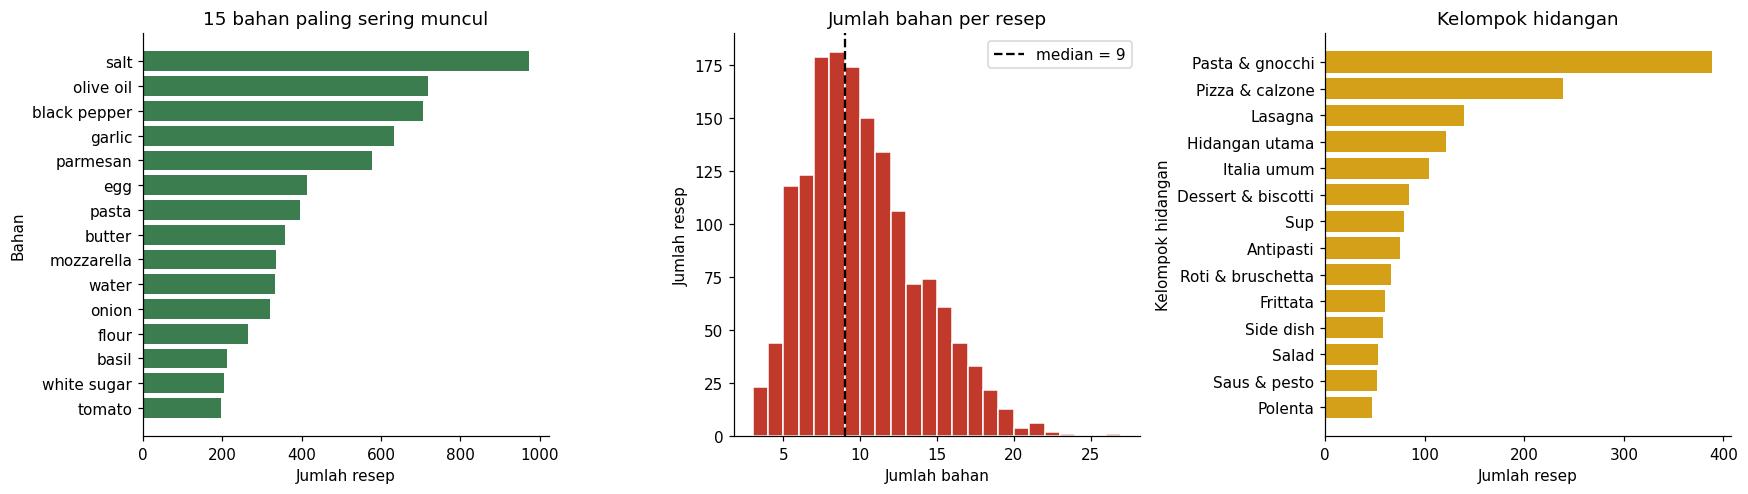

59% istilah bahan hanya muncul di 1 resep (long tail) -> IDF memberi bobot besar ke bahan khas.


In [28]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))

top = pd.Series(dict(ingredient_frequency.most_common(15))).sort_values()
axes[0].barh(top.index, top.values, color="#3b7d4f")
axes[0].set_title("15 bahan paling sering muncul")
axes[0].set_xlabel("Jumlah resep")
axes[0].set_ylabel("Bahan")

axes[1].hist(recipes["ingredient_count"], bins=range(3, 28), color="#c0392b", edgecolor="white")
axes[1].axvline(recipes["ingredient_count"].median(), color="black", ls="--",
                label=f"median = {recipes['ingredient_count'].median():.0f}")
axes[1].set_title("Jumlah bahan per resep")
axes[1].set_xlabel("Jumlah bahan")
axes[1].set_ylabel("Jumlah resep")
axes[1].legend()

DISH_GROUPS = [
    ("Pizza & calzone", r"pizza|calzone"), ("Lasagna", r"lasagna"),
    ("Pasta & gnocchi", r"spaghetti|fettucc|linguine|ziti|manicotti|pasta|carbonara|primavera|gnocchi"),
    ("Saus & pesto", r"pesto|sauce"), ("Sup", r"soup|stew"), ("Salad", r"salad"),
    ("Dessert & biscotti", r"dessert|biscotti"), ("Roti & bruschetta", r"bread|bruschetta"),
    ("Antipasti", r"antipast|appetizer"), ("Frittata", r"frittata"),
    ("Hidangan utama", r"meatball|parmesan|main"), ("Polenta", r"polenta"), ("Side dish", r"side"),
]


def dish_group(subcategory):
    return next((name for name, pattern in DISH_GROUPS if re.search(pattern, subcategory, re.I)), "Italia umum")


recipes["dish_group"] = recipes["subcategory"].map(dish_group)
dish_type = recipes["dish_group"].value_counts().sort_values()
axes[2].barh(dish_type.index, dish_type.values, color="#d4a017")
axes[2].set_title("Kelompok hidangan")
axes[2].set_xlabel("Jumlah resep")
axes[2].set_ylabel("Kelompok hidangan")
plt.tight_layout()
plt.show()

share_once = sum(v == 1 for v in ingredient_frequency.values()) / len(ingredient_frequency)
print(f"{share_once:.0%} istilah bahan hanya muncul di 1 resep (long tail) -> IDF memberi bobot besar ke bahan khas.")

In [29]:
# 3.3b Distribusi kelompok hidangan: seimbang atau tidak?
dish_counts = recipes["dish_group"].value_counts()
dish_share = dish_counts / dish_counts.sum()
dish_ratio = dish_counts.max() / dish_counts.min()
dish_entropy = float(-(dish_share * np.log(dish_share)).sum() / np.log(len(dish_share)))   # 1.0 = merata sempurna

dish_table = pd.DataFrame({"Jumlah resep": dish_counts, "Proporsi": dish_share.map("{:.1%}".format)})
display(dish_table)

fair_share = 1 / len(dish_counts)
largest, smallest = dish_counts.idxmax(), dish_counts.idxmin()
is_imbalanced = dish_ratio >= 3
display(Markdown(
    f"**Kesimpulan distribusi kelompok hidangan:** kelompok terbesar adalah *{largest}* ({dish_share.max():.1%}), "
    f"terkecil *{smallest}* ({dish_share.min():.1%}); rasio terbesar:terkecil = {dish_ratio:.1f}:1. "
    f"Jika merata, tiap kelompok kira-kira {fair_share:.1%}. Entropi ternormalisasi = {dish_entropy:.2f} (1.00 = merata). "
    + ("Data **tidak seimbang**: kelompok besar mendominasi sehingga model bisa condong ke kelompok itu. "
       "Karena itu pembagian train/validasi/test distratifikasi menurut `dish_group` agar proporsinya terjaga, "
       "dan kinerja perlu dibaca per kelompok (lihat H4)."
       if is_imbalanced else
       "Distribusi relatif **seimbang**; stratifikasi tetap dipakai agar proporsi terjaga di tiap split.")
))

,Jumlah resep,Proporsi
dish_group,,
Pasta & gnocchi,388,24.8%
Pizza & calzone,239,15.3%
Lasagna,139,8.9%
Hidangan utama,121,7.7%
Italia umum,104,6.6%
Dessert & biscotti,84,5.4%
Sup,79,5.0%
Antipasti,75,4.8%
Roti & bruschetta,66,4.2%


**Kesimpulan distribusi kelompok hidangan:** kelompok terbesar adalah *Pasta & gnocchi* (24.8%), terkecil *Polenta* (3.0%); rasio terbesar:terkecil = 8.3:1. Jika merata, tiap kelompok kira-kira 7.1%. Entropi ternormalisasi = 0.91 (1.00 = merata). Data **tidak seimbang**: kelompok besar mendominasi sehingga model bisa condong ke kelompok itu. Karena itu pembagian train/validasi/test distratifikasi menurut `dish_group` agar proporsinya terjaga, dan kinerja perlu dibaca per kelompok (lihat H4).

### 3.4 Cek angka dan hubungan fitur

Waktu persiapan, waktu memasak, jumlah bahan, dan jumlah langkah diperiksa dengan grafik. `total_time_min` dibuat dari waktu persiapan dan waktu memasak.


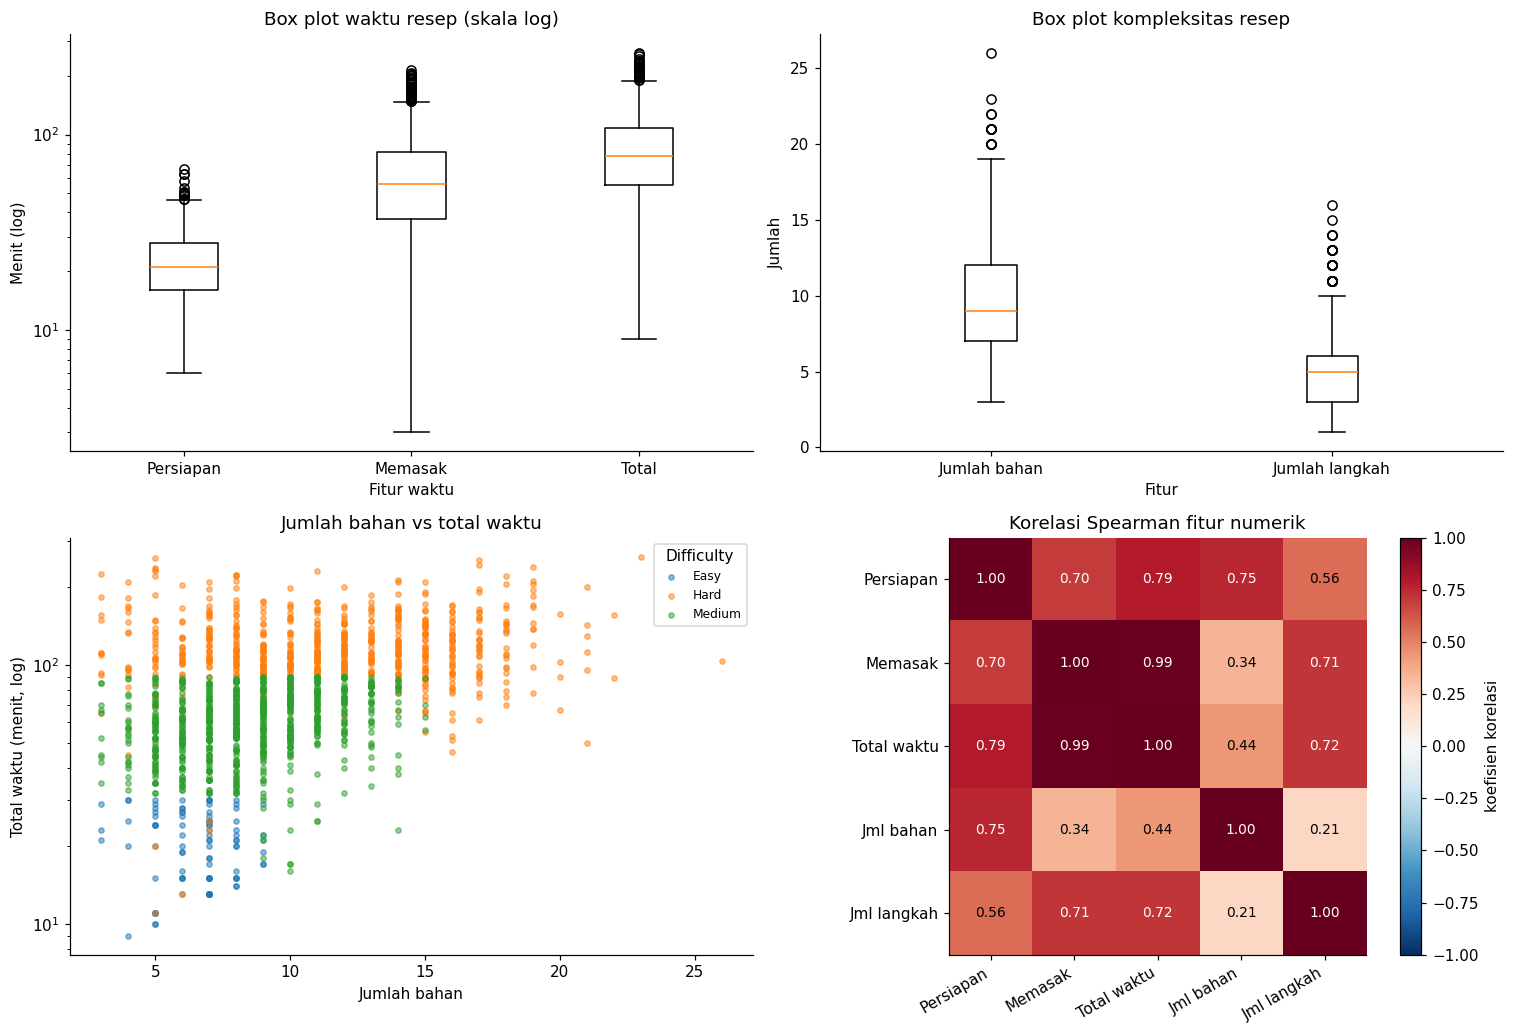

Data kosong pada fitur numerik (%):
est_prep_time_min    0.0
est_cook_time_min    0.0
total_time_min       0.0
ingredient_count     0.0
n_steps              0.0


,min,Q1,median,Q3,max,batas atas IQR,outlier,outlier (%)
Fitur,,,,,,,,
est_prep_time_min,6,16.0,21.0,28.0,67,46.0,16,1.0
est_cook_time_min,3,37.0,56.0,81.0,215,147.0,38,2.4
total_time_min,9,55.0,78.0,108.0,261,187.5,34,2.2
ingredient_count,3,7.0,9.0,12.0,26,19.5,14,0.9
n_steps,1,3.0,5.0,6.0,16,10.5,34,2.2


In [30]:
recipes["n_steps"] = recipes["directions"].map(lambda value: len(parse_list(value)))
recipes["total_time_min"] = recipes["est_prep_time_min"] + recipes["est_cook_time_min"]
recipes["difficulty"] = recipes["difficulty"].fillna("Unknown").astype(str).str.strip().str.title()
TIME_FEATURES = ["est_prep_time_min", "est_cook_time_min", "total_time_min"]
COUNT_FEATURES = ["ingredient_count", "n_steps"]
NUMERIC_FEATURES = TIME_FEATURES + COUNT_FEATURES

fig, axes = plt.subplots(2, 2, figsize=(14, 9.5))

time_data = [recipes[c].dropna() for c in TIME_FEATURES]
axes[0, 0].boxplot(time_data, showfliers=True)
axes[0, 0].set_xticks([1, 2, 3], ["Persiapan", "Memasak", "Total"])
axes[0, 0].set_yscale("log")
axes[0, 0].set_title("Box plot waktu resep (skala log)")
axes[0, 0].set_xlabel("Fitur waktu")
axes[0, 0].set_ylabel("Menit (log)")

axes[0, 1].boxplot([recipes[c] for c in COUNT_FEATURES], showfliers=True)
axes[0, 1].set_xticks([1, 2], ["Jumlah bahan", "Jumlah langkah"])
axes[0, 1].set_title("Box plot kompleksitas resep")
axes[0, 1].set_xlabel("Fitur")
axes[0, 1].set_ylabel("Jumlah")

for level, group in recipes.groupby("difficulty"):
    axes[1, 0].scatter(group["ingredient_count"], group["total_time_min"], s=12, alpha=0.5, label=level)
axes[1, 0].set_yscale("log")
axes[1, 0].set_title("Jumlah bahan vs total waktu")
axes[1, 0].set_xlabel("Jumlah bahan")
axes[1, 0].set_ylabel("Total waktu (menit, log)")
axes[1, 0].legend(title="Difficulty", fontsize=8)

corr = recipes[NUMERIC_FEATURES].corr(method="spearman")   # Spearman: tahan terhadap outlier
image = axes[1, 1].imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
labels = ["Persiapan", "Memasak", "Total waktu", "Jml bahan", "Jml langkah"]
axes[1, 1].set_xticks(range(len(labels)), labels, rotation=30, ha="right")
axes[1, 1].set_yticks(range(len(labels)), labels)
for (r, c), value in np.ndenumerate(corr.to_numpy()):
    axes[1, 1].text(c, r, f"{value:.2f}", ha="center", va="center", fontsize=9,
                    color="white" if abs(value) > 0.6 else "black")
axes[1, 1].set_title("Korelasi Spearman fitur numerik")
fig.colorbar(image, ax=axes[1, 1], label="koefisien korelasi")
plt.tight_layout()
plt.show()

print("Data kosong pada fitur numerik (%):")
print((recipes[NUMERIC_FEATURES].isna().mean() * 100).round(2).to_string())
outlier_report(recipes, NUMERIC_FEATURES)

### 3.4b Skewness

,Skewness,Kurtosis (excess),Interpretasi
est_prep_time_min,0.831,1.040,miring sedang
est_cook_time_min,0.983,1.381,miring sedang
total_time_min,0.874,1.016,miring sedang
ingredient_count,0.650,0.162,miring sedang
n_steps,0.890,1.345,miring sedang


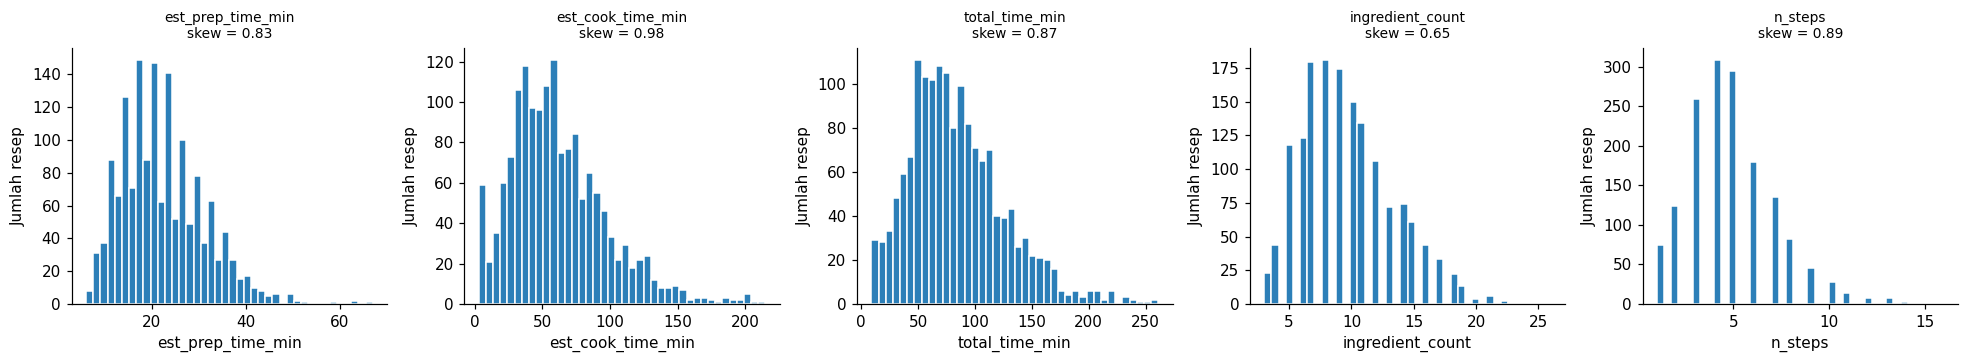

Fitur miring kuat (|skew| >= 1): tidak ada


In [31]:
from scipy.stats import skew, kurtosis

def skew_label(value):
    magnitude = abs(value)
    return "simetris" if magnitude < 0.5 else ("miring sedang" if magnitude < 1 else "miring kuat")

eda_numeric = recipes[NUMERIC_FEATURES]
skew_table = pd.DataFrame({
    "Skewness": [skew(eda_numeric[c].dropna(), bias=False) for c in NUMERIC_FEATURES],
    "Kurtosis (excess)": [kurtosis(eda_numeric[c].dropna(), bias=False) for c in NUMERIC_FEATURES],
}, index=NUMERIC_FEATURES)
skew_table["Interpretasi"] = skew_table["Skewness"].map(skew_label)
display(skew_table.round(3))

fig, axes = plt.subplots(1, len(NUMERIC_FEATURES), figsize=(3.6 * len(NUMERIC_FEATURES), 3.4))
for ax, column in zip(axes, NUMERIC_FEATURES):
    ax.hist(eda_numeric[column].dropna(), bins=40, color="#2c7fb8", edgecolor="white")
    ax.set_title(f"{column}\nskew = {skew_table.loc[column, 'Skewness']:.2f}", fontsize=9)
    ax.set_xlabel(column)
    ax.set_ylabel("Jumlah resep")
plt.tight_layout()
plt.show()

strong_skew = skew_table.index[skew_table["Skewness"].abs() >= 1].tolist()
print("Fitur miring kuat (|skew| >= 1):", ", ".join(strong_skew) if strong_skew else "tidak ada")

**Catatan preprocessing:** nilai ekstrem dibatasi dengan IQR cap. `log1p` dan StandardScaler dipakai agar angka lebih sebanding.


### 3.5 Membagi data dan preprocessing

Resep dibagi setelah duplikat dibuang. Imputer, encoder, dan scaler dipelajari dari train saja, lalu dipakai untuk validasi dan test. Ini mencegah kebocoran data.


In [32]:
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from sklearn.utils.validation import check_is_fitted

# Target resep disjoint, stratified by kelompok hidangan.
all_indices = np.arange(len(recipes))
train_idx, holdout_idx = train_test_split(
    all_indices, test_size=0.40, random_state=RANDOM_STATE,
    stratify=recipes["dish_group"],
)
val_idx, test_idx = train_test_split(
    holdout_idx, test_size=0.50, random_state=RANDOM_STATE,
    stratify=recipes.loc[holdout_idx, "dish_group"],
)
assert not set(train_idx) & set(val_idx)
assert not set(train_idx) & set(test_idx)
assert not set(val_idx) & set(test_idx)
assert len(set(train_idx) | set(val_idx) | set(test_idx)) == len(recipes)
print(f"Target resep: train={len(train_idx)}, validasi={len(val_idx)}, test={len(test_idx)}")
print("Tidak ada irisan target antarsplit.")

class GroupTimeImputer(BaseEstimator, TransformerMixin):
    def __init__(self, columns=("est_prep_time_min", "est_cook_time_min"), group="dish_group"):
        self.columns = columns
        self.group = group

    def fit(self, X, y=None):
        X = X.copy()
        self.global_medians_ = X[list(self.columns)].median()
        self.group_medians_ = X.groupby(self.group, dropna=False)[list(self.columns)].median()
        if self.global_medians_.isna().any():
            raise ValueError("Kolom waktu seluruhnya kosong di train; fallback median tidak terdefinisi.")
        return self

    def transform(self, X):
        check_is_fitted(self, ["global_medians_", "group_medians_"])
        result = X.copy()
        for column in self.columns:
            result[column] = (
                result[column]
                .fillna(result[self.group].map(self.group_medians_[column]))
                .fillna(self.global_medians_[column])
            )
        if "total_time_min" in result:
            result["total_time_min"] = result["est_prep_time_min"] + result["est_cook_time_min"]
        return result

class IQRCapper(BaseEstimator, TransformerMixin):
    def __init__(self, factor=1.5):
        self.factor = factor

    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)
        q1, q3 = np.nanpercentile(X, [25, 75], axis=0)
        self.lower_ = np.maximum(q1 - self.factor * (q3 - q1), 0)
        self.upper_ = q3 + self.factor * (q3 - q1)
        return self

    def transform(self, X):
        check_is_fitted(self, ["lower_", "upper_"])
        return np.clip(np.asarray(X, dtype=float), self.lower_, self.upper_)

recipes["time_imputed"] = recipes[TIME_COLUMNS].isna().any(axis=1)
CATEGORICAL_FEATURES = ["dish_group", "difficulty"]
time_imputer = GroupTimeImputer().fit(recipes.iloc[train_idx])
imputed_recipes = time_imputer.transform(recipes)

numeric_pipeline = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("cap_outlier", IQRCapper(factor=1.5)),
    ("log", FunctionTransformer(np.log1p)),
    ("scale", StandardScaler()),
])
categorical_pipeline = Pipeline([
    ("impute", SimpleImputer(strategy="constant", fill_value="Unknown")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])
tabular_preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, NUMERIC_FEATURES),
    ("cat", categorical_pipeline, CATEGORICAL_FEATURES),
])
tabular_preprocessor.fit(imputed_recipes.iloc[train_idx][NUMERIC_FEATURES + CATEGORICAL_FEATURES])
tabular_matrix = tabular_preprocessor.transform(imputed_recipes[NUMERIC_FEATURES + CATEGORICAL_FEATURES])
onehot_names = tabular_preprocessor.named_transformers_["cat"].named_steps["onehot"].get_feature_names_out(CATEGORICAL_FEATURES)
tabular_features = pd.DataFrame(tabular_matrix, columns=NUMERIC_FEATURES + list(onehot_names), index=recipes.index)
assert np.isfinite(tabular_matrix).all()

# Uji input baru: satu resep seluruh waktunya kosong dan kelompok tak dikenal.
new_recipe = recipes.iloc[[train_idx[0]]].copy()
new_recipe[TIME_COLUMNS] = np.nan
new_recipe["dish_group"] = "__kelompok_baru__"
new_imputed = time_imputer.transform(new_recipe)
assert new_imputed[TIME_COLUMNS].notna().all().all()
assert np.allclose(new_imputed[TIME_COLUMNS].iloc[0], time_imputer.global_medians_)
print("Uji imputasi input baru tak dikenal: LULUS (median global train).")
print(f"Matriks awal: {tabular_features.shape[0]} x {tabular_features.shape[1]} "
      f"({len(NUMERIC_FEATURES)} numerik + {len(onehot_names)} one-hot)")
print("Ringkasan berikut khusus train; mean/std holdout tidak dipaksa sama dengan train.")
display(tabular_features.iloc[train_idx][NUMERIC_FEATURES].describe().T[["mean","std","min","max"]].round(3))


Target resep: train=939, validasi=313, test=313
Tidak ada irisan target antarsplit.
Uji imputasi input baru tak dikenal: LULUS (median global train).
Matriks awal: 1565 x 22 (5 numerik + 17 one-hot)
Ringkasan berikut khusus train; mean/std holdout tidak dipaksa sama dengan train.


,mean,std,min,max
est_prep_time_min,0.0,1.001,-3.113,2.122
est_cook_time_min,0.0,1.001,-3.586,1.517
total_time_min,-0.0,1.001,-3.683,1.740
ingredient_count,0.0,1.001,-2.637,2.048
n_steps,0.0,1.001,-2.440,1.875


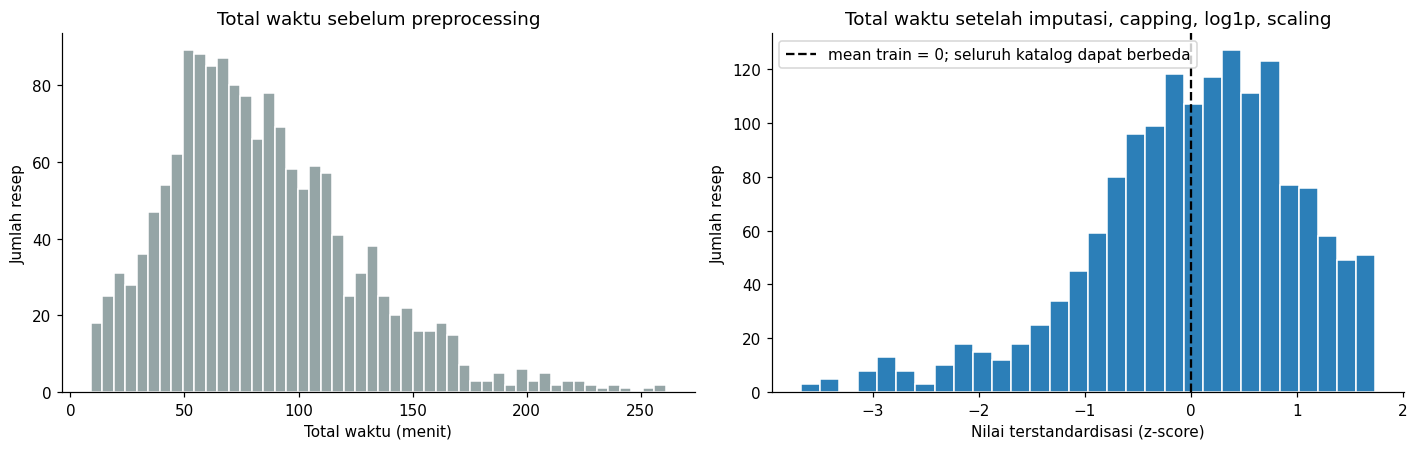

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
axes[0].hist(recipes["total_time_min"], bins=50, color="#95a5a6", edgecolor="white")
axes[0].set_title("Total waktu sebelum preprocessing")
axes[0].set_xlabel("Total waktu (menit)")
axes[0].set_ylabel("Jumlah resep")

axes[1].hist(tabular_features["total_time_min"], bins=30, color="#2c7fb8", edgecolor="white")
axes[1].axvline(0, color="black", ls="--", label="mean train = 0; seluruh katalog dapat berbeda")
axes[1].set_title("Total waktu setelah imputasi, capping, log1p, scaling")
axes[1].set_xlabel("Nilai terstandardisasi (z-score)")
axes[1].set_ylabel("Jumlah resep")
axes[1].legend()
plt.tight_layout()
plt.show()


### 3.5b Skewness sebelum dan sesudah preprocessing

,Skew sebelum,Skew sesudah (cap + log1p + scale)
est_prep_time_min,0.696,-0.184
est_cook_time_min,0.995,-1.390
total_time_min,0.857,-0.763
ingredient_count,0.586,-0.213
n_steps,0.922,-0.492


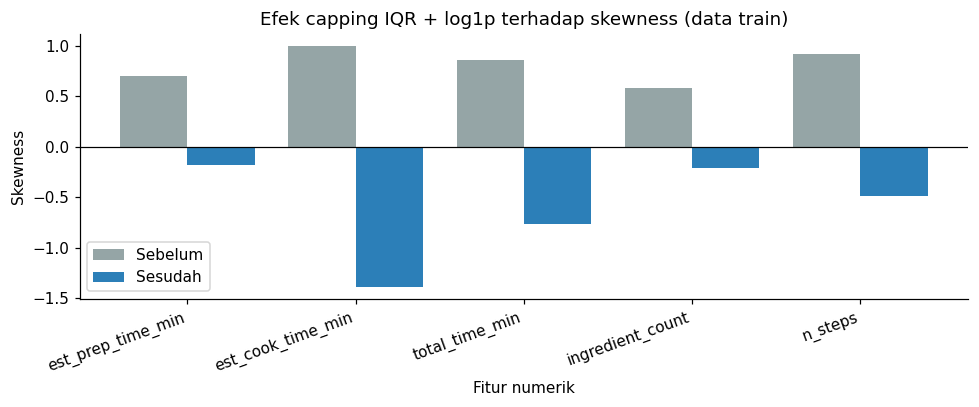

In [34]:
from scipy.stats import skew

raw_train = imputed_recipes.iloc[train_idx][NUMERIC_FEATURES]
processed_train = tabular_features.iloc[train_idx][NUMERIC_FEATURES]
skew_compare = pd.DataFrame({
    "Skew sebelum": [skew(raw_train[c], bias=False) for c in NUMERIC_FEATURES],
    "Skew sesudah (cap + log1p + scale)": [skew(processed_train[c], bias=False) for c in NUMERIC_FEATURES],
}, index=NUMERIC_FEATURES)
display(skew_compare.round(3))

fig, ax = plt.subplots(figsize=(9, 3.8))
positions = np.arange(len(NUMERIC_FEATURES))
ax.bar(positions - 0.2, skew_compare["Skew sebelum"], 0.4, color="#95a5a6", label="Sebelum")
ax.bar(positions + 0.2, skew_compare["Skew sesudah (cap + log1p + scale)"], 0.4, color="#2c7fb8", label="Sesudah")
ax.axhline(0, color="black", lw=0.8)
ax.set_xticks(positions, NUMERIC_FEATURES, rotation=20, ha="right")
ax.set_xlabel("Fitur numerik")
ax.set_ylabel("Skewness")
ax.set_title("Efek capping IQR + log1p terhadap skewness (data train)")
ax.legend()
plt.tight_layout()
plt.show()

### 3.6 Rencana pemodelan dan evaluasi

Bagian ini merangkum pendekatan sebelum model dibuat, agar pembaca tahu apa yang diuji, dengan apa, dan bagaimana dinilai.

| Komponen | Rencana |
|---|---|
| **Pendekatan masalah** | *Retrieval + re-ranking.* Pengguna memasukkan bahan; sistem mencari resep Italia dengan bahan paling mirip (M0-M3), lalu M4 mengurutkan ulang 50 kandidat teratas M3 dengan model machine learning. Jawaban benar adalah resep asal query. |
| **Algoritma** | Retrieval: hitung bahan sama (M0), variasi pencocokan bahan (M1-M2), TF-IDF + cosine similarity (M3). Re-ranking M4: Logistic Regression, Random Forest, HistGradientBoosting, XGBoost. Pembanding tambahan: ExtraTrees dan XGBRanker (Learning-to-Rank). |
| **Pembagian data** | Resep dibagi 60% train, 20% validasi, 20% test, distratifikasi menurut kelompok hidangan, dan target antar-split tidak beririsan (diuji dengan `assert`). Validasi dipakai memilih M3; test hanya untuk evaluasi akhir. |
| **Metrik ranking** | HitRate@5 (utama), HitRate@10, MRR@10, NDCG@10: apakah dan seberapa tinggi resep yang benar muncul. |
| **Metrik klasifikasi (M4)** | PR-AUC (utama), ROC-AUC, Precision, Recall, F1 pada pasangan query-kandidat. Ambang keputusan dipilih dari prediksi out-of-fold yang memaksimalkan F1, bukan dari test. |
| **Validasi model** | `StratifiedGroupKFold` 4 lipatan dengan grup = resep target (resep yang sama tidak pernah ada di train dan validasi sekaligus), plus skenario query tertahan agar model diuji pada pola query yang belum dilihat. |
| **Tuning** | Grid Search dan Bayesian Optimization (Optuna, TPE) dengan fold dan metrik yang sama, supaya perbandingan adil. |

**Mengapa accuracy bukan metrik utama.** Pada data kandidat, hanya satu dari sekitar 50 kandidat per query yang benar (lihat 6.1b). Model yang selalu menjawab "bukan resep asal" sudah memperoleh accuracy sangat tinggi tanpa berguna sama sekali. Karena itu metrik utama adalah HitRate@5 dan PR-AUC, yang menilai kemampuan menempatkan resep yang benar di urutan atas. Accuracy tetap dilaporkan sebagai pembanding di bagian 6.3, bersama baseline "selalu prediksi 0".

## 4. Membuat model

M0-M3 mencari resep dari kemiripan bahan. M4 adalah model tambahan yang mengurutkan kembali kandidat dari M3.

- M0: hitung bahan yang sama.
- M1-M2: variasi pencocokan bahan.
- M3: pencocokan teks bahan dengan cosine similarity.
- M4: classifier untuk mengurutkan ulang kandidat M3.


In [35]:
import numpy as np
GENERIC_WORDS = {
    "pepper", "sauce", "oil", "cheese", "powder", "juice", "seasoning", "vinegar", "broth",
    "stock", "paste", "extract", "flake", "seed", "leaf", "mix", "dressing", "crumb", "zest", "wine",
}
STAPLES = {"salt", "black pepper", "water", "cooking spray"}


def ingredient_keys(name):
    """Kunci pencocokan lunak: nama lengkap + akhiran katanya ('yellow onion' -> {'yellow onion', 'onion'})."""
    words = name.split()
    keys = {" ".join(words[i:]) for i in range(len(words))}
    return {key for key in keys if key not in GENERIC_WORDS}


def to_features(ingredients, mode, drop_staples):
    items = [item for item in ingredients if not (drop_staples and item in STAPLES)]
    if mode == "ingredient":
        return items
    words = [f"w_{word}" for item in items for word in item.split()]
    return words if mode == "word" else items + words


class ItalianRecipeRecommender:
    """Content-Based Filtering: TF-IDF bahan + Cosine Similarity, opsional ditambah skor kelengkapan bahan."""

    def __init__(self, mode="both", use_idf=True, drop_staples=False, alpha=1.0):
        self.mode, self.use_idf, self.drop_staples, self.alpha = mode, use_idf, drop_staples, alpha

    def _analyzer(self, ingredients):
        return to_features(ingredients, self.mode, self.drop_staples)

    def fit(self, recipe_ingredients):
        self.recipes_ = [list(items) for items in recipe_ingredients]
        self.vectorizer_ = TfidfVectorizer(
            analyzer=self._analyzer, use_idf=self.use_idf, sublinear_tf=True, norm="l2"
        )
        self.item_matrix_ = self.vectorizer_.fit_transform(self.recipes_)
        vocab = sorted({item for items in self.recipes_ for item in items})
        self.ingredient_index_ = {item: i for i, item in enumerate(vocab)}
        keys = sorted({key for item in vocab for key in ingredient_keys(item)})
        self.key_index_ = {key: i for i, key in enumerate(keys)}
        rows, cols = [], []
        for item, i in self.ingredient_index_.items():
            for key in ingredient_keys(item):
                rows.append(i); cols.append(self.key_index_[key])
        self.ingredient_keys_ = csr_matrix((np.ones(len(rows)), (rows, cols)), shape=(len(vocab), len(keys)))
        rows, cols = [], []
        for r, items in enumerate(self.recipes_):
            for item in set(items):
                rows.append(r); cols.append(self.ingredient_index_[item])
        self.recipe_ingredients_ = csr_matrix((np.ones(len(rows)), (rows, cols)), shape=(len(self.recipes_), len(vocab)))
        self.recipe_lengths_ = np.asarray(self.recipe_ingredients_.sum(axis=1)).ravel()
        return self

    def coverage(self, queries):
        """Proporsi bahan resep yang sudah dimiliki pengguna (pencocokan lunak), bentuk (n_query, n_resep)."""
        rows, cols = [], []
        for q, items in enumerate(queries):
            for key in {k for item in items for k in ingredient_keys(item)}:
                if key in self.key_index_:
                    rows.append(q); cols.append(self.key_index_[key])
        query_keys = csr_matrix((np.ones(len(rows)), (rows, cols)), shape=(len(queries), len(self.key_index_)))
        available = (query_keys @ self.ingredient_keys_.T) > 0
        covered = (available.astype(float) @ self.recipe_ingredients_.T).toarray()
        return covered / self.recipe_lengths_

    def score(self, queries):
        similarity = (self.vectorizer_.transform(queries) @ self.item_matrix_.T).toarray()
        if self.alpha >= 1:
            return similarity
        return self.alpha * similarity + (1 - self.alpha) * self.coverage(queries)

    def recommend(self, ingredients, k=5):
        scores = self.score([ingredients])[0]
        top = np.argsort(-scores)[:k]
        coverage = self.coverage([ingredients])[0]
        return [(int(i), float(scores[i]), float(coverage[i])) for i in top]

### 4.1 Cara menguji pencarian resep

Karena tidak ada data pengguna asli, query dibuat dari sebagian bahan resep target dan sedikit bahan gangguan. Jawaban benar adalah resep asal query.

Katalog resep boleh diketahui oleh sistem. Namun resep target train, validasi, dan test tetap dipisahkan. Hasil ini belum menguji resep baru atau pengguna baru.


In [36]:
recipe_ingredients = recipes["ingredient_list"].tolist()
vocab = np.array(sorted(ingredient_frequency))
vocab_set = set(vocab)
vocab_prob = np.array([ingredient_frequency[item] for item in vocab], dtype=float)
vocab_prob /= vocab_prob.sum()


def generalize(item):
    """Nama bahan versi umum, seperti yang biasa diketik pengguna."""
    words = item.split()
    suffixes = [" ".join(words[i:]) for i in range(1, len(words))]
    suffixes = [s for s in suffixes if s in vocab_set and s not in GENERIC_WORDS]
    return suffixes[-1] if suffixes else item


def make_queries(indices, keep=0.5, n_noise=2, p_general=0.5, seed=0):
    rng = np.random.default_rng(seed)
    queries = []
    for i in indices:
        items = recipe_ingredients[i]
        n_keep = min(len(items), max(2, int(round(len(items) * keep))))
        query = [str(x) for x in rng.choice(items, n_keep, replace=False)]
        query = [generalize(x) if rng.random() < p_general else x for x in query]
        while len(query) < n_keep + n_noise:
            candidate = str(rng.choice(vocab, p=vocab_prob))
            if candidate not in items and candidate not in query:
                query.append(candidate)
        queries.append(list(dict.fromkeys(query)))
    return queries


print(f"Train: {len(train_idx)} | Validasi tuning: {len(val_idx)} | Test final: {len(test_idx)}")
print("Contoh query realistis:")
for q, i in zip(make_queries(val_idx[:3], seed=1), val_idx[:3]):
    print(f"  target = {recipes.loc[i, 'recipe_title']!r}\n  isi dapur = {q}")


Train: 939 | Validasi tuning: 313 | Test final: 313
Contoh query realistis:
  target = 'Crispy Zucchini or Pumpkin Blossoms'
  isi dapur = ['egg', 'parmesan', 'pumpkin', 'basil', 'olive oil', 'red pepper flake']
  target = 'Spaghetti Cacio e Pepe'
  isi dapur = ['black pepper', 'pecorino romano cheese', 'flat leaf parsley', 'leaves sage']
  target = 'The Best Pizza Crust'
  isi dapur = ['salt', 'yeast', 'sugar', 'water', 'processed cheese food', 'olive oil']


In [37]:
def ranking_metrics(top_indices, targets, k=10):
    hits = np.asarray(top_indices)[:, :k] == np.asarray(targets)[:, None]
    found = hits.any(axis=1)
    rank = np.where(found, hits.argmax(axis=1) + 1, np.inf)
    return {
        "HitRate@5": np.mean(rank <= 5),
        "HitRate@10": np.mean(found),
        "MRR@10": np.mean(np.where(found, 1 / rank, 0)),
        "NDCG@10": np.mean(np.where(found, 1 / np.log2(rank + 1), 0)),
    }


def top_k(scores, k=10):
    return np.argsort(-scores, axis=1)[:, :k]


# M0 & M1: representasi biner per bahan
binarizer = MultiLabelBinarizer(classes=vocab)
recipe_binary = binarizer.fit_transform(recipe_ingredients).astype(bool)


def binary_queries(queries):
    return binarizer.transform([[x for x in q if x in vocab_set] for q in queries]).astype(bool)


def overlap_top_k(queries, k=10):
    shared = binary_queries(queries).astype(float) @ recipe_binary.T.astype(float)
    return top_k(shared - 1e-3 * recipe_binary.sum(axis=1), k)   # seri -> resep lebih ringkas di depan


knn_jaccard = NearestNeighbors(metric="jaccard", algorithm="brute").fit(recipe_binary)


def knn_jaccard_top_k(queries, k=10):
    return knn_jaccard.kneighbors(binary_queries(queries), n_neighbors=k, return_distance=False)


m2_default = ItalianRecipeRecommender(mode="ingredient", use_idf=True, drop_staples=False, alpha=1.0)
m2_default.fit(recipe_ingredients)
print("Model M0, M1, M2 siap. Dimensi TF-IDF M2:", m2_default.item_matrix_.shape)

Model M0, M1, M2 siap. Dimensi TF-IDF M2: (1565, 1628)


### 4.2 Memilih konfigurasi M3

M3 diuji pada 48 konfigurasi menggunakan data validasi dan tiga seed. Konfigurasi dengan NDCG@10 terbaik dipakai untuk tahap berikutnya.

Nama lama `M3 TF-IDF + Cosine (teroptimasi)` tetap ada pada beberapa tabel untuk menjaga kesinambungan dengan notebook tim. Konfigurasi yang benar harus dilihat dari `best_params` pada output.


In [38]:
# Query validasi dibuat dengan 3 seed berbeda lalu dirata-rata, agar pilihan parameter tidak kebetulan
val_query_sets = [make_queries(val_idx, keep=0.5, p_general=0.5, seed=s) for s in (1, 2, 3)]
grid = list(itertools.product(["ingredient", "word", "both"], [False, True], [False, True], [1.0, 0.8, 0.6, 0.4]))
rows = []
for mode, use_idf, drop_staples, alpha in grid:
    model = ItalianRecipeRecommender(mode, use_idf, drop_staples, alpha).fit(recipe_ingredients)
    scores = [ranking_metrics(top_k(model.score(q)), val_idx) for q in val_query_sets]
    rows.append({"mode": mode, "use_idf": use_idf, "drop_staples": drop_staples, "alpha": alpha,
                 **pd.DataFrame(scores).mean().to_dict()})
grid_results = pd.DataFrame(rows).sort_values(["NDCG@10", "HitRate@5"], ascending=False).reset_index(drop=True)
best_params = grid_results.iloc[0][["mode", "use_idf", "drop_staples", "alpha"]].to_dict()
best_params = {"mode": best_params["mode"], "use_idf": bool(best_params["use_idf"]),
               "drop_staples": bool(best_params["drop_staples"]), "alpha": float(best_params["alpha"])}
print(f"{len(grid)} kombinasi diuji. Parameter terbaik: {best_params}")
grid_results.head(8).round(3)

48 kombinasi diuji. Parameter terbaik: {'mode': 'both', 'use_idf': False, 'drop_staples': False, 'alpha': 1.0}


,mode,use_idf,drop_staples,alpha,HitRate@5,HitRate@10,MRR@10,NDCG@10
0,both,False,False,1.0,0.814,0.875,0.685,0.731
1,both,True,False,0.6,0.802,0.868,0.665,0.714
2,both,True,False,0.8,0.786,0.851,0.668,0.712
3,both,False,False,0.8,0.803,0.869,0.661,0.711
4,both,True,True,0.6,0.798,0.862,0.661,0.710
5,both,False,True,1.0,0.786,0.840,0.665,0.708
6,both,False,True,0.8,0.802,0.849,0.661,0.707
7,ingredient,True,False,0.6,0.785,0.862,0.655,0.705


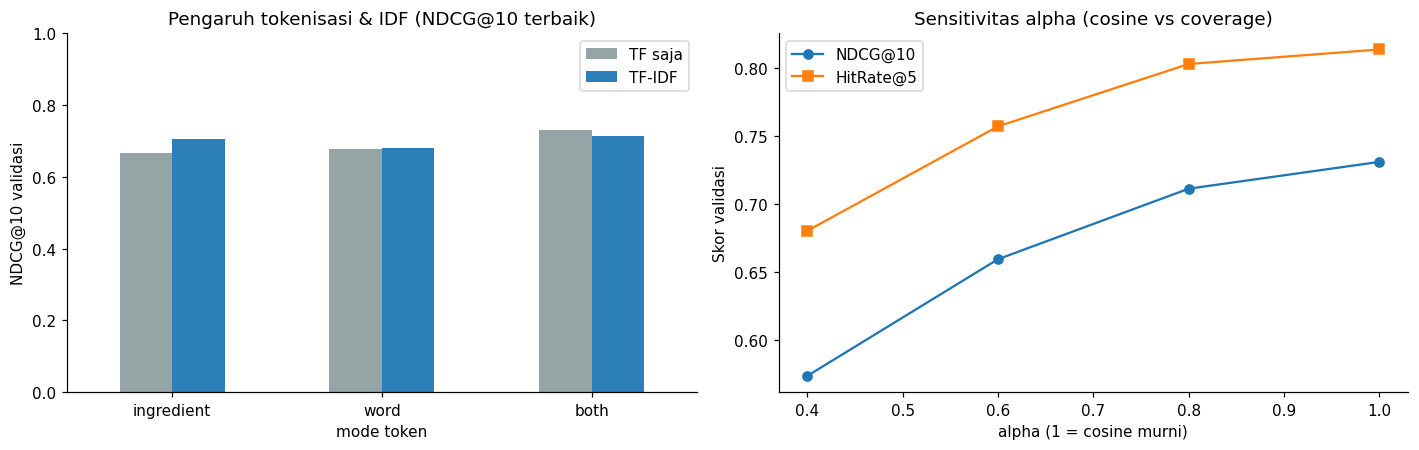

In [39]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
pivot = grid_results.groupby(["mode", "use_idf"])["NDCG@10"].max().unstack()
pivot.columns = ["TF saja", "TF-IDF"]
pivot.loc[["ingredient", "word", "both"]].plot.bar(ax=axes[0], color=["#95a5a6", "#2c7fb8"], rot=0)
axes[0].set_title("Pengaruh tokenisasi & IDF (NDCG@10 terbaik)")
axes[0].set_ylim(0, 1)
axes[0].set_ylabel("NDCG@10 validasi")
axes[0].set_xlabel("mode token")

best_mode = grid_results[(grid_results["mode"] == best_params["mode"])
                         & (grid_results["use_idf"] == best_params["use_idf"])
                         & (grid_results["drop_staples"] == best_params["drop_staples"])].sort_values("alpha")
axes[1].plot(best_mode["alpha"], best_mode["NDCG@10"], marker="o", label="NDCG@10")
axes[1].plot(best_mode["alpha"], best_mode["HitRate@5"], marker="s", label="HitRate@5")
axes[1].set_title("Sensitivitas alpha (cosine vs coverage)")
axes[1].set_xlabel("alpha (1 = cosine murni)")
axes[1].set_ylabel("Skor validasi")
axes[1].legend()
plt.tight_layout()
plt.show()


In [40]:
m3_best = ItalianRecipeRecommender(**best_params).fit(recipe_ingredients)

MODELS = {
    "M0 Baseline Overlap": overlap_top_k,
    "M1 KNN-Jaccard": knn_jaccard_top_k,
    "M2 TF-IDF + Cosine (default)": lambda q, k=10: top_k(m2_default.score(q), k),
    "M3 TF-IDF + Cosine (teroptimasi)": lambda q, k=10: top_k(m3_best.score(q), k),
}

## 5. Evaluasi awal dan statistik (Q2)

Bagian ini memakai data train, bukan test akhir. Hasilnya membantu memahami model, tetapi tidak dipakai sebagai nilai hasil final.


In [41]:
coverage_helper = ItalianRecipeRecommender(mode="ingredient").fit(recipe_ingredients)
recipe_sizes = recipes["ingredient_count"].to_numpy()


def relevance_metrics(queries, top_indices, k=5):
    coverage = coverage_helper.coverage(queries)
    top = np.asarray(top_indices)[:, :k]
    cov = np.take_along_axis(coverage, top, axis=1)
    missing = np.round((1 - cov) * recipe_sizes[top])
    return {"Coverage@5": cov.mean(), "Missing@5": missing.mean()}


scenarios = {
    "Realistis (nama umum + noise)": make_queries(train_idx, keep=0.5, p_general=0.5, seed=7),
    "Ideal (nama persis + noise)": make_queries(train_idx, keep=0.5, p_general=0.0, seed=7),
}
rows = []
for scenario, queries in scenarios.items():
    for name, recommend in MODELS.items():
        top = recommend(queries)
        rows.append({"Skenario": scenario, "Model": name,
                     **ranking_metrics(top, train_idx), **relevance_metrics(queries, top)})
development_results = pd.DataFrame(rows)
development_results.set_index(["Skenario", "Model"]).round(3)


HitRate@5  \
Skenario                      Model                                         
Realistis (nama umum + noise) M0 Baseline Overlap                   0.717   
                              M1 KNN-Jaccard                        0.731   
                              M2 TF-IDF + Cosine (default)          0.727   
                              M3 TF-IDF + Cosine (teroptimasi)      0.771   
Ideal (nama persis + noise)   M0 Baseline Overlap                   0.858   
                              M1 KNN-Jaccard                        0.885   
                              M2 TF-IDF + Cosine (default)          0.869   
                              M3 TF-IDF + Cosine (teroptimasi)      0.862   

                                                                HitRate@10  \
Skenario                      Model                                          
Realistis (nama umum + noise) M0 Baseline Overlap                    0.785   
                              M1 KNN-Jaccard                         0.806   
                              M2 TF-IDF + Cosine (default)           0.806   
                              M3 TF-IDF + Cosine (teroptimasi)       0.852   
Ideal (nama persis + noise)   M0 Baseline Overlap                    0.902   
                              M1 KNN-Jaccard                         0.939   
                              M2 TF-IDF + Cosine (default)           0.917   
                              M3 TF-IDF + Cosine (teroptimasi)       0.911   

                                                                MRR@10  \
Skenario                      Model                                      
Realistis (nama umum + noise) M0 Baseline Overlap                0.606   
                              M1 KNN-Jaccard                     0.591   
                              M2 TF-IDF + Cosine (default)       0.620   
                              M3 TF-IDF + Cosine (teroptimasi)   0.646   
Ideal (nama persis + noise)   M0 Baseline Overlap                0.770   
                              M1 KNN-Jaccard                     0.779   
                              M2 TF-IDF + Cosine (default)       0.781   
                              M3 TF-IDF + Cosine (teroptimasi)   0.766   

                                                                NDCG@10  \
Skenario                      Model                                       
Realistis (nama umum + noise) M0 Baseline Overlap                 0.649   
                              M1 KNN-Jaccard                      0.643   
                              M2 TF-IDF + Cosine (default)        0.665   
                              M3 TF-IDF + Cosine (teroptimasi)    0.696   
Ideal (nama persis + noise)   M0 Baseline Overlap                 0.802   
                              M1 KNN-Jaccard                      0.818   
                              M2 TF-IDF + Cosine (default)        0.814   
                              M3 TF-IDF + Cosine (teroptimasi)    0.801   

                                                                Coverage@5  \
Skenario                      Model                                          
Realistis (nama umum + noise) M0 Baseline Overlap                    0.415   
                              M1 KNN-Jaccard                         0.487   
                              M2 TF-IDF + Cosine (default)           0.402   
                              M3 TF-IDF + Cosine (teroptimasi)       0.473   
Ideal (nama persis + noise)   M0 Baseline Overlap                    0.418   
                              M1 KNN-Jaccard                         0.487   
                              M2 TF-IDF + Cosine (default)           0.410   
                              M3 TF-IDF + Cosine (teroptimasi)       0.473   

                                                                Missing@5  
Skenario                      Model                                        
Realistis (nama umum + noise) M0 Baseline Overlap                   6.759  
           

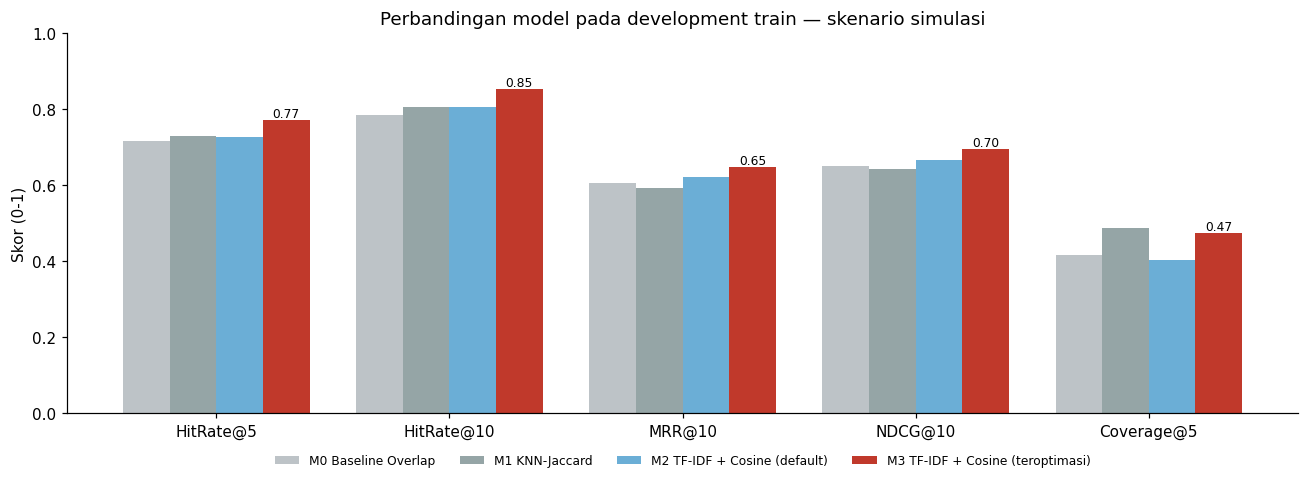

In [42]:
realistic = development_results[development_results["Skenario"].str.startswith("Realistis")].set_index("Model")
metrics_to_plot = ["HitRate@5", "HitRate@10", "MRR@10", "NDCG@10", "Coverage@5"]
colors = ["#bdc3c7", "#95a5a6", "#6baed6", "#c0392b"]

fig, ax = plt.subplots(figsize=(12, 4.5))
width = 0.2
x = np.arange(len(metrics_to_plot))
for i, (name, row) in enumerate(realistic[metrics_to_plot].iterrows()):
    bars = ax.bar(x + (i - 1.5) * width, row.values, width, label=name, color=colors[i])
    if i == 3:
        ax.bar_label(bars, fmt="%.2f", fontsize=8)
ax.set_xticks(x, metrics_to_plot)
ax.set_ylim(0, 1)
ax.set_ylabel("Skor (0-1)")
ax.set_title("Perbandingan model pada development train — skenario simulasi")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=4, fontsize=8, frameon=False)
plt.tight_layout()
plt.show()


### 5.1 Pengaruh jumlah bahan pada hasil


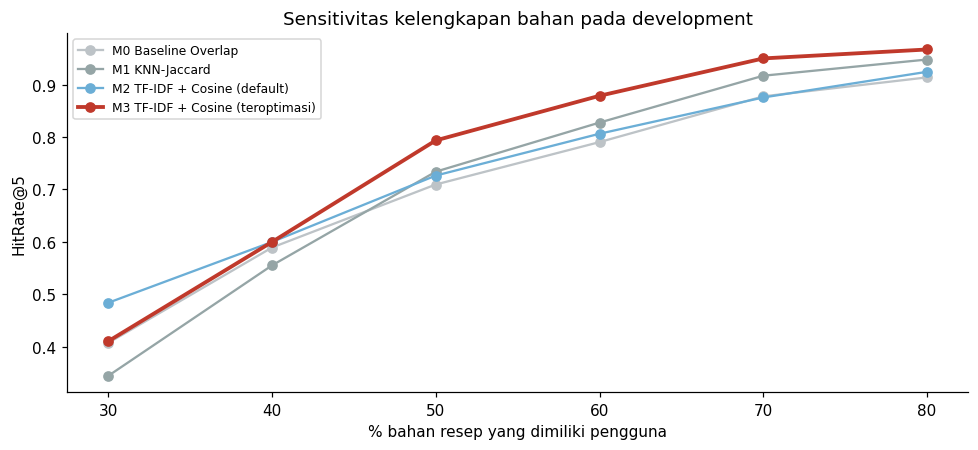

Model,M0 Baseline Overlap,M1 KNN-Jaccard,M2 TF-IDF + Cosine (default),M3 TF-IDF + Cosine (teroptimasi)
keep,,,,
0.3,0.407,0.344,0.483,0.410
0.4,0.589,0.555,0.600,0.600
0.5,0.709,0.734,0.726,0.793
0.6,0.790,0.827,0.806,0.879
0.7,0.878,0.917,0.875,0.950
0.8,0.914,0.948,0.924,0.967


In [43]:
keep_levels = [0.3, 0.4, 0.5, 0.6, 0.7, 0.8]
rows = []
for keep in keep_levels:
    queries = make_queries(train_idx, keep=keep, p_general=0.5, seed=11)
    for name, recommend in MODELS.items():
        rows.append({"keep": keep, "Model": name, **ranking_metrics(recommend(queries), train_idx)})
robustness = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(9, 4.2))
for color, (name, group) in zip(colors, robustness.groupby("Model", sort=False)):
    ax.plot(group["keep"] * 100, group["HitRate@5"], marker="o", label=name, color=color,
            lw=2.5 if name.startswith("M3") else 1.5)
ax.set_xlabel("% bahan resep yang dimiliki pengguna")
ax.set_ylabel("HitRate@5")
ax.set_title("Sensitivitas kelengkapan bahan pada development")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()
robustness.pivot(index="keep", columns="Model", values="HitRate@5").round(3)


### 5.2 Mengapa rekomendasi berhasil atau gagal

Setiap query train diberi label berhasil bila resep target masuk Top-5. Analisis ini menunjukkan hubungan di data, bukan sebab-akibat.


In [44]:
queries = scenarios["Realistis (nama umum + noise)"]
top5 = MODELS["M3 TF-IDF + Cosine (teroptimasi)"](queries, k=5)
n_recipes = len(recipe_ingredients)
idf = {item: np.log(n_recipes / count) for item, count in ingredient_frequency.items()}

rows = []
for query, target, recommended in zip(queries, train_idx, top5):
    target_keys = {key for item in recipe_ingredients[target] for key in ingredient_keys(item)}
    matched = [item for item in query if ingredient_keys(item) & target_keys]
    rows.append({
        "Status": "Berhasil Top-5" if target in recommended else "Gagal",
        "Bahan target di dapur": len(matched),
        "Total bahan resep target": len(recipe_ingredients[target]),
        "Kekhasan bahan (rata-rata IDF)": np.mean([idf.get(item, 0) for item in matched]) if matched else 0,
        "Porsi bumbu dasar di query": np.mean([item in STAPLES for item in query]),
    })
error_analysis = pd.DataFrame(rows)
print(error_analysis["Status"].value_counts().to_string())
error_analysis.groupby("Status").mean().T.round(2)


Status
Berhasil Top-5    724
Gagal             215


Status,Berhasil Top-5,Gagal
Bahan target di dapur,5.21,3.81
Total bahan resep target,10.24,7.69
Kekhasan bahan (rata-rata IDF),3.11,2.16
Porsi bumbu dasar di query,0.11,0.17


In [45]:
development_profile = error_analysis.groupby("Status").agg(["mean", "median"])
display(development_profile.round(3))
display(Markdown("Bandingkan bahan yang cocok, ukuran resep, IDF, dan proporsi bumbu dasar pada tabel. "
                 "Perbedaan deskriptif diuji di H2; hasil ini hanya berlaku untuk protokol simulasi development."))


Bahan target di dapur        Total bahan resep target         \
                                mean median                     mean median   
Status                                                                        
Berhasil Top-5                 5.206    5.0                   10.239   10.0   
Gagal                          3.809    4.0                    7.693    7.0   

               Kekhasan bahan (rata-rata IDF)         \
                                         mean median   
Status                                                 
Berhasil Top-5                          3.105  2.930   
Gagal                                   2.158  2.022   

               Porsi bumbu dasar di query         
                                     mean median  
Status                                            
Berhasil Top-5                      0.114  0.125  
Gagal                               0.173  0.167

Bandingkan bahan yang cocok, ukuran resep, IDF, dan proporsi bumbu dasar pada tabel. Perbedaan deskriptif diuji di H2; hasil ini hanya berlaku untuk protokol simulasi development.

### 5.3 Uji hipotesis

Semua uji memakai data train dan alpha 0,05. Setiap hasil menampilkan p-value, confidence interval, dan ukuran efek bila tersedia.


In [46]:
from scipy import stats

ALPHA = 0.05
rng_stats = np.random.default_rng(2026)
stat_summary = []   # ringkasan semua uji, ditampilkan di akhir bagian ini


def shapiro_p(values, max_n=5000):
    """p-value Shapiro-Wilk (H0: data berdistribusi normal)."""
    values = np.asarray(values, dtype=float)
    values = values[~np.isnan(values)]
    if len(values) < 3 or np.ptp(values) == 0:
        return np.nan
    if len(values) > max_n:
        values = rng_stats.choice(values, max_n, replace=False)
    return stats.shapiro(values).pvalue


def bootstrap_ci(values, statistic=np.mean, n_boot=5000, level=0.95):
    values = np.asarray(values, dtype=float)
    boots = [statistic(rng_stats.choice(values, len(values))) for _ in range(n_boot)]
    return tuple(np.quantile(boots, [(1 - level) / 2, (1 + level) / 2]))


def welch_ci(a, b, level=0.95):
    """CI selisih rata-rata dua kelompok independen tanpa asumsi varians sama."""
    a, b = np.asarray(a, dtype=float), np.asarray(b, dtype=float)
    va, vb = a.var(ddof=1) / len(a), b.var(ddof=1) / len(b)
    df = (va + vb) ** 2 / (va ** 2 / (len(a) - 1) + vb ** 2 / (len(b) - 1))
    half = stats.t.ppf((1 + level) / 2, df) * np.sqrt(va + vb)
    diff = a.mean() - b.mean()
    return diff - half, diff + half


def fmt_ci(ci, digits=3):
    return f"[{ci[0]:.{digits}f}, {ci[1]:.{digits}f}]"


def verdict(p):
    return "Tolak H0" if p < ALPHA else "Gagal tolak H0"

#### H1 - Membandingkan model

M3 dibandingkan dengan baseline secara berpasangan. Sign test dan McNemar dipakai untuk melihat apakah perbedaannya cukup kuat.


In [47]:
def per_query_scores(top_indices, targets, k=10):
    hits = np.asarray(top_indices)[:, :k] == np.asarray(targets)[:, None]
    rank = np.where(hits.any(axis=1), hits.argmax(axis=1) + 1, np.inf)
    return pd.DataFrame({"rr": np.where(np.isfinite(rank), 1 / rank, 0.0), "hit5": rank <= 5})

realistic_queries = scenarios["Realistis (nama umum + noise)"]
per_query = {name: per_query_scores(recommend(realistic_queries), train_idx) for name, recommend in MODELS.items()}
M3_NAME = "M3 TF-IDF + Cosine (teroptimasi)"
RIVALS = ["M2 TF-IDF + Cosine (default)", "M1 KNN-Jaccard", "M0 Baseline Overlap"]
rows = []
for rival in RIVALS:
    diff = per_query[M3_NAME]["rr"].to_numpy() - per_query[rival]["rr"].to_numpy()
    positive, negative = int((diff > 0).sum()), int((diff < 0).sum())
    n_effective = positive + negative
    sign_p = stats.binomtest(positive, n_effective, 0.5).pvalue if n_effective else 1.0
    mrr_ci = bootstrap_ci(diff)

    a = per_query[M3_NAME]["hit5"].to_numpy()
    b = per_query[rival]["hit5"].to_numpy()
    only_m3, only_rival = int((a & ~b).sum()), int((~a & b).sum())
    n_discordant = only_m3 + only_rival
    mcnemar_p = stats.binomtest(only_m3, n_discordant, 0.5).pvalue if n_discordant else 1.0
    hit_diff = a.astype(int) - b.astype(int)
    hit_ci = bootstrap_ci(hit_diff)
    p_sign, p_mc = min(sign_p * len(RIVALS), 1.), min(mcnemar_p * len(RIVALS), 1.)
    rows.append({
        "Pembanding": rival, "n pasangan":len(diff), "df":"tidak berlaku",
        "Shapiro p selisih RR":shapiro_p(diff),
        "RR positif/negatif/seri":f"{positive}/{negative}/{len(diff)-n_effective}",
        "Delta MRR":diff.mean(), "CI 95% Delta MRR":fmt_ci(mrr_ci),
        "p sign Bonferroni":p_sign, "Keputusan sign":verdict(p_sign),
        "Hanya M3 hit":only_m3, "Hanya rival hit":only_rival,
        "Delta HitRate@5":hit_diff.mean(), "CI 95% Delta HitRate@5":fmt_ci(hit_ci),
        "p McNemar Bonferroni":p_mc, "Keputusan McNemar":verdict(p_mc)
    })
    stat_summary.extend([
        {"Uji":f"H1 sign eksak M3 vs {rival[:2]}", "Statistik":f"positif={positive}; n efektif={n_effective}",
         "p-value":p_sign, "CI 95%":fmt_ci(mrr_ci), "Keputusan":verdict(p_sign)},
        {"Uji":f"H1 McNemar M3 vs {rival[:2]}", "Statistik":f"b={only_m3}; c={only_rival}",
         "p-value":p_mc, "CI 95%":fmt_ci(hit_ci), "Keputusan":verdict(p_mc)}
    ])
h1_results = pd.DataFrame(rows).set_index("Pembanding")
display(h1_results.T)


Pembanding,M2 TF-IDF + Cosine (default),M1 KNN-Jaccard,M0 Baseline Overlap
n pasangan,939,939,939
df,tidak berlaku,tidak berlaku,tidak berlaku
Shapiro p selisih RR,0.0,0.0,0.0
RR positif/negatif/seri,228/162/549,238/142/559,229/134/576
Delta MRR,0.025979,0.055179,0.04051
CI 95% Delta MRR,"[0.004, 0.047]","[0.037, 0.074]","[0.022, 0.059]"
p sign Bonferroni,0.002917,0.000003,0.000002
Keputusan sign,Tolak H0,Tolak H0,Tolak H0
Hanya M3 hit,100,77,84
Hanya rival hit,59,39,33


In [48]:
for rival, row in h1_results.iterrows():
    display(Markdown(
        f"**M3 vs {rival}:** Delta MRR={row['Delta MRR']:+.3f}, CI {row['CI 95% Delta MRR']}; "
        f"sign p terkoreksi={row['p sign Bonferroni']:.3g} ({row['Keputusan sign']}). "
        f"Delta HitRate@5={row['Delta HitRate@5']:+.3f}, CI {row['CI 95% Delta HitRate@5']}; "
        f"McNemar p terkoreksi={row['p McNemar Bonferroni']:.3g} ({row['Keputusan McNemar']})."
    ))
display(Markdown("Implikasi: pertimbangkan arah serta CI selisih, bukan p-value saja. "
                 "M3 sudah dipilih dengan validasi; hasil train ini bukan bukti konfirmatori independen setelah seluruh eksplorasi."))


**M3 vs M2 TF-IDF + Cosine (default):** Delta MRR=+0.026, CI [0.004, 0.047]; sign p terkoreksi=0.00292 (Tolak H0). Delta HitRate@5=+0.044, CI [0.017, 0.069]; McNemar p terkoreksi=0.0043 (Tolak H0).

**M3 vs M1 KNN-Jaccard:** Delta MRR=+0.055, CI [0.037, 0.074]; sign p terkoreksi=2.9e-06 (Tolak H0). Delta HitRate@5=+0.040, CI [0.019, 0.063]; McNemar p terkoreksi=0.0016 (Tolak H0).

**M3 vs M0 Baseline Overlap:** Delta MRR=+0.041, CI [0.022, 0.059]; sign p terkoreksi=2.11e-06 (Tolak H0). Delta HitRate@5=+0.054, CI [0.032, 0.077]; McNemar p terkoreksi=8.02e-06 (Tolak H0).

Implikasi: pertimbangkan arah serta CI selisih, bukan p-value saja. M3 sudah dipilih dengan validasi; hasil train ini bukan bukti konfirmatori independen setelah seluruh eksplorasi.

#### H2 - Bahan dan keberhasilan rekomendasi

Query yang berhasil dan gagal dibandingkan. Normalitas dan kesamaan varians dicek dulu agar uji statistik yang dipilih sesuai.


In [49]:
success = error_analysis["Status"].eq("Berhasil Top-5")
H2_FEATURES = error_analysis.columns.drop("Status")

rows = []
for feature in H2_FEATURES:
    a = error_analysis.loc[success, feature].to_numpy(dtype=float)
    b = error_analysis.loc[~success, feature].to_numpy(dtype=float)
    p_norm_a, p_norm_b = shapiro_p(a), shapiro_p(b)
    levene = stats.levene(a, b, center="median")
    if p_norm_a > ALPHA and p_norm_b > ALPHA:
        equal_var = levene.pvalue > ALPHA
        result = stats.ttest_ind(a, b, equal_var=equal_var)
        test = "Student t" if equal_var else "Welch t"
    else:
        result = stats.mannwhitneyu(a, b, alternative="two-sided")
        test = "Mann-Whitney U"
    u = stats.mannwhitneyu(a, b, alternative="two-sided").statistic
    p_adj = min(result.pvalue * len(H2_FEATURES), 1.0)   # Bonferroni: 4 fitur
    # Bootstrap dua kelompok independen untuk CI selisih mean; bukan CI statistik U.
    boot_differences = [rng_stats.choice(a, len(a)).mean() - rng_stats.choice(b, len(b)).mean()
                        for _ in range(3000)]
    ci = tuple(np.quantile(boot_differences, [0.025, 0.975]))
    rows.append({
        "Fitur": feature, "n berhasil":len(a), "n gagal":len(b),
        "df":getattr(result, "df", "tidak berlaku"),
        "Mean berhasil": a.mean(), "Mean gagal": b.mean(),
        "Shapiro p (berhasil)": p_norm_a, "Shapiro p (gagal)": p_norm_b, "Levene p": levene.pvalue,
        "Uji dipakai": test, "Statistik": result.statistic, "p (Bonferroni)": p_adj,
        "CI 95% selisih mean": fmt_ci(ci, 2), "Rank-biserial r": 2 * u / (len(a) * len(b)) - 1,
        "Keputusan": verdict(p_adj),
    })
    stat_summary.append({"Uji": f"H2 {test}: {feature}", "Statistik": f"{result.statistic:,.2f}",
                         "p-value": p_adj, "CI 95%": fmt_ci(ci, 2), "Keputusan": verdict(p_adj)})

h2_results = pd.DataFrame(rows).set_index("Fitur")
h2_results.T


Fitur,Bahan target di dapur,Total bahan resep target,Kekhasan bahan (rata-rata IDF),Porsi bumbu dasar di query
n berhasil,724,724,724,724
n gagal,215,215,215,215
df,tidak berlaku,tidak berlaku,tidak berlaku,tidak berlaku
Mean berhasil,5.205801,10.23895,3.10525,0.113872
Mean gagal,3.809302,7.693023,2.157775,0.173
Shapiro p (berhasil),0.0,0.0,0.0,0.0
Shapiro p (gagal),0.0,0.0,0.0,0.0
Levene p,0.000906,0.001941,0.021508,0.000155
Uji dipakai,Mann-Whitney U,Mann-Whitney U,Mann-Whitney U,Mann-Whitney U
Statistik,110453.5,110687.5,119632.0,57210.0


In [50]:
display(h2_results[["Rank-biserial r", "p (Bonferroni)", "Keputusan"]].sort_values(
    "Rank-biserial r", key=lambda x:x.abs(), ascending=False))
strongest_h2 = h2_results["Rank-biserial r"].abs().idxmax()
display(Markdown(f"Asosiasi absolut terbesar pada development: **{strongest_h2}**. "
                 "Fitur IDF, kecocokan, dan ukuran resep tetap dievaluasi melalui CV sebagai fitur pasangan. "
                 "Tidak ada fitur dipilih menggunakan hasil test; asosiasi tidak berarti sebab-akibat."))


,Rank-biserial r,p (Bonferroni),Keputusan
Fitur,,,
Kekhasan bahan (rata-rata IDF),0.537094,2.016914e-32,Tolak H0
Total bahan resep target,0.422170,1.422850e-20,Tolak H0
Bahan target di dapur,0.419164,5.422410e-21,Tolak H0
Porsi bumbu dasar di query,-0.264936,5.350868e-09,Tolak H0


Asosiasi absolut terbesar pada development: **Kekhasan bahan (rata-rata IDF)**. Fitur IDF, kecocokan, dan ukuran resep tetap dievaluasi melalui CV sebagai fitur pasangan. Tidak ada fitur dipilih menggunakan hasil test; asosiasi tidak berarti sebab-akibat.

#### H3 - Waktu resep antar kelompok

Waktu resep pada kelompok hidangan dibandingkan. Jika syarat ANOVA tidak terpenuhi, digunakan Kruskal-Wallis.


In [51]:
observed_time = recipes.loc[train_idx].loc[lambda frame: ~frame["time_imputed"]]
time_groups = {name: group["total_time_min"].to_numpy(dtype=float)
               for name, group in observed_time.groupby("dish_group") if len(group) >= 5}

h3_assumptions = pd.DataFrame({
    "n": {name: len(v) for name, v in time_groups.items()},
    "Median (menit)": {name: np.median(v) for name, v in time_groups.items()},
    "CI 95% median (bootstrap)": {name: fmt_ci(bootstrap_ci(v, np.median, n_boot=2000), 1) for name, v in time_groups.items()},
    "Shapiro p": {name: shapiro_p(v) for name, v in time_groups.items()},
    "Shapiro p (log1p)": {name: shapiro_p(np.log1p(v)) for name, v in time_groups.items()},
}).sort_values("Median (menit)")

levene_time = stats.levene(*time_groups.values(), center="median")
anova = stats.f_oneway(*time_groups.values())
kruskal = stats.kruskal(*time_groups.values())
all_normal = (h3_assumptions["Shapiro p"] > ALPHA).all()
n_time = sum(len(v) for v in time_groups.values())
grand_mean = np.concatenate(list(time_groups.values())).mean()
eta_squared = (sum(len(v) * (v.mean() - grand_mean) ** 2 for v in time_groups.values())
               / sum(((v - grand_mean) ** 2).sum() for v in time_groups.values()))
epsilon_squared = kruskal.statistic / (n_time - 1)

print("Jumlah observasi train:", n_time, "; kelompok:", len(time_groups), "; df Kruskal =", len(time_groups)-1, "; df ANOVA =", (len(time_groups)-1, n_time-len(time_groups)))
print(f"Levene (homogenitas varians): W = {levene_time.statistic:.2f}, p = {levene_time.pvalue:.3g}")
print(f"Semua kelompok normal (Shapiro p > {ALPHA})? {all_normal}")
print(f"ANOVA satu arah  : F = {anova.statistic:.2f}, p = {anova.pvalue:.3g}, eta^2 = {eta_squared:.3f}")
print(f"Kruskal-Wallis   : H = {kruskal.statistic:.2f}, p = {kruskal.pvalue:.3g}, epsilon^2 = {epsilon_squared:.3f}")
h3_test = "ANOVA" if all_normal and levene_time.pvalue > ALPHA else "Kruskal-Wallis"
h3_p = anova.pvalue if h3_test == "ANOVA" else kruskal.pvalue
print(f"Uji yang dipakai : {h3_test} -> {verdict(h3_p)}")
stat_summary.append({"Uji": f"H3 {h3_test}: total waktu ~ kelompok hidangan",
                     "Statistik": f"F = {anova.statistic:.2f}" if h3_test == "ANOVA" else f"H = {kruskal.statistic:.2f}",
                     "p-value": h3_p, "CI 95%": "per kelompok (tabel)", "Keputusan": verdict(h3_p)})
h3_assumptions.round(3)


Jumlah observasi train: 939 ; kelompok: 14 ; df Kruskal = 13 ; df ANOVA = (13, 925)
Levene (homogenitas varians): W = 3.62, p = 1.3e-05
Semua kelompok normal (Shapiro p > 0.05)? False
ANOVA satu arah  : F = 14.81, p = 1.12e-30, eta^2 = 0.172
Kruskal-Wallis   : H = 178.34, p = 3.7e-31, epsilon^2 = 0.190
Uji yang dipakai : Kruskal-Wallis -> Tolak H0


,n,Median (menit),CI 95% median (bootstrap),Shapiro p,Shapiro p (log1p)
Saus & pesto,31,20.0,"[16.0, 29.0]",0.000,0.003
Salad,32,38.5,"[26.0, 60.0]",0.011,0.096
Antipasti,45,55.0,"[45.0, 64.0]",0.033,0.059
Side dish,35,55.0,"[41.0, 61.0]",0.091,0.871
Pizza & calzone,143,70.0,"[62.0, 77.0]",0.000,0.002
Frittata,36,70.5,"[57.0, 81.0]",0.397,0.563
Dessert & biscotti,50,76.0,"[67.0, 89.0]",0.000,0.095
Pasta & gnocchi,233,79.0,"[73.0, 83.0]",0.000,0.637
Polenta,28,82.0,"[61.5, 94.0]",0.410,0.679
Hidangan utama,73,84.0,"[75.0, 101.0]",0.010,0.114


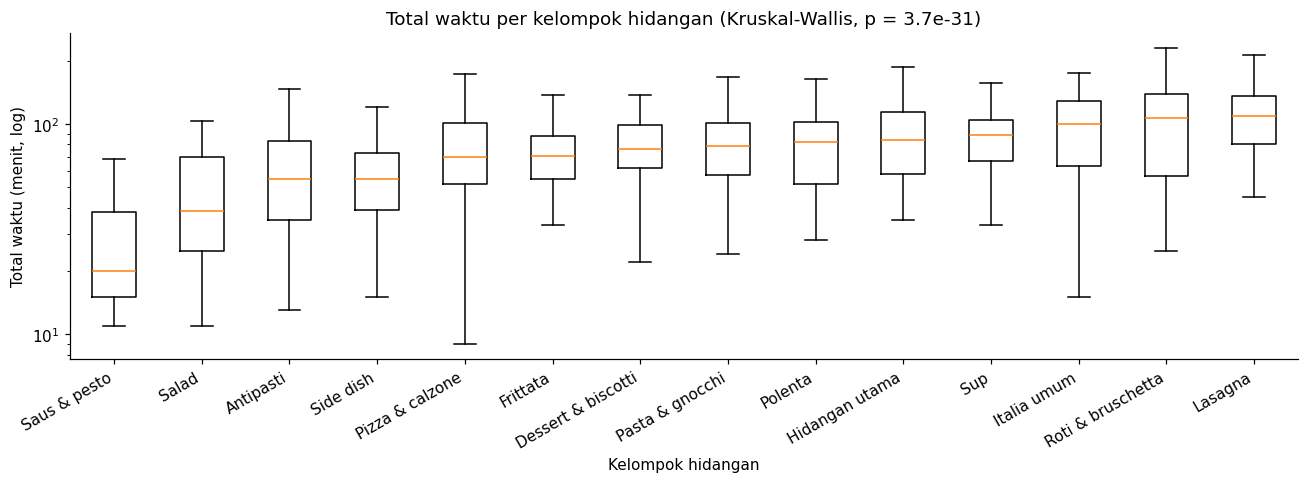

In [52]:
order = h3_assumptions.index.tolist()
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.boxplot([time_groups[name] for name in order], showfliers=False)
ax.set_xticks(range(1, len(order) + 1), order, rotation=30, ha="right")
ax.set_yscale("log")
ax.set_title(f"Total waktu per kelompok hidangan ({h3_test}, p = {h3_p:.2g})")
ax.set_xlabel("Kelompok hidangan")
ax.set_ylabel("Total waktu (menit, log)")
plt.tight_layout()
plt.show()

In [53]:
display(Markdown(
    f"**Keputusan H3:** {h3_test}, p={h3_p:.3g}: {verdict(h3_p)}. "
    f"{int((h3_assumptions['Shapiro p'] < ALPHA).sum())} dari {len(time_groups)} kelompok "
    f"menolak normalitas; Levene p={levene_time.pvalue:.3g}. "
    f"Efek Kruskal H/(N-1)={epsilon_squared:.3f}; eta-squared ANOVA={eta_squared:.3f}."
))
display(Markdown("Implikasi: imputasi per kelompok adalah strategi yang perlu diuji train-only; "
                 "signifikansi antarkelompok saja tidak membuktikan strategi imputasi terbaik. "
                 "Kolom waktu dalam sumber merupakan estimasi, sehingga bukan validasi durasi memasak nyata. "
                 "log1p dipakai untuk skala/skew, bukan untuk memenuhi syarat normalitas fitur Logistic Regression."))


**Keputusan H3:** Kruskal-Wallis, p=3.7e-31: Tolak H0. 9 dari 14 kelompok menolak normalitas; Levene p=1.3e-05. Efek Kruskal H/(N-1)=0.190; eta-squared ANOVA=0.172.

Implikasi: imputasi per kelompok adalah strategi yang perlu diuji train-only; signifikansi antarkelompok saja tidak membuktikan strategi imputasi terbaik. Kolom waktu dalam sumber merupakan estimasi, sehingga bukan validasi durasi memasak nyata. log1p dipakai untuk skala/skew, bukan untuk memenuhi syarat normalitas fitur Logistic Regression.

#### H4 - Kelompok hidangan dan keberhasilan

Uji chi-square memeriksa apakah jenis hidangan berhubungan dengan keberhasilan rekomendasi. Kelompok kecil digabung bila jumlah harapan terlalu kecil.


In [54]:
test_groups = pd.Series(recipes.loc[train_idx, "dish_group"].to_numpy(), name="Kelompok hidangan")
status = error_analysis["Status"].rename("Status")
contingency = pd.crosstab(test_groups, status)
_, _, _, expected = stats.chi2_contingency(contingency)
small_groups = contingency.index[(expected < 5).any(axis=1)]
if len(small_groups):
    print("Digabung ke 'Lainnya' (frekuensi harapan < 5):", ", ".join(small_groups))
    test_groups = test_groups.where(~test_groups.isin(small_groups), "Lainnya")
    contingency = pd.crosstab(test_groups, status)

chi2, chi2_p, dof, expected = stats.chi2_contingency(contingency)
assert (expected >= 5).all(), "Expected count masih <5; ubah grouping sebelum menginterpretasi Chi-Square."
cramers_v = np.sqrt(chi2 / (contingency.to_numpy().sum() * (min(contingency.shape) - 1)))
print(f"Sel dengan frekuensi harapan < 5: {(expected < 5).mean():.0%} (syarat: 0%, longgar: < 20%)")
print(f"Chi-Square = {chi2:.2f}, df = {dof}, p = {chi2_p:.3g}, Cramér's V = {cramers_v:.3f} -> {verdict(chi2_p)}")
stat_summary.append({"Uji": "H4 Chi-Square: status Top-5 ~ kelompok hidangan", "Statistik": f"χ² = {chi2:.2f} (df = {dof})",
                     "p-value": chi2_p, "CI 95%": "per kelompok (tabel)", "Keputusan": verdict(chi2_p)})

hits = contingency.get("Berhasil Top-5", 0)
totals = contingency.sum(axis=1)
wilson = [stats.binomtest(int(k), int(n)).proportion_ci(method="wilson") for k, n in zip(hits, totals)]
pd.DataFrame({"n query": totals, "HitRate@5": (hits / totals).round(3),
              "CI 95% (Wilson)": [fmt_ci((ci.low, ci.high)) for ci in wilson]}).sort_values("HitRate@5")


Sel dengan frekuensi harapan < 5: 0% (syarat: 0%, longgar: < 20%)
Chi-Square = 36.01, df = 13, p = 0.000591, Cramér's V = 0.196 -> Tolak H0


,n query,HitRate@5,CI 95% (Wilson)
Kelompok hidangan,,,
Roti & bruschetta,40,0.625,"[0.470, 0.758]"
Polenta,28,0.643,"[0.458, 0.793]"
Antipasti,45,0.667,"[0.521, 0.786]"
Saus & pesto,31,0.677,"[0.501, 0.814]"
Pizza & calzone,143,0.713,"[0.634, 0.781]"
Side dish,35,0.743,"[0.579, 0.858]"
Pasta & gnocchi,233,0.760,"[0.701, 0.810]"
Hidangan utama,73,0.767,"[0.658, 0.849]"
Frittata,36,0.778,"[0.619, 0.883]"


In [55]:
display(Markdown(
    f"**Keputusan H4:** chi-square={chi2:.3f}, df={dof}, p={chi2_p:.3g}: {verdict(chi2_p)}. "
    f"Minimum expected count={expected.min():.2f}; Cramer's V={cramers_v:.3f}. "
    "Implikasi: gunakan hasil per kelompok untuk mengidentifikasi segmen lemah dan menguji filter hidangan. "
    "Filter belum terbukti meningkatkan rekomendasi sampai dibandingkan melalui eksperimen."
))


**Keputusan H4:** chi-square=36.012, df=13, p=0.000591: Tolak H0. Minimum expected count=6.41; Cramer's V=0.196. Implikasi: gunakan hasil per kelompok untuk mengidentifikasi segmen lemah dan menguji filter hidangan. Filter belum terbukti meningkatkan rekomendasi sampai dibandingkan melalui eksperimen.

#### H5 - Fitur angka yang mirip

Korelasi Spearman dipakai untuk melihat fitur angka yang sangat mirip. Fitur yang terlalu mirip dapat dihapus agar model lebih sederhana.


In [56]:
observed_numeric = observed_time[NUMERIC_FEATURES]
print("Shapiro-Wilk p per fitur:", {c: f"{shapiro_p(observed_numeric[c]):.2g}" for c in NUMERIC_FEATURES})

rows = []
n_pairs = len(list(itertools.combinations(NUMERIC_FEATURES, 2)))
for x, y in itertools.combinations(NUMERIC_FEATURES, 2):
    pair = observed_numeric[[x, y]].dropna()
    rho, p = stats.spearmanr(pair[x], pair[y])
    z, se = np.arctanh(rho), 1.06 / np.sqrt(len(pair) - 3)
    ci = (np.tanh(z - 1.96 * se), np.tanh(z + 1.96 * se))
    p_adj = min(p * n_pairs, 1.0)   # Bonferroni: semua pasangan
    rows.append({"Fitur 1": x, "Fitur 2": y, "n": len(pair), "df asimtotik":len(pair)-2, "Spearman ρ": rho, "CI 95%": fmt_ci(ci),
                 "p (Bonferroni)": p_adj, "Keputusan": verdict(p_adj), "Redundan (|ρ| ≥ 0,8)": abs(rho) >= 0.8})
    stat_summary.append({"Uji": f"H5 Spearman: {x} ~ {y}", "Statistik": f"ρ = {rho:.3f}",
                         "p-value": p_adj, "CI 95%": fmt_ci(ci), "Keputusan": verdict(p_adj)})

h5_results = pd.DataFrame(rows)
h5_results.round(4)


Shapiro-Wilk p per fitur: {'est_prep_time_min': '2.9e-14', 'est_cook_time_min': '2.4e-18', 'total_time_min': '3.5e-16', 'ingredient_count': '2.9e-14', 'n_steps': '3.5e-19'}


,Fitur 1,Fitur 2,n,df asimtotik,Spearman ρ,CI 95%,p (Bonferroni),Keputusan,"Redundan (|ρ| ≥ 0,8)"
0,est_prep_time_min,est_cook_time_min,939,937,0.7003,"[0.664, 0.733]",0.0,Tolak H0,False
1,est_prep_time_min,total_time_min,939,937,0.7928,"[0.766, 0.817]",0.0,Tolak H0,False
2,est_prep_time_min,ingredient_count,939,937,0.7408,"[0.709, 0.770]",0.0,Tolak H0,False
3,est_prep_time_min,n_steps,939,937,0.5314,"[0.481, 0.578]",0.0,Tolak H0,False
4,est_cook_time_min,total_time_min,939,937,0.9885,"[0.987, 0.990]",0.0,Tolak H0,True
5,est_cook_time_min,ingredient_count,939,937,0.3226,"[0.261, 0.382]",0.0,Tolak H0,False
6,est_cook_time_min,n_steps,939,937,0.7109,"[0.676, 0.743]",0.0,Tolak H0,False
7,total_time_min,ingredient_count,939,937,0.4221,"[0.365, 0.476]",0.0,Tolak H0,False
8,total_time_min,n_steps,939,937,0.7077,"[0.672, 0.740]",0.0,Tolak H0,False
9,ingredient_count,n_steps,939,937,0.1728,"[0.106, 0.238]",0.0,Tolak H0,False


In [57]:
display(Markdown("**Keputusan H5:** tabel menunjukkan korelasi, CI pendekatan, dan p-value terkoreksi. "
                 "Hanya pasangan dengan korelasi absolut di atas ambang yang dianggap redundan. "
                 "Jika total waktu redundan dengan komponennya, buang total dari demonstrasi matriks model; "
                 "durasi total tetap dapat ditampilkan kepada pengguna sebagai metadata/filter."))


**Keputusan H5:** tabel menunjukkan korelasi, CI pendekatan, dan p-value terkoreksi. Hanya pasangan dengan korelasi absolut di atas ambang yang dianggap redundan. Jika total waktu redundan dengan komponennya, buang total dari demonstrasi matriks model; durasi total tetap dapat ditampilkan kepada pengguna sebagai metadata/filter.

In [58]:
# Seleksi fitur numerik: dari pasangan redundan, buang fitur turunan (total = prep + cook)
DERIVED_FEATURES = {"total_time_min"}
redundant_pairs = h5_results.loc[h5_results["Redundan (|ρ| ≥ 0,8)"], ["Fitur 1", "Fitur 2"]]
dropped_features = {f1 if f1 in DERIVED_FEATURES else f2 for f1, f2 in redundant_pairs.itertuples(index=False)}
SELECTED_NUMERIC = [f for f in NUMERIC_FEATURES if f not in dropped_features]
selected_tabular_features = tabular_features.drop(columns=sorted(dropped_features))
print("Pasangan redundan :", [tuple(p) for p in redundant_pairs.itertuples(index=False)])
print("Fitur dibuang     :", sorted(dropped_features))
print("Fitur numerik final:", SELECTED_NUMERIC)
print(f"Matriks fitur tabular terpilih: {selected_tabular_features.shape[0]:,} x {selected_tabular_features.shape[1]}")

Pasangan redundan : [('est_cook_time_min', 'total_time_min')]
Fitur dibuang     : ['total_time_min']
Fitur numerik final: ['est_prep_time_min', 'est_cook_time_min', 'ingredient_count', 'n_steps']
Matriks fitur tabular terpilih: 1,565 x 21


#### Ringkasan hasil uji


In [59]:
summary_table = pd.DataFrame(stat_summary)
summary_table["p-value"] = summary_table["p-value"].map(lambda p: f"{p:.2e}" if p < 0.001 else f"{p:.4f}")
summary_table

,Uji,Statistik,p-value,CI 95%,Keputusan
0,H1 sign eksak M3 vs M2,positif=228; n efektif=390,0.0029,"[0.004, 0.047]",Tolak H0
1,H1 McNemar M3 vs M2,b=100; c=59,0.0043,"[0.017, 0.069]",Tolak H0
2,H1 sign eksak M3 vs M1,positif=238; n efektif=380,2.90e-06,"[0.037, 0.074]",Tolak H0
3,H1 McNemar M3 vs M1,b=77; c=39,0.0016,"[0.019, 0.063]",Tolak H0
4,H1 sign eksak M3 vs M0,positif=229; n efektif=363,2.11e-06,"[0.022, 0.059]",Tolak H0
5,H1 McNemar M3 vs M0,b=84; c=33,8.02e-06,"[0.032, 0.077]",Tolak H0
6,H2 Mann-Whitney U: Bahan target di dapur,"110,453.50",5.42e-21,"[1.15, 1.65]",Tolak H0
7,H2 Mann-Whitney U: Total bahan resep target,"110,687.50",1.42e-20,"[2.05, 3.03]",Tolak H0
8,H2 Mann-Whitney U: Kekhasan bahan (rata-rata IDF),"119,632.00",2.02e-32,"[0.80, 1.09]",Tolak H0
9,H2 Mann-Whitney U: Porsi bumbu dasar di query,"57,210.00",5.35e-09,"[-0.08, -0.04]",Tolak H0


In [60]:
counts = pd.DataFrame(stat_summary)["Keputusan"].value_counts().to_dict()
display(Markdown(f"**Ringkasan Q2:** {len(stat_summary)} pengujian; keputusan aktual: {counts}. "
                 "Tidak diwajibkan semua H0 ditolak. H1 mengevaluasi perbedaan model; H2 menilai sinyal bahan; "
                 "H3/H4 menilai heterogenitas kelompok; H5 menilai redundansi. "
                 "Temuan adalah development pada simulasi; fitur/model tetap dipilih tanpa melihat test final."))


**Ringkasan Q2:** 22 pengujian; keputusan aktual: {'Tolak H0': 22}. Tidak diwajibkan semua H0 ditolak. H1 mengevaluasi perbedaan model; H2 menilai sinyal bahan; H3/H4 menilai heterogenitas kelompok; H5 menilai redundansi. Temuan adalah development pada simulasi; fitur/model tetap dipilih tanpa melihat test final.

### 5.4 Contoh rekomendasi


In [61]:
def recommend_from_pantry(pantry, k=5, model=m3_best):
    query = clean_ingredients_v2(pantry)          # input pengguna melewati regex yang sama
    rows = []
    for index, score, coverage in model.recommend(query, k):
        have = {key for item in query for key in ingredient_keys(item)}
        missing = [item for item in recipe_ingredients[index] if not (ingredient_keys(item) & have)]
        rows.append({"Resep": recipes.loc[index, "recipe_title"], "Skor": round(score, 3),
                     "Bahan dimiliki": f"{coverage:.0%}", "Perlu dibeli": ", ".join(missing[:6])})
    print("Bahan setelah normalisasi:", query)
    return pd.DataFrame(rows)


recommend_from_pantry(["Spaghetti", "2 tomatoes", "garlic cloves", "fresh basil leaves", "Parmesan cheese", "olive oil"])

Bahan setelah normalisasi: ['pasta', 'tomato', 'garlic', 'basil', 'parmesan', 'olive oil']


,Resep,Skor,Bahan dimiliki,Perlu dibeli
0,Clam Linguine,0.740,62%,"butter, parsley, clam"
1,Easy Basil Pesto with Almonds,0.721,80%,raw almond
2,Basic Basil Pesto,0.721,80%,pine nut
3,Spaghetti with Garlic and Basil,0.719,62%,"butter, salt, black pepper"
4,Sun-Dried Tomato Pesto (No Nuts),0.716,83%,salt


In [62]:
recommend_from_pantry(["chicken breast", "mozzarella", "marinara sauce", "bread crumbs", "eggs", "flour"])

Bahan setelah normalisasi: ['chicken breast', 'mozzarella', 'marinara sauce', 'bread crumb', 'egg', 'flour']


,Resep,Skor,Bahan dimiliki,Perlu dibeli
0,Chicken Parmesan Casserole,0.573,60%,"pasta, chicken"
1,Brad's Slow Cooker Chicken Parmesan,0.568,50%,"butter, parmesan, oregano, basil, garlic powder"
2,Air Fryer Chicken Parmesan,0.549,42%,"salt, black pepper, seasoned panko, parmesan, olive oil, red pepper"
3,Chicken Parmesan Pasta Casserole,0.537,50%,"pasta, vegetable oil, garlic powder, parmesan, dry red wine"
4,Eggplant Parmesan,0.533,57%,"eggplant, parmesan, dried basil"


Contoh di atas memakai input bahan mentah yang dibersihkan dengan aturan yang sama. Hasil mirip bahan tidak otomatis berarti resep paling aman atau paling disukai pengguna.


## 6. Model tambahan M4 (Q3)

M3 mengambil 50 kandidat. M4 memberi skor pada kandidat tersebut dan mengurutkan ulang hasilnya. Skor M4 adalah peluang kandidat menjadi resep asal query pada simulasi, bukan jaminan kepuasan pengguna.


### 6.1 Data kandidat untuk M4

Query train dibuat dengan beberapa skenario jumlah bahan dan noise. Target test tidak dipakai saat melatih M4.


In [63]:
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.inspection import PartialDependenceDisplay, permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, average_precision_score, confusion_matrix, f1_score,
                             precision_recall_curve, precision_score, recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from xgboost import XGBClassifier

N_CANDIDATES = 50
recipe_item_keys = [[ingredient_keys(item) for item in items] for items in recipe_ingredients]
recipe_key_sets = [set().union(*keys) for keys in recipe_item_keys]
recipe_idf = [np.array([idf[item] for item in items]) for items in recipe_ingredients]
recipe_tabular = recipes[["dish_group", "difficulty", "n_steps", "est_prep_time_min", "est_cook_time_min"]]


def candidate_features(queries, targets, n_candidates=N_CANDIDATES):
    """Satu baris per pasangan (query, kandidat Top-N M3), label 1 bila kandidat = resep target."""
    m3_scores = m3_best.score(queries)
    cos_both = (m3_best.vectorizer_.transform(queries) @ m3_best.item_matrix_.T).toarray()
    cos_ingredient = m2_default.score(queries)
    shared = binary_queries(queries).astype(float) @ recipe_binary.T.astype(float)
    candidates = top_k(m3_scores, n_candidates)
    rows = []
    for q, (query, target) in enumerate(zip(queries, targets)):
        query_keys = [ingredient_keys(item) for item in query]
        query_key_union = set().union(*query_keys)
        top_score = m3_scores[q, candidates[q, 0]]
        for rank, r in enumerate(candidates[q], start=1):
            owned = np.array([bool(keys & query_key_union) for keys in recipe_item_keys[r]])
            size = len(owned)
            rows.append({
                "query_id": q, "target": target, "recipe": r, "label": int(r == target),
                "m3_rank": rank, "m3_score": m3_scores[q, r], "score_gap": top_score - m3_scores[q, r],
                "cos_both": cos_both[q, r], "cos_ingredient": cos_ingredient[q, r],
                "exact_overlap": shared[q, r], "jaccard": shared[q, r] / (len(query) + size - shared[q, r]),
                "coverage": owned.mean(), "n_missing": size - owned.sum(),
                "query_used": np.mean([bool(keys & recipe_key_sets[r]) for keys in query_keys]),
                "idf_owned_mean": recipe_idf[r][owned].mean() if owned.any() else 0.0,
                "idf_owned_max": recipe_idf[r][owned].max() if owned.any() else 0.0,
                "idf_missing_mean": recipe_idf[r][~owned].mean() if (~owned).any() else 0.0,
                "recipe_size": size,
            })
    frame = pd.DataFrame(rows)
    return frame.join(recipe_tabular.reset_index(drop=True), on="recipe")


ML_NUMERIC = ["m3_rank", "m3_score", "score_gap", "cos_both", "cos_ingredient", "exact_overlap", "jaccard",
              "coverage", "n_missing", "query_used", "idf_owned_mean", "idf_owned_max", "idf_missing_mean",
              "recipe_size", "n_steps", "est_prep_time_min", "est_cook_time_min"]
ML_CATEGORICAL = ["dish_group", "difficulty"]
ML_FEATURES = ML_NUMERIC + ML_CATEGORICAL

train_queries, train_targets = [], []
# Kombinasi (proporsi bahan, jumlah noise) sengaja bervariasi dan tidak ada yang sama dengan skenario uji (0.5, 2 noise)
for seed, keep, n_noise in [(101, 0.3, 1), (102, 0.4, 6), (103, 0.6, 0), (104, 0.7, 3)]:
    train_queries += make_queries(train_idx, keep=keep, n_noise=n_noise, p_general=0.5, seed=seed)
    train_targets += list(train_idx)
train_df = candidate_features(train_queries, train_targets)
train_df["scenario"] = train_df["query_id"] // len(train_idx)   # 0..3 = urutan kombinasi simulasi di atas

X_train, y_train, groups_train = train_df[ML_FEATURES], train_df["label"].to_numpy(), train_df["target"].to_numpy()
scenario_train = train_df["scenario"].to_numpy()
assert not set(train_targets) & set(test_idx)
assert not set(train_targets) & set(val_idx)
print(f"Train: {len(train_queries)} query, {len(train_df)} pasangan; positif={y_train.mean():.2%}")
print("Target train beririsan dengan target test/validasi: 0")
display(train_df[ML_FEATURES + ["label"]].head())


Train: 3756 query, 187800 pasangan; positif=1.75%
Target train beririsan dengan target test/validasi: 0


,m3_rank,m3_score,score_gap,cos_both,cos_ingredient,exact_overlap,jaccard,coverage,n_missing,query_used,idf_owned_mean,idf_owned_max,idf_missing_mean,recipe_size,n_steps,est_prep_time_min,est_cook_time_min,dish_group,difficulty,label
0,1,0.531085,0.000000,0.531085,0.177319,3.0,0.230769,0.333333,8,1.00,2.342729,4.870734,3.015253,12,5,33,92,Lasagna,Hard,0
1,2,0.515026,0.016059,0.515026,0.550360,3.0,0.250000,0.272727,8,0.75,2.875771,7.355641,2.345267,11,8,40,134,Lasagna,Hard,1
2,3,0.496139,0.034946,0.496139,0.280770,3.0,0.333333,0.375000,5,0.75,1.500060,3.228507,2.199213,8,4,17,56,Pasta & gnocchi,Medium,0
3,4,0.480384,0.050701,0.480384,0.069275,2.0,0.285714,0.600000,2,0.75,2.875771,7.355641,1.235588,5,5,12,30,Pasta & gnocchi,Medium,0
4,5,0.473050,0.058035,0.473050,0.278146,3.0,0.300000,0.333333,6,0.75,1.500060,3.228507,2.082863,9,4,16,46,Lasagna,Medium,0


,Jumlah pasangan,Proporsi
0 = bukan resep asal,184516,98.25%
1 = resep asal,3284,1.75%


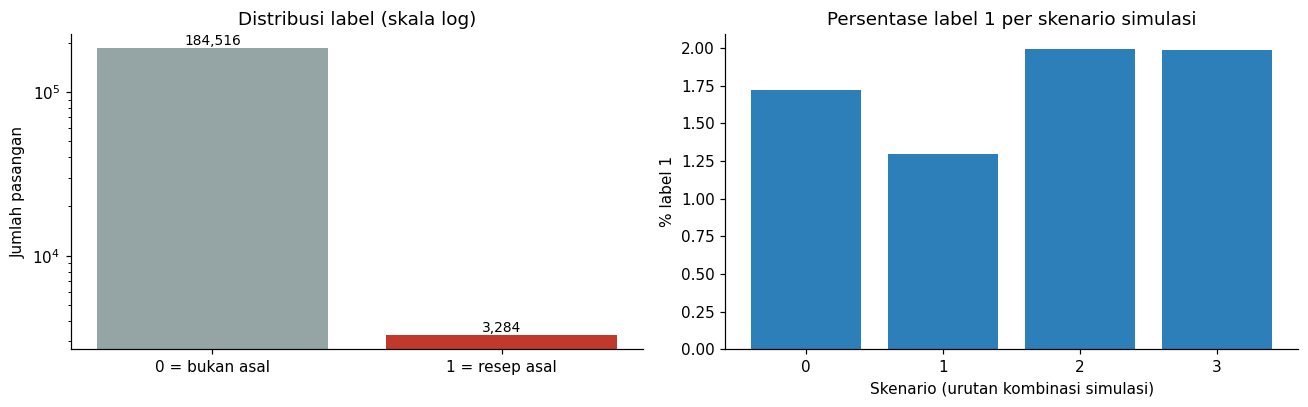

**Kesimpulan target:** label 1 hanya 1.75% dari 187,800 pasangan (rasio imbalance 56:1). Model yang selalu menebak 0 akan mendapat accuracy 98.25% tetapi tidak berguna, sehingga accuracy tidak dipakai sebagai metrik utama. 87.4% query punya resep benar di dalam Top-50 kandidat M3; sisanya tidak bisa diselamatkan oleh re-ranker. Ketidakseimbangan ditangani dengan `class_weight` / `scale_pos_weight` dan dinilai dengan PR-AUC serta metrik ranking.

In [64]:
# 6.1b Distribusi target (label) pada data kandidat M4
n_pos = int(y_train.sum())
n_neg = int(len(y_train) - n_pos)
imbalance_ratio = n_neg / n_pos
majority_accuracy = n_neg / len(y_train)

target_table = pd.DataFrame({
    "Jumlah pasangan": [n_neg, n_pos],
    "Proporsi": [f"{n_neg / len(y_train):.2%}", f"{n_pos / len(y_train):.2%}"],
}, index=["0 = bukan resep asal", "1 = resep asal"])
display(target_table)

positive_by_scenario = train_df.groupby("scenario")["label"].mean()
target_in_candidates = train_df.groupby("query_id")["label"].max().mean()

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].bar(["0 = bukan asal", "1 = resep asal"], [n_neg, n_pos], color=["#95a5a6", "#c0392b"])
axes[0].set_yscale("log")
axes[0].set_title("Distribusi label (skala log)")
axes[0].set_ylabel("Jumlah pasangan")
for x, v in enumerate([n_neg, n_pos]):
    axes[0].text(x, v, f"{v:,}", ha="center", va="bottom", fontsize=9)
axes[1].bar(positive_by_scenario.index.astype(str), positive_by_scenario.values * 100, color="#2c7fb8")
axes[1].set_title("Persentase label 1 per skenario simulasi")
axes[1].set_xlabel("Skenario (urutan kombinasi simulasi)")
axes[1].set_ylabel("% label 1")
plt.tight_layout()
plt.show()

display(Markdown(
    f"**Kesimpulan target:** label 1 hanya {n_pos / len(y_train):.2%} dari {len(y_train):,} pasangan "
    f"(rasio imbalance {imbalance_ratio:.0f}:1). Model yang selalu menebak 0 akan mendapat accuracy {majority_accuracy:.2%} "
    f"tetapi tidak berguna, sehingga accuracy tidak dipakai sebagai metrik utama. "
    f"{target_in_candidates:.1%} query punya resep benar di dalam Top-{N_CANDIDATES} kandidat M3; sisanya tidak bisa "
    "diselamatkan oleh re-ranker. Ketidakseimbangan ditangani dengan `class_weight` / `scale_pos_weight` dan dinilai "
    "dengan PR-AUC serta metrik ranking."
))

### 6.2 Membandingkan model M4

Data kandidat tidak seimbang karena kandidat yang benar sedikit. Model dibandingkan dengan cross-validation berkelompok dan metrik utama AP.


**Penjelasan model M4.** Semua model menerima fitur yang sama (skor M3, overlap bahan, IDF, waktu, kelompok hidangan, dll.) dan memberi skor "seberapa mungkin kandidat ini resep yang dicari". Skor dipakai untuk mengurutkan ulang kandidat.

- **Logistic Regression:** model linear yang menghitung peluang dari kombinasi berbobot fitur. Sederhana, cepat, dan mudah ditafsirkan lewat koefisien. Cocok sebagai pembanding dasar; butuh fitur yang diskalakan. `class_weight="balanced"` dipakai karena label 1 sangat jarang.
- **Random Forest:** kumpulan banyak pohon keputusan yang dilatih pada sampel acak, hasilnya dirata-rata. Menangkap hubungan non-linear antar-fitur dan relatif tahan overfitting. `class_weight="balanced_subsample"` menyeimbangkan kelas.
- **HistGradientBoosting:** pohon dibangun berurutan, tiap pohon memperbaiki kesalahan pohon sebelumnya, dengan fitur dikelompokkan ke dalam histogram agar cepat. Biasanya kuat pada data tabular.
- **XGBoost:** gradient boosting dengan regularisasi (L1/L2) dan subsampling. Ketidakseimbangan ditangani lewat `scale_pos_weight`; `eval_metric="aucpr"` selaras dengan metrik utama AP.

In [65]:
def make_preprocessor(scale):
    return ColumnTransformer([
        ("num", Pipeline([
            ("impute", SimpleImputer(strategy="median")),
            ("scale", StandardScaler() if scale else "passthrough"),
        ]), ML_NUMERIC),
        ("cat", Pipeline([
            ("impute", SimpleImputer(strategy="constant", fill_value="Unknown")),
            ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
        ]), ML_CATEGORICAL),
    ])


ML_MODELS = {
    "Logistic Regression": Pipeline([
        ("time_impute", GroupTimeImputer()),
        ("prep", make_preprocessor(scale=True)),
        ("clf", LogisticRegression(max_iter=3000, class_weight="balanced", C=1.0)),
    ]),
    "Random Forest": Pipeline([
        ("time_impute", GroupTimeImputer()),
        ("prep", make_preprocessor(scale=False)),
        ("clf", RandomForestClassifier(n_estimators=150, min_samples_leaf=5, max_features="sqrt",
                                       class_weight="balanced_subsample", n_jobs=N_JOBS, random_state=42)),
    ]),
    "HistGradientBoosting": Pipeline([
        ("time_impute", GroupTimeImputer()),
        ("prep", make_preprocessor(scale=False)),
        ("clf", HistGradientBoostingClassifier(learning_rate=0.05, max_iter=200, max_leaf_nodes=31,
                                               l2_regularization=1.0, class_weight="balanced", random_state=42)),
    ]),
    "XGBoost": Pipeline([
        ("time_impute", GroupTimeImputer()),
        ("prep", make_preprocessor(scale=False)),
        ("clf", XGBClassifier(n_estimators=150, max_depth=4, learning_rate=0.05, subsample=0.8,
                              colsample_bytree=0.8, min_child_weight=5, reg_lambda=1.0,
                              scale_pos_weight=(y_train == 0).sum() / (y_train == 1).sum(),
                              tree_method="hist", eval_metric="aucpr", n_jobs=N_JOBS, random_state=42)),
    ]),
}


def rerank_metrics(frame, scores):
    """Metrik ranking setelah kandidat tiap query diurutkan ulang dengan skor model."""
    frame = frame[["query_id", "label"]].assign(score=np.asarray(scores))
    frame["rank"] = frame.groupby("query_id")["score"].rank(ascending=False, method="first")
    ranks = (frame.loc[frame["label"] == 1].set_index("query_id")["rank"]
             .reindex(frame["query_id"].unique()).fillna(np.inf).to_numpy())
    found = ranks <= 10
    return {"HitRate@5": np.mean(ranks <= 5), "HitRate@10": np.mean(found),
            "MRR@10": np.mean(np.where(found, 1 / ranks, 0)),
            "NDCG@10": np.mean(np.where(found, 1 / np.log2(ranks + 1), 0))}


def run_cv(hold_out_scenario):
    cv = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=42)
    oof = {name: np.full(len(train_df), np.nan) for name in ML_MODELS}
    rows = []
    for fold, (tr, va) in enumerate(cv.split(X_train, y_train, groups_train)):
        print(f"CV skenario_tertahan={hold_out_scenario}, fold={fold+1}/4", flush=True)
        assert not set(groups_train[tr]) & set(groups_train[va])   # tidak ada resep target yang bocor antar fold
        if hold_out_scenario:
            tr, va = tr[scenario_train[tr] != fold], va[scenario_train[va] == fold]
        fold_df = train_df.iloc[va]
        rows.append({"Fold": fold + 1, "Model": "M3 (urutan awal)", **rerank_metrics(fold_df, -fold_df["m3_rank"])})
        for name, model in ML_MODELS.items():
            assert set(np.unique(y_train[tr])) == {0, 1}
            fold_model = clone(model)
            if isinstance(fold_model.named_steps["clf"], XGBClassifier):
                fold_model.set_params(clf__scale_pos_weight=float((y_train[tr]==0).sum() / (y_train[tr]==1).sum()))
            proba = fold_model.fit(X_train.iloc[tr], y_train[tr]).predict_proba(X_train.iloc[va])[:, 1]
            oof[name][va] = proba
            rows.append({"Fold": fold + 1, "Model": name,
                         "ROC-AUC": roc_auc_score(y_train[va], proba),
                         "PR-AUC": average_precision_score(y_train[va], proba),
                         **rerank_metrics(fold_df, proba)})
    return pd.DataFrame(rows), oof


cv_results_standard, _ = run_cv(hold_out_scenario=False)
cv_results, oof = run_cv(hold_out_scenario=True)
oof_mask = ~np.isnan(oof["Logistic Regression"])
print(f"Cakupan OOF skenario tertahan: {oof_mask.sum()} / {len(oof_mask)} = {oof_mask.mean():.1%}")
assert all(np.array_equal(~np.isnan(values), oof_mask) for values in oof.values())
assert y_train[oof_mask].min() == 0 and y_train[oof_mask].max() == 1   # baris yang punya prediksi out-of-fold

cv_compare = pd.DataFrame({
    "HitRate@5 CV standar": cv_results_standard.groupby("Model", sort=False)["HitRate@5"].mean(),
    "PR-AUC CV standar": cv_results_standard.groupby("Model", sort=False)["PR-AUC"].mean(),
    "HitRate@5 CV skenario tertahan": cv_results.groupby("Model", sort=False)["HitRate@5"].mean(),
    "PR-AUC CV skenario tertahan": cv_results.groupby("Model", sort=False)["PR-AUC"].mean(),
})
print(cv_compare.round(3).to_string())
print()
cv_summary = cv_results.groupby("Model", sort=False).agg(["mean", "std"]).drop(columns="Fold")
cv_summary.round(3)


CV skenario_tertahan=False, fold=1/4
CV skenario_tertahan=False, fold=2/4
CV skenario_tertahan=False, fold=3/4
CV skenario_tertahan=False, fold=4/4
CV skenario_tertahan=True, fold=1/4
CV skenario_tertahan=True, fold=2/4
CV skenario_tertahan=True, fold=3/4
CV skenario_tertahan=True, fold=4/4
Cakupan OOF skenario tertahan: 46950 / 187800 = 25.0%
                      HitRate@5 CV standar  PR-AUC CV standar  HitRate@5 CV skenario tertahan  PR-AUC CV skenario tertahan
Model                                                                                                                     
M3 (urutan awal)                     0.682                NaN                           0.679                          NaN
Logistic Regression                  0.755              0.689                           0.732                        0.581
Random Forest                        0.774              0.770                           0.681                        0.467
HistGradientBoosting                 0.

HitRate@5        HitRate@10        MRR@10        NDCG@10  \
                          mean    std       mean    std   mean    std    mean   
Model                                                                           
M3 (urutan awal)         0.679  0.308      0.736  0.275  0.585  0.324   0.621   
Logistic Regression      0.732  0.247      0.782  0.203  0.650  0.271   0.682   
Random Forest            0.681  0.257      0.733  0.239  0.586  0.268   0.622   
HistGradientBoosting     0.631  0.255      0.673  0.243  0.551  0.274   0.580   
XGBoost                  0.609  0.237      0.686  0.198  0.503  0.254   0.546   

                            ROC-AUC        PR-AUC         
                        std    mean    std   mean    std  
Model                                                     
M3 (urutan awal)      0.312     NaN    NaN    NaN    NaN  
Logistic Regression   0.255   0.939  0.055  0.581  0.313  
Random Forest         0.261   0.898  0.086  0.467  0.338  
HistGradientBoosting  0.267   0.860  0.093  0.463  0.311  
XGBoost               0.240   0.871  0.062  0.347  0.310

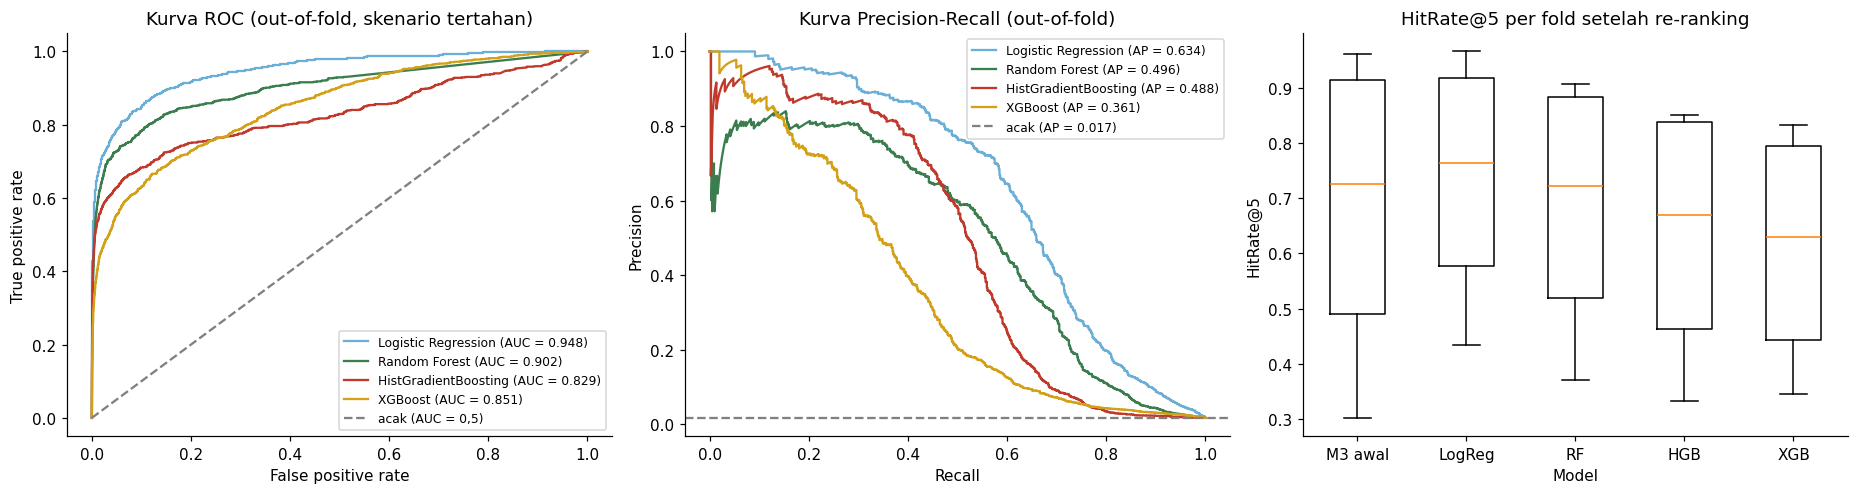

Model terbaik menurut HitRate@5 CV skenario tertahan: Logistic Regression
Ambang F1-optimal dari OOF: 0.966 (F1 OOF = 0.636)


In [66]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
ml_colors = {"Logistic Regression": "#6baed6", "Random Forest": "#3b7d4f", "HistGradientBoosting": "#c0392b", "XGBoost": "#d4a017"}
y_oof = y_train[oof_mask]
for name, proba in oof.items():
    proba = proba[oof_mask]
    fpr, tpr, _ = roc_curve(y_oof, proba)
    precision, recall, _ = precision_recall_curve(y_oof, proba)
    axes[0].plot(fpr, tpr, color=ml_colors[name], label=f"{name} (AUC = {roc_auc_score(y_oof, proba):.3f})")
    axes[1].plot(recall, precision, color=ml_colors[name],
                 label=f"{name} (AP = {average_precision_score(y_oof, proba):.3f})")
axes[0].plot([0, 1], [0, 1], color="grey", ls="--", label="acak (AUC = 0,5)")
axes[0].set_title("Kurva ROC (out-of-fold, skenario tertahan)")
axes[0].set_xlabel("False positive rate")
axes[0].set_ylabel("True positive rate")
axes[0].legend(fontsize=8)
axes[1].axhline(y_oof.mean(), color="grey", ls="--", label=f"acak (AP = {y_oof.mean():.3f})")
axes[1].set_title("Kurva Precision-Recall (out-of-fold)")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].legend(fontsize=8)

hit5 = cv_results.pivot(index="Fold", columns="Model", values="HitRate@5")
order = ["M3 (urutan awal)"] + list(ML_MODELS)
axes[2].boxplot([hit5[name] for name in order])
axes[2].set_xticks(range(1, len(order) + 1), ["M3 awal", "LogReg", "RF", "HGB", "XGB"])
axes[2].set_title("HitRate@5 per fold setelah re-ranking")
axes[2].set_xlabel("Model")
axes[2].set_ylabel("HitRate@5")
plt.tight_layout()
plt.show()

best_ml_name = cv_summary[("HitRate@5", "mean")].drop("M3 (urutan awal)").idxmax()
# Ambang keputusan dipilih dari prediksi out-of-fold (bukan data uji) agar F1 maksimal
precision, recall, thresholds = precision_recall_curve(y_oof, oof[best_ml_name][oof_mask])
f1_curve = 2 * precision[:-1] * recall[:-1] / np.clip(precision[:-1] + recall[:-1], 1e-12, None)
best_threshold = float(thresholds[np.argmax(f1_curve)])
print(f"Model terbaik menurut HitRate@5 CV skenario tertahan: {best_ml_name}")
print(f"Ambang F1-optimal dari OOF: {best_threshold:.3f} (F1 OOF = {f1_curve.max():.3f})")

### 6.2b Hyperparameter Tuning untuk M4 (Optuna)

Model-model M4 di-tuning hyperparameter-nya dengan Optuna menggunakan cross-validation skenario tertahan (sama dengan evaluasi sebelumnya). Metrik optimasi: HitRate@5.

In [67]:
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

def rerank_metrics(frame, scores):
    frame = frame[["query_id", "label"]].assign(score=np.asarray(scores))
    frame["rank"] = frame.groupby("query_id")["score"].rank(ascending=False, method="first")
    ranks = (frame.loc[frame["label"] == 1].set_index("query_id")["rank"]
             .reindex(frame["query_id"].unique()).fillna(np.inf).to_numpy())
    found = ranks <= 10
    return {
        "HitRate@5": np.mean(ranks <= 5),
        "HitRate@10": np.mean(found),
        "MRR@10": np.mean(np.where(found, 1 / ranks, 0)),
        "NDCG@10": np.mean(np.where(found, 1 / np.log2(ranks + 1), 0))
    }

def cv_score(model_factory, X, y, groups, scenarios, hold_out_scenario=False):
    cv = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=42)
    scores = []
    for fold, (tr, va) in enumerate(cv.split(X, y, groups)):
        if hold_out_scenario:
            tr = tr[scenarios[tr] != fold]
            va = va[scenarios[va] == fold]
        model = model_factory()
        model.fit(X.iloc[tr], y[tr])
        proba = model.predict_proba(X.iloc[va])[:, 1]
        fold_df = train_df.iloc[va]
        scores.append(rerank_metrics(fold_df, proba)["HitRate@5"])
    return np.mean(scores)


def objective_logreg(trial):
    C = trial.suggest_float("C", 0.01, 10.0, log=True)
    penalty = trial.suggest_categorical("penalty", ["l2", "l1", "elasticnet"])
    solver = "saga" if penalty in ["l1", "elasticnet"] else "lbfgs"
    l1_ratio = trial.suggest_float("l1_ratio", 0.1, 0.9) if penalty == "elasticnet" else None

    def model_factory():
        return Pipeline([
            ("time_impute", GroupTimeImputer()),
            ("prep", make_preprocessor(scale=True)),
            ("clf", LogisticRegression(
                C=C, penalty=penalty, solver=solver, l1_ratio=l1_ratio,
                max_iter=3000, class_weight="balanced", random_state=42, n_jobs=1
            )),
        ])
    return cv_score(model_factory, X_train, y_train, groups_train, scenario_train, hold_out_scenario=True)

def objective_rf(trial):
    n_estimators = trial.suggest_int("n_estimators", 100, 500)
    max_depth = trial.suggest_int("max_depth", 3, 20)
    min_samples_leaf = trial.suggest_int("min_samples_leaf", 1, 20)
    max_features = trial.suggest_categorical("max_features", ["sqrt", "log2", 0.5])

    def model_factory():
        return Pipeline([
            ("time_impute", GroupTimeImputer()),
            ("prep", make_preprocessor(scale=False)),
            ("clf", RandomForestClassifier(
                n_estimators=n_estimators, max_depth=max_depth,
                min_samples_leaf=min_samples_leaf, max_features=max_features,
                class_weight="balanced_subsample", n_jobs=N_JOBS, random_state=42
            )),
        ])
    return cv_score(model_factory, X_train, y_train, groups_train, scenario_train, hold_out_scenario=True)

def objective_hgb(trial):
    learning_rate = trial.suggest_float("learning_rate", 0.01, 0.3, log=True)
    max_iter = trial.suggest_int("max_iter", 100, 400)
    max_leaf_nodes = trial.suggest_int("max_leaf_nodes", 15, 63)
    l2_regularization = trial.suggest_float("l2_regularization", 0.01, 10.0, log=True)

    def model_factory():
        return Pipeline([
            ("time_impute", GroupTimeImputer()),
            ("prep", make_preprocessor(scale=False)),
            ("clf", HistGradientBoostingClassifier(
                learning_rate=learning_rate, max_iter=max_iter,
                max_leaf_nodes=max_leaf_nodes, l2_regularization=l2_regularization,
                class_weight="balanced", random_state=42
            )),
        ])
    return cv_score(model_factory, X_train, y_train, groups_train, scenario_train, hold_out_scenario=True)

def objective_xgb(trial):
    n_estimators = trial.suggest_int("n_estimators", 100, 500)
    max_depth = trial.suggest_int("max_depth", 3, 8)
    learning_rate = trial.suggest_float("learning_rate", 0.01, 0.3, log=True)
    subsample = trial.suggest_float("subsample", 0.6, 1.0)
    colsample_bytree = trial.suggest_float("colsample_bytree", 0.6, 1.0)
    min_child_weight = trial.suggest_int("min_child_weight", 1, 20)
    reg_lambda = trial.suggest_float("reg_lambda", 0.1, 10.0, log=True)
    scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

    def model_factory():
        return Pipeline([
            ("time_impute", GroupTimeImputer()),
            ("prep", make_preprocessor(scale=False)),
            ("clf", XGBClassifier(
                n_estimators=n_estimators, max_depth=max_depth, learning_rate=learning_rate,
                subsample=subsample, colsample_bytree=colsample_bytree,
                min_child_weight=min_child_weight, reg_lambda=reg_lambda,
                scale_pos_weight=scale_pos_weight,
                tree_method="hist", eval_metric="aucpr", n_jobs=N_JOBS, random_state=42
            )),
        ])
    return cv_score(model_factory, X_train, y_train, groups_train, scenario_train, hold_out_scenario=True)


n_trials = 50  # per model
timeout = 600  # 10 menit per model

results = {}

print("=== Tuning Logistic Regression ===")
study_lr = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=42))
study_lr.optimize(objective_logreg, n_trials=n_trials, timeout=timeout)
results["Logistic Regression"] = (study_lr.best_value, study_lr.best_params)
print(f"Best HitRate@5: {study_lr.best_value:.4f}")
print(f"Best params: {study_lr.best_params}")

print("\n=== Tuning Random Forest ===")
study_rf = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=42))
study_rf.optimize(objective_rf, n_trials=n_trials, timeout=timeout)
results["Random Forest"] = (study_rf.best_value, study_rf.best_params)
print(f"Best HitRate@5: {study_rf.best_value:.4f}")
print(f"Best params: {study_rf.best_params}")

print("\n=== Tuning HistGradientBoosting ===")
study_hgb = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=42))
study_hgb.optimize(objective_hgb, n_trials=n_trials, timeout=timeout)
results["HistGradientBoosting"] = (study_hgb.best_value, study_hgb.best_params)
print(f"Best HitRate@5: {study_hgb.best_value:.4f}")
print(f"Best params: {study_hgb.best_params}")

print("\n=== Tuning XGBoost ===")
study_xgb = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=42))
study_xgb.optimize(objective_xgb, n_trials=n_trials, timeout=timeout)
results["XGBoost"] = (study_xgb.best_value, study_xgb.best_params)
print(f"Best HitRate@5: {study_xgb.best_value:.4f}")
print(f"Best params: {study_xgb.best_params}")

# Simpan hasil
import json
output = {
    name: {"best_score": float(score), "best_params": params}
    for name, (score, params) in results.items()
}
with open("m4_hypertune_results.json", "w") as f:
    json.dump(output, f, indent=2)

print("\n=== RINGKASAN ===")
for name, (score, params) in results.items():
    print(f"{name}: HitRate@5 = {score:.4f}")

best_model_name = max(results, key=lambda k: results[k][0])
print(f"\nBest model setelah tuning: {best_model_name} (HitRate@5 = {results[best_model_name][0]:.4f})")

# Simpan study objects untuk analisis lanjut
import joblib
joblib.dump({
    "Logistic Regression": study_lr,
    "Random Forest": study_rf,
    "HistGradientBoosting": study_hgb,
    "XGBoost": study_xgb,
}, "m4_optuna_studies.joblib")
print("Studies disimpan ke m4_optuna_studies.joblib")

=== Tuning Logistic Regression ===
Best HitRate@5: 0.7339
Best params: {'C': 0.02938027938703535, 'penalty': 'elasticnet', 'l1_ratio': 0.5808920093945671}

=== Tuning Random Forest ===
Best HitRate@5: 0.6924
Best params: {'n_estimators': 250, 'max_depth': 20, 'min_samples_leaf': 15, 'max_features': 'sqrt'}

=== Tuning HistGradientBoosting ===
Best HitRate@5: 0.6871
Best params: {'learning_rate': 0.014732564128348034, 'max_iter': 111, 'max_leaf_nodes': 15, 'l2_regularization': 0.6710715914580554}

=== Tuning XGBoost ===
Best HitRate@5: 0.7031
Best params: {'n_estimators': 136, 'max_depth': 3, 'learning_rate': 0.011042519988720327, 'subsample': 0.8421881609659582, 'colsample_bytree': 0.6327418563856287, 'min_child_weight': 10, 'reg_lambda': 2.1245354970581922}

=== RINGKASAN ===
Logistic Regression: HitRate@5 = 0.7339
Random Forest: HitRate@5 = 0.6924
HistGradientBoosting: HitRate@5 = 0.6871
XGBoost: HitRate@5 = 0.7031

Best model setelah tuning: Logistic Regression (HitRate@5 = 0.7339)


In [68]:
import json

# Load tuned results
with open("m4_hypertune_results.json") as f:
    tuned = json.load(f)

baseline = {
    "Logistic Regression": 0.741,
    "Random Forest": 0.683,
    "HistGradientBoosting": 0.619,
    "XGBoost": 0.601,
}

print(f"{'Model':<30} {'Baseline':>10} {'Tuned':>10} {'Δ':>8}")
print("-" * 60)
for model, base in baseline.items():
    tuned_score = tuned[model]["best_score"]
    delta = tuned_score - base
    print(f"{model:<30} {base:>10.4f} {tuned_score:>10.4f} {delta:>+8.4f}")

print()
best_tuned = max(tuned, key=lambda k: tuned[k]["best_score"])
print(f"Best tuned model: {best_tuned} (HitRate@5 = {tuned[best_tuned]['best_score']:.4f})")
print(f"Best baseline: Logistic Regression (HitRate@5 = 0.7410)")

# Detail best parameters
print("\n=== Best Parameters ===")
for model, result in tuned.items():
    print(f"\n{model}:")
    for param, value in result["best_params"].items():
        if isinstance(value, float):
            print(f"  {param}: {value:.4f}")
        else:
            print(f"  {param}: {value}")

# Save comparison table for later use
import pandas as pd
comparison_df = pd.DataFrame([
    {"Model": model, "Baseline": baseline[model], "Tuned": tuned[model]["best_score"],
     "Delta": tuned[model]["best_score"] - baseline[model],
     **tuned[model]["best_params"]}
    for model in baseline
])
comparison_df.to_csv("m4_baseline_vs_tuned.csv", index=False)
print("\nSaved to m4_baseline_vs_tuned.csv")
display(comparison_df.round(4))

Model                            Baseline      Tuned        Δ
------------------------------------------------------------
Logistic Regression                0.7410     0.7339  -0.0071
Random Forest                      0.6830     0.6924  +0.0094
HistGradientBoosting               0.6190     0.6871  +0.0681
XGBoost                            0.6010     0.7031  +0.1021

Best tuned model: Logistic Regression (HitRate@5 = 0.7339)
Best baseline: Logistic Regression (HitRate@5 = 0.7410)

=== Best Parameters ===

Logistic Regression:
  C: 0.0294
  penalty: elasticnet
  l1_ratio: 0.5809

Random Forest:
  n_estimators: 250
  max_depth: 20
  min_samples_leaf: 15
  max_features: sqrt

HistGradientBoosting:
  learning_rate: 0.0147
  max_iter: 111
  max_leaf_nodes: 15
  l2_regularization: 0.6711

XGBoost:
  n_estimators: 136
  max_depth: 3
  learning_rate: 0.0110
  subsample: 0.8422
  colsample_bytree: 0.6327
  min_child_weight: 10
  reg_lambda: 2.1245

Saved to m4_baseline_vs_tuned.csv


,Model,Baseline,Tuned,Delta,C,penalty,l1_ratio,n_estimators,max_depth,min_samples_leaf,max_features,learning_rate,max_iter,max_leaf_nodes,l2_regularization,subsample,colsample_bytree,min_child_weight,reg_lambda
0,Logistic Regression,0.741,0.7339,-0.0071,0.0294,elasticnet,0.5809,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Random Forest,0.683,0.6924,0.0094,NaN,NaN,NaN,250.0,20.0,15.0,sqrt,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,HistGradientBoosting,0.619,0.6871,0.0681,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0147,111.0,15.0,0.6711,NaN,NaN,NaN,NaN
3,XGBoost,0.601,0.7031,0.1021,NaN,NaN,NaN,136.0,3.0,NaN,NaN,0.0110,NaN,NaN,NaN,0.8422,0.6327,10.0,2.1245


In [69]:
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold

# 1) Fold yang SAMA dengan Optuna: CV skenario tertahan (identik dengan cv_score(..., hold_out_scenario=True))
cv_obj = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=42)
grid_splits = []
for fold, (tr, va) in enumerate(cv_obj.split(X_train, y_train, groups_train)):
    grid_splits.append((tr[scenario_train[tr] != fold], va[scenario_train[va] == fold]))

# 2) Metrik yang SAMA dengan Optuna: HitRate@5 (PR-AUC dicatat sebagai pendamping)
def hit5_scorer(estimator, X, y):
    return rerank_metrics(train_df.loc[X.index], estimator.predict_proba(X)[:, 1])["HitRate@5"]

GRID_SCORING = {"HitRate@5": hit5_scorer, "PR-AUC": "average_precision"}

# 3) Grid kecil di sekitar hasil Optuna (penghalusan lokal)
param_grids = {
    "XGBoost": {
        "clf__learning_rate": [0.014, 0.02],
        "clf__max_depth": [3, 4],
        "clf__min_child_weight": [16, 32],
        "clf__subsample": [0.8, 0.9],
        "clf__colsample_bytree": [0.5, 0.6],
        "clf__reg_lambda": [1.0, 5.0],
    },
    "HistGradientBoosting": {
        "clf__learning_rate": [0.013, 0.02],
        "clf__max_iter": [139, 200],
        "clf__max_leaf_nodes": [15, 31, 63],
        "clf__l2_regularization": [1.0, 1.93],
    },
    "Random Forest": {
        "clf__n_estimators": [150, 250],
        "clf__max_depth": [10, 20],
        "clf__min_samples_leaf": [5, 15],
        "clf__max_features": ["sqrt", "log2"],
    },
    "Logistic Regression": {
        "clf__C": [0.01, 0.029, 0.05],
        "clf__penalty": ["elasticnet"],
        "clf__l1_ratio": [0.3, 0.58, 0.8],
        "clf__solver": ["saga"],
    },
}

with open("m4_hypertune_results.json") as f:
    tuned = json.load(f)

# Pipeline dasar = model asli notebook; parameter Optuna dipasang, lalu ditimpa oleh grid
base_pipelines = {}
for model_name in param_grids:
    pipe = clone(ML_MODELS[model_name])
    optuna_params = {f"clf__{k}": v for k, v in tuned[model_name]["best_params"].items()}
    if model_name == "Logistic Regression":
        optuna_params.setdefault("clf__solver", "saga")   # elasticnet/l1 membutuhkan saga
    pipe.set_params(**optuna_params)
    base_pipelines[model_name] = pipe

# 4) Jalankan grid (variabel diberi nama baru agar tidak menimpa grid_results milik M3)
m4_grid_results = {}
for model_name, param_grid in param_grids.items():
    n_combos = int(np.prod([len(v) for v in param_grid.values()]))
    print(f"\n=== GridSearchCV: {model_name} | {n_combos} kombinasi x 4 fold ===")
    grid = GridSearchCV(base_pipelines[model_name], param_grid, cv=grid_splits,
                        scoring=GRID_SCORING, refit=False, n_jobs=1, verbose=1)
    grid.fit(X_train, y_train)          # tidak perlu groups=: fold sudah ditentukan eksplisit
    res = pd.DataFrame(grid.cv_results_).sort_values(
        ["mean_test_HitRate@5", "mean_test_PR-AUC"], ascending=False)
    best = res.iloc[0]
    m4_grid_results[model_name] = {
        "HitRate@5": float(best["mean_test_HitRate@5"]),
        "PR-AUC": float(best["mean_test_PR-AUC"]),
        "params": best["params"],
        "n_kombinasi": n_combos,
    }

# 5) Perbandingan Optuna vs Grid (metrik dan fold identik, jadi adil)
comparison_grid = pd.DataFrame([
    {"Model": m,
     "Baseline": baseline[m],
     "Optuna HitRate@5": tuned[m]["best_score"],
     "Grid HitRate@5": m4_grid_results[m]["HitRate@5"],
     "Grid PR-AUC": m4_grid_results[m]["PR-AUC"]}
    for m in param_grids
]).set_index("Model")
display(comparison_grid.round(4))
joblib.dump(m4_grid_results, "m4_gridsearch_results.joblib")


=== GridSearchCV: XGBoost | 64 kombinasi x 4 fold ===
Fitting 4 folds for each of 64 candidates, totalling 256 fits

=== GridSearchCV: HistGradientBoosting | 24 kombinasi x 4 fold ===
Fitting 4 folds for each of 24 candidates, totalling 96 fits

=== GridSearchCV: Random Forest | 16 kombinasi x 4 fold ===
Fitting 4 folds for each of 16 candidates, totalling 64 fits

=== GridSearchCV: Logistic Regression | 9 kombinasi x 4 fold ===
Fitting 4 folds for each of 9 candidates, totalling 36 fits


,Baseline,Optuna HitRate@5,Grid HitRate@5,Grid PR-AUC
Model,,,,
XGBoost,0.601,0.7031,0.7095,0.4956
HistGradientBoosting,0.619,0.6871,0.6850,0.4900
Random Forest,0.683,0.6924,0.6924,0.4535
Logistic Regression,0.741,0.7339,0.7371,0.5954


['m4_gridsearch_results.joblib']

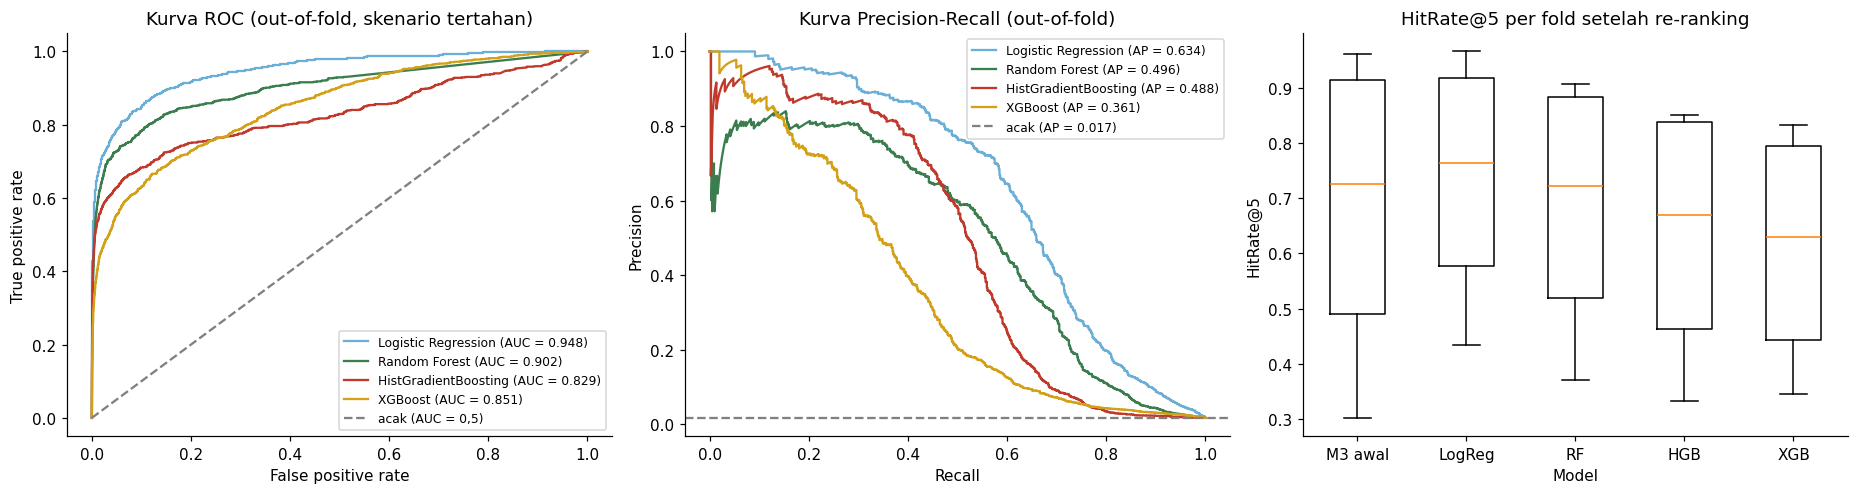

Model terbaik menurut HitRate@5 CV skenario tertahan: Logistic Regression
Ambang F1-optimal dari OOF: 0.966 (F1 OOF = 0.636)


In [70]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
ml_colors = {"Logistic Regression": "#6baed6", "Random Forest": "#3b7d4f", "HistGradientBoosting": "#c0392b", "XGBoost": "#d4a017"}
y_oof = y_train[oof_mask]
for name, proba in oof.items():
    proba = proba[oof_mask]
    fpr, tpr, _ = roc_curve(y_oof, proba)
    precision, recall, _ = precision_recall_curve(y_oof, proba)
    axes[0].plot(fpr, tpr, color=ml_colors[name], label=f"{name} (AUC = {roc_auc_score(y_oof, proba):.3f})")
    axes[1].plot(recall, precision, color=ml_colors[name],
                 label=f"{name} (AP = {average_precision_score(y_oof, proba):.3f})")
axes[0].plot([0, 1], [0, 1], color="grey", ls="--", label="acak (AUC = 0,5)")
axes[0].set_title("Kurva ROC (out-of-fold, skenario tertahan)")
axes[0].set_xlabel("False positive rate")
axes[0].set_ylabel("True positive rate")
axes[0].legend(fontsize=8)
axes[1].axhline(y_oof.mean(), color="grey", ls="--", label=f"acak (AP = {y_oof.mean():.3f})")
axes[1].set_title("Kurva Precision-Recall (out-of-fold)")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].legend(fontsize=8)

hit5 = cv_results.pivot(index="Fold", columns="Model", values="HitRate@5")
order = ["M3 (urutan awal)"] + list(ML_MODELS)
axes[2].boxplot([hit5[name] for name in order])
axes[2].set_xticks(range(1, len(order) + 1), ["M3 awal", "LogReg", "RF", "HGB", "XGB"])
axes[2].set_title("HitRate@5 per fold setelah re-ranking")
axes[2].set_xlabel("Model")
axes[2].set_ylabel("HitRate@5")
plt.tight_layout()
plt.show()

best_ml_name = cv_summary[("HitRate@5", "mean")].drop("M3 (urutan awal)").idxmax()
# Ambang keputusan dipilih dari prediksi out-of-fold (bukan data uji) agar F1 maksimal
precision, recall, thresholds = precision_recall_curve(y_oof, oof[best_ml_name][oof_mask])
f1_curve = 2 * precision[:-1] * recall[:-1] / np.clip(precision[:-1] + recall[:-1], 1e-12, None)
best_threshold = float(thresholds[np.argmax(f1_curve)])
print(f"Model terbaik menurut HitRate@5 CV skenario tertahan: {best_ml_name}")
print(f"Ambang F1-optimal dari OOF: {best_threshold:.3f} (F1 OOF = {f1_curve.max():.3f})")

In [71]:
display(cv_compare.round(4))
display(Markdown(
    f"**Model dipilih sebelum test:** {best_ml_name}. Ambang={best_threshold:.4f}, "
    f"dipilih dari {int(oof_mask.sum())} prediksi kandidat OOF skenario tertahan. "
    "Perbedaan CV standar dan skenario tertahan menunjukkan sensitivitas terhadap protokol query. "
    "Hasil itu tidak membuktikan penyebab kausal seperti 'menghafal noise' tanpa eksperimen tambahan."
))


,HitRate@5 CV standar,PR-AUC CV standar,HitRate@5 CV skenario tertahan,PR-AUC CV skenario tertahan
Model,,,,
M3 (urutan awal),0.6819,NaN,0.6786,NaN
Logistic Regression,0.7553,0.6887,0.7318,0.5807
Random Forest,0.7737,0.7697,0.6807,0.4673
HistGradientBoosting,0.7953,0.8049,0.6307,0.4634
XGBoost,0.7852,0.7832,0.6094,0.3471


**Model dipilih sebelum test:** Logistic Regression. Ambang=0.9657, dipilih dari 46950 prediksi kandidat OOF skenario tertahan. Perbedaan CV standar dan skenario tertahan menunjukkan sensitivitas terhadap protokol query. Hasil itu tidak membuktikan penyebab kausal seperti 'menghafal noise' tanpa eksperimen tambahan.

### 6.3 Evaluasi akhir

Model dan ambang sudah dipilih sebelumnya. Baru setelah itu data test dibuat dan dinilai. Semua model ditampilkan, tetapi model utama tetap dipilih dari hasil cross-validation.


In [72]:
# Test baru dibentuk setelah model/ambang dibekukan.
chosen_model_before_test = best_ml_name
test_queries = make_queries(test_idx, keep=0.5, n_noise=2, p_general=0.5, seed=7)
test_df = candidate_features(test_queries, test_idx)
X_test, y_test = test_df[ML_FEATURES], test_df["label"].to_numpy()
assert not set(train_targets) & set(test_idx)
test_scenarios = {
    "Realistis (nama umum + noise)": test_queries,
    "Ideal (nama persis + noise)": make_queries(test_idx, keep=0.5, n_noise=2, p_general=0.0, seed=7),
}
baseline_rows = []
for scenario, queries_final in test_scenarios.items():
    for name, recommend in MODELS.items():
        top_final = recommend(queries_final)
        baseline_rows.append({"Skenario":scenario, "Model":name,
                             **ranking_metrics(top_final, test_idx),
                             **relevance_metrics(queries_final, top_final)})
test_results = pd.DataFrame(baseline_rows)
print(f"Test: {len(test_queries)} query; {len(test_df)} pasangan; prevalensi target={y_test.mean():.2%}")
display(test_results.set_index(["Skenario","Model"]).round(4))

fitted_models, test_proba, test_rows, thresholds_by_model = {}, {}, [], {}
test_rows.append({"Model":"M3 (urutan awal)", **rerank_metrics(test_df, -test_df["m3_rank"])})
for name, model in ML_MODELS.items():
    print("Final fit:", name, flush=True)
    fitted_models[name] = clone(model).fit(X_train, y_train)
    test_proba[name] = fitted_models[name].predict_proba(X_test)[:, 1]
    p, r, t = precision_recall_curve(y_train[oof_mask], oof[name][oof_mask])
    threshold = float(t[np.argmax(2*p[:-1]*r[:-1] / np.clip(p[:-1]+r[:-1], 1e-12, None))])
    thresholds_by_model[name] = threshold
    predicted = test_proba[name] >= threshold
    test_rows.append({
        "Model":f"M4 {name}", "Ambang OOF":threshold,
        "ROC-AUC":roc_auc_score(y_test, test_proba[name]),
        "PR-AUC":average_precision_score(y_test, test_proba[name]),
        "F1":f1_score(y_test, predicted, zero_division=0),
        "Precision":precision_score(y_test, predicted, zero_division=0),
        "Recall":recall_score(y_test, predicted, zero_division=0),
        **rerank_metrics(test_df, test_proba[name])
    })
assert chosen_model_before_test == best_ml_name
assert np.isclose(best_threshold, thresholds_by_model[best_ml_name])
ml_test_results = pd.DataFrame(test_rows).set_index("Model")
display(ml_test_results.round(4))


Test: 313 query; 15650 pasangan; prevalensi target=1.86%


HitRate@5  \
Skenario                      Model                                         
Realistis (nama umum + noise) M0 Baseline Overlap                  0.7252   
                              M1 KNN-Jaccard                       0.7157   
                              M2 TF-IDF + Cosine (default)         0.7188   
                              M3 TF-IDF + Cosine (teroptimasi)     0.8115   
Ideal (nama persis + noise)   M0 Baseline Overlap                  0.8498   
                              M1 KNN-Jaccard                       0.8946   
                              M2 TF-IDF + Cosine (default)         0.8882   
                              M3 TF-IDF + Cosine (teroptimasi)     0.8754   

                                                                HitRate@10  \
Skenario                      Model                                          
Realistis (nama umum + noise) M0 Baseline Overlap                   0.7827   
                              M1 KNN-Jaccard                        0.8243   
                              M2 TF-IDF + Cosine (default)          0.7668   
                              M3 TF-IDF + Cosine (teroptimasi)      0.8498   
Ideal (nama persis + noise)   M0 Baseline Overlap                   0.8882   
                              M1 KNN-Jaccard                        0.9297   
                              M2 TF-IDF + Cosine (default)          0.9010   
                              M3 TF-IDF + Cosine (teroptimasi)      0.9137   

                                                                MRR@10  \
Skenario                      Model                                      
Realistis (nama umum + noise) M0 Baseline Overlap               0.5820   
                              M1 KNN-Jaccard                    0.5724   
                              M2 TF-IDF + Cosine (default)      0.6054   
                              M3 TF-IDF + Cosine (teroptimasi)  0.6876   
Ideal (nama persis + noise)   M0 Baseline Overlap               0.7683   
                              M1 KNN-Jaccard                    0.7853   
                              M2 TF-IDF + Cosine (default)      0.7909   
                              M3 TF-IDF + Cosine (teroptimasi)  0.7975   

                                                                NDCG@10  \
Skenario                      Model                                       
Realistis (nama umum + noise) M0 Baseline Overlap                0.6307   
                              M1 KNN-Jaccard                     0.6324   
                              M2 TF-IDF + Cosine (default)       0.6448   
                              M3 TF-IDF + Cosine (teroptimasi)   0.7274   
Ideal (nama persis + noise)   M0 Baseline Overlap                0.7976   
                              M1 KNN-Jaccard                     0.8209   
                              M2 TF-IDF + Cosine (default)       0.8183   
                              M3 TF-IDF + Cosine (teroptimasi)   0.8256   

                                                                Coverage@5  \
Skenario                      Model                                          
Realistis (nama umum + noise) M0 Baseline Overlap                   0.4087   
                              M1 KNN-Jaccard                        0.4784   
                              M2 TF-IDF + Cosine (default)          0.4008   
                              M3 TF-IDF + Cosine (teroptimasi)      0.4719   
Ideal (nama persis + noise)   M0 Baseline Overlap                   0.4138   
                              M1 KNN-Jaccard                        0.4814   
                              M2 TF-IDF + Cosine (default)          0.4084   
                              M3 TF-IDF + Cosine (teroptimasi)      0.4723   

                                                                Missing@5  
Skenario                      Model                                        
Realistis (nama umum + noise) M0 Baseline Overlap                  6.7981  
           

Final fit: Logistic Regression
Final fit: Random Forest
Final fit: HistGradientBoosting
Final fit: XGBoost


,HitRate@5,HitRate@10,MRR@10,NDCG@10,Ambang OOF,ROC-AUC,PR-AUC,F1,Precision,Recall
Model,,,,,,,,,,
M3 (urutan awal),0.8115,0.8498,0.6876,0.7274,NaN,NaN,NaN,NaN,NaN,NaN
M4 Logistic Regression,0.8562,0.8786,0.7601,0.7892,0.9657,0.9776,0.7596,0.6884,0.8450,0.5808
M4 Random Forest,0.8115,0.8562,0.7220,0.7547,0.2951,0.9628,0.6728,0.6183,0.5429,0.7182
M4 HistGradientBoosting,0.8147,0.8435,0.7082,0.7411,0.8494,0.9618,0.6921,0.6414,0.6151,0.6701
M4 XGBoost,0.8147,0.8594,0.7145,0.7498,0.7632,0.9694,0.6821,0.5743,0.4556,0.7766


In [73]:
# 6.3b Accuracy dan Balanced Accuracy pada Test (pelengkap tabel 6.3)
from sklearn.metrics import accuracy_score, balanced_accuracy_score

acc_rows = {}
for name in ML_MODELS:
    pred = test_proba[name] >= thresholds_by_model[name]
    acc_rows[f"M4 {name}"] = {"Accuracy": accuracy_score(y_test, pred),
                              "Balanced Acc": balanced_accuracy_score(y_test, pred)}
acc_rows["Baseline: selalu prediksi 0"] = {"Accuracy": 1 - y_test.mean(), "Balanced Acc": 0.5}
acc_table = pd.DataFrame(acc_rows).T.join(ml_test_results[["Precision", "Recall", "F1", "PR-AUC"]])
display(acc_table.round(4))
display(Markdown(
    f"Baseline yang selalu menebak 0 sudah mencapai accuracy {1 - y_test.mean():.2%} tetapi Recall = 0, "
    "sehingga accuracy tinggi tidak berarti model berguna. Balanced Accuracy, Recall, F1, dan PR-AUC lebih informatif."
))

,Accuracy,Balanced Acc,Precision,Recall,F1,PR-AUC
M4 Logistic Regression,0.9902,0.7894,0.8450,0.5808,0.6884,0.7596
M4 Random Forest,0.9835,0.8534,0.5429,0.7182,0.6183,0.6728
M4 HistGradientBoosting,0.9861,0.8311,0.6151,0.6701,0.6414,0.6921
M4 XGBoost,0.9786,0.8795,0.4556,0.7766,0.5743,0.6821
Baseline: selalu prediksi 0,0.9814,0.5000,NaN,NaN,NaN,NaN


Baseline yang selalu menebak 0 sudah mencapai accuracy 98.14% tetapi Recall = 0, sehingga accuracy tinggi tidak berarti model berguna. Balanced Accuracy, Recall, F1, dan PR-AUC lebih informatif.

M4 (Logistic Regression) vs M3 pada data uji, HitRate@5: 0.856 vs 0.812
Hanya M4 benar = 18, hanya M3 benar = 4, Δ = +0.045 (CI 95% bootstrap [0.016, 0.077]), McNemar p = 0.00434


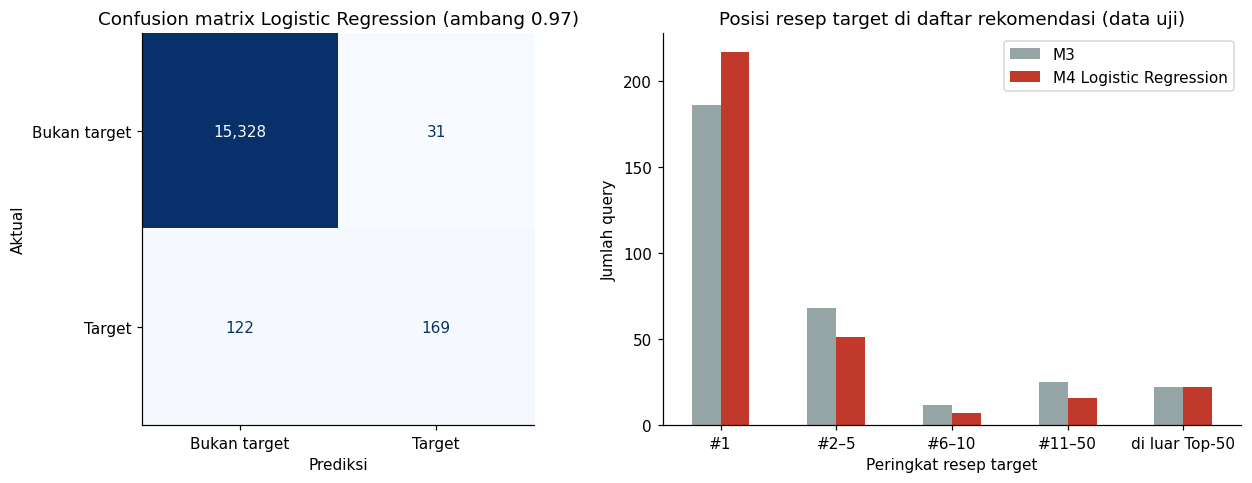

,M3,M4 Logistic Regression
#1,186,217
#2–5,68,51
#6–10,12,7
#11–50,25,16
di luar Top-50,22,22


In [74]:
best_model = fitted_models[best_ml_name]
best_proba = test_proba[best_ml_name]
test_eval = test_df.assign(proba=best_proba, predicted=(best_proba >= best_threshold).astype(int))
test_eval["new_rank"] = test_eval.groupby("query_id")["proba"].rank(ascending=False, method="first")


def target_ranks(rank_column):
    return (test_eval.loc[test_eval["label"] == 1].set_index("query_id")[rank_column]
            .reindex(range(len(test_queries))).fillna(np.inf).to_numpy())


m3_rank_of_target, m4_rank_of_target = target_ranks("m3_rank"), target_ranks("new_rank")
hit_m3, hit_m4 = m3_rank_of_target <= 5, m4_rank_of_target <= 5
only_m4, only_m3 = int((hit_m4 & ~hit_m3).sum()), int((hit_m3 & ~hit_m4).sum())
from types import SimpleNamespace
mcnemar_m4 = (stats.binomtest(only_m4, only_m4 + only_m3, 0.5)
              if only_m4 + only_m3 else SimpleNamespace(pvalue=1.0))
delta = (only_m4 - only_m3) / len(hit_m3)
final_delta_ci = bootstrap_ci(hit_m4.astype(int) - hit_m3.astype(int))
se = np.sqrt(only_m4 + only_m3 - (only_m4 - only_m3) ** 2 / len(hit_m3)) / len(hit_m3)
print(f"M4 ({best_ml_name}) vs M3 pada data uji, HitRate@5: {hit_m4.mean():.3f} vs {hit_m3.mean():.3f}")
print(f"Hanya M4 benar = {only_m4}, hanya M3 benar = {only_m3}, Δ = {delta:+.3f} "
      f"(CI 95% bootstrap [{final_delta_ci[0]:.3f}, {final_delta_ci[1]:.3f}]), McNemar p = {mcnemar_m4.pvalue:.3g}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ConfusionMatrixDisplay(confusion_matrix(y_test, test_eval["predicted"]),
                       display_labels=["Bukan target", "Target"]).plot(ax=axes[0], cmap="Blues", colorbar=False,
                                                                        values_format=",")
axes[0].set_title(f"Confusion matrix {best_ml_name} (ambang {best_threshold:.2f})")
axes[0].set_xlabel("Prediksi")
axes[0].set_ylabel("Aktual")

rank_bins = [0, 1, 5, 10, N_CANDIDATES, np.inf]
rank_labels = ["#1", "#2–5", "#6–10", f"#11–{N_CANDIDATES}", f"di luar Top-{N_CANDIDATES}"]
rank_table = pd.DataFrame({
    "M3": pd.Series(pd.cut(m3_rank_of_target, rank_bins, labels=rank_labels)).value_counts(sort=False),
    f"M4 {best_ml_name}": pd.Series(pd.cut(m4_rank_of_target, rank_bins, labels=rank_labels)).value_counts(sort=False),
})
rank_table.plot.bar(ax=axes[1], color=["#95a5a6", "#c0392b"], rot=0)
axes[1].set_title("Posisi resep target di daftar rekomendasi (data uji)")
axes[1].set_xlabel("Peringkat resep target")
axes[1].set_ylabel("Jumlah query")
plt.tight_layout()
plt.show()
rank_table


In [75]:
display(Markdown(
    f"**Test final, model pilihan CV ({best_ml_name}):** HitRate@5 M3={hit_m3.mean():.3f}; "
    f"M4={hit_m4.mean():.3f}; selisih={delta:+.3f}, CI bootstrap 95%={fmt_ci(final_delta_ci)}, "
    f"McNemar p={mcnemar_m4.pvalue:.3g} ({verdict(mcnemar_m4.pvalue)}). "
    f"{int(np.isinf(m3_rank_of_target).sum())} target tidak masuk kandidat Top-{N_CANDIDATES}; "
    "re-ranker tidak dapat mengambil target yang tidak diretrieve."
))
display(Markdown("Metrik klasifikasi dihitung pada pasangan kandidat yang tersedia. Target yang hilang pada retrieval "
                 "tidak ada dalam confusion matrix, tetapi dihitung gagal dalam metrik ranking end-to-end. "
                 "Skor test tidak dipakai memilih ulang model atau threshold."))


**Test final, model pilihan CV (Logistic Regression):** HitRate@5 M3=0.812; M4=0.856; selisih=+0.045, CI bootstrap 95%=[0.016, 0.077], McNemar p=0.00434 (Tolak H0). 22 target tidak masuk kandidat Top-50; re-ranker tidak dapat mengambil target yang tidak diretrieve.

Metrik klasifikasi dihitung pada pasangan kandidat yang tersedia. Target yang hilang pada retrieval tidak ada dalam confusion matrix, tetapi dihitung gagal dalam metrik ranking end-to-end. Skor test tidak dipakai memilih ulang model atau threshold.

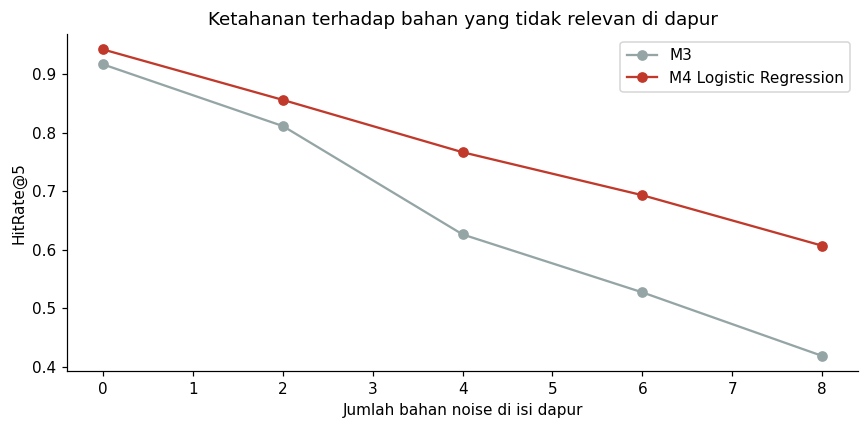

,M3 HitRate@5,M4 HitRate@5,Selisih
Bahan noise,,,
0,0.917,0.942,0.026
2,0.812,0.856,0.045
4,0.626,0.767,0.141
6,0.527,0.693,0.166
8,0.419,0.607,0.188


In [76]:
# Ketahanan terhadap jumlah bahan noise di dapur (termasuk level yang tidak pernah dilihat saat latihan)
rows = []
for n_noise in [0, 2, 4, 6, 8]:
    noisy_df = candidate_features(make_queries(test_idx, keep=0.5, n_noise=n_noise, p_general=0.5, seed=7), test_idx)
    rows.append({"Bahan noise": n_noise,
                 "M3 HitRate@5": rerank_metrics(noisy_df, -noisy_df["m3_rank"])["HitRate@5"],
                 f"M4 HitRate@5": rerank_metrics(noisy_df, best_model.predict_proba(noisy_df[ML_FEATURES])[:, 1])["HitRate@5"]})
noise_robustness = pd.DataFrame(rows).set_index("Bahan noise")
noise_robustness["Selisih"] = noise_robustness["M4 HitRate@5"] - noise_robustness["M3 HitRate@5"]

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(noise_robustness.index, noise_robustness["M3 HitRate@5"], marker="o", color="#95a5a6", label="M3")
ax.plot(noise_robustness.index, noise_robustness["M4 HitRate@5"], marker="o", color="#c0392b", label=f"M4 {best_ml_name}")
ax.set_title("Ketahanan terhadap bahan yang tidak relevan di dapur")
ax.set_xlabel("Jumlah bahan noise di isi dapur")
ax.set_ylabel("HitRate@5")
ax.legend()
plt.tight_layout()
plt.show()
noise_robustness.round(3)

In [77]:
display(Markdown(
    "Tabel sensitivitas noise di atas menilai model yang sudah dibekukan. "
    f"Selisih HitRate@5 minimum={noise_robustness['Selisih'].min():+.3f}; "
    f"maksimum={noise_robustness['Selisih'].max():+.3f}. "
    "Hasil setiap level diperlihatkan apa adanya; tidak diasumsikan M4 unggul di semua kondisi. "
    "Jika hasil digunakan untuk merancang model berikutnya, diperlukan test baru."
))


Tabel sensitivitas noise di atas menilai model yang sudah dibekukan. Selisih HitRate@5 minimum=+0.026; maksimum=+0.188. Hasil setiap level diperlihatkan apa adanya; tidak diasumsikan M4 unggul di semua kondisi. Jika hasil digunakan untuk merancang model berikutnya, diperlukan test baru.

### 6.4 Analisis kesalahan

Diperiksa dua jenis masalah: salah klasifikasi kandidat (FP/FN) dan resep target tidak muncul pada peringkat atas.


In [78]:
outcome = np.select(
    [(test_eval["label"] == 1) & (test_eval["predicted"] == 1), (test_eval["label"] == 1) & (test_eval["predicted"] == 0),
     (test_eval["label"] == 0) & (test_eval["predicted"] == 1)],
    ["TP", "FN", "FP"], default="TN")
test_eval["outcome"] = outcome
key_features = ["proba", "m3_rank", "cos_both", "coverage", "query_used", "idf_owned_mean", "n_missing", "recipe_size"]
print(test_eval["outcome"].value_counts().reindex(["TP", "FN", "FP", "TN"]).to_string())
test_eval.groupby("outcome")[key_features].median().reindex(["TP", "FN", "FP", "TN"]).round(3)

outcome
TP      169
FN      122
FP       31
TN    15328


,proba,m3_rank,cos_both,coverage,query_used,idf_owned_mean,n_missing,recipe_size
outcome,,,,,,,,
TP,0.993,1.0,0.595,0.500,0.750,3.545,5.0,10.0
FN,0.868,2.0,0.545,0.500,0.667,2.313,4.0,8.0
FP,0.978,2.0,0.600,0.545,0.667,2.718,3.0,7.0
TN,0.041,26.0,0.404,0.333,0.500,1.750,6.0,9.0


In [79]:
def ingredient_jaccard(a, b):
    a, b = set(recipe_ingredients[a]), set(recipe_ingredients[b])
    return len(a & b) / len(a | b)


false_positives = test_eval.loc[test_eval["outcome"] == "FP"].copy()
false_positives["jaccard_with_target"] = [ingredient_jaccard(r, t) for r, t in zip(false_positives["recipe"], false_positives["target"])]
all_negatives = test_eval.loc[test_eval["label"] == 0]
negative_jaccard = np.array([ingredient_jaccard(r, t) for r, t in zip(all_negatives["recipe"], all_negatives["target"])])
print(f"Median kemiripan bahan (Jaccard) FP dengan resep target : {false_positives['jaccard_with_target'].median():.2f}")
print(f"Median kemiripan bahan semua kandidat negatif dengan target: {np.median(negative_jaccard):.2f}")
print(f"FP yang berbagi >= 50% bahan dengan target: {(false_positives['jaccard_with_target'] >= 0.5).mean():.1%}")

examples = false_positives.sort_values("proba", ascending=False).head(8)
pd.DataFrame({
    "Isi dapur": [", ".join(test_queries[q]) for q in examples["query_id"]],
    "Kandidat (FP)": recipes.loc[examples["recipe"], "recipe_title"].to_numpy(),
    "Resep target": recipes.loc[examples["target"], "recipe_title"].to_numpy(),
    "Prob": examples["proba"].round(3).to_numpy(),
    "Jaccard dgn target": examples["jaccard_with_target"].round(2).to_numpy(),
})

Median kemiripan bahan (Jaccard) FP dengan resep target : 0.33
Median kemiripan bahan semua kandidat negatif dengan target: 0.19
FP yang berbagi >= 50% bahan dengan target: 25.8%


,Isi dapur,Kandidat (FP),Resep target,Prob,Jaccard dgn target
0,"old world traditional sauce, water, part skim mozzarella cheese, reduced fat...",RAGÚ No Boiling Beefy Baked Ziti,RAGÚ No-Frying Eggplant Parmesan,0.995,0.36
1,"marinated mozzarella, olive, dried basil, olive oil",Air Fryer Polenta Pizza Bites,Festive Olive and Cheese Appetizer,0.994,0.00
2,"vegetable oil, flour, squid, oregano, spinach, cornmeal",Calamari,Buttermilk-Battered Calamari,0.993,0.75
3,"italian seasoning, garlic, mozzarella, spaghetti sauce",Cheese Lasagna,Cream Cheese and Parmesan Bread Spread,0.992,0.23
4,"mozzarella, pepperoni, garlic salt, parmesan",Copycat Crazy Puffs,Pizza Pinwheels,0.991,0.27
5,"french baguette, parmesan, butter, red pepper flake, salt",Crostini,Prosciutto Parmesan and Pine Nut Bruschetta,0.991,0.44
6,"salt, italian seasoning, active dry yeast, olive oil, garlic granule, flatbr...",One Pot Chicken Pomodoro,Parmesan-Herb Breadsticks,0.990,0.25
7,"italian seasoning, garlic, mozzarella, spaghetti sauce",Italian Stuffed Pasta Tubes,Cream Cheese and Parmesan Bread Spread,0.990,0.09


Query gagal Top-5 M4: 45 dari 313
Re-rank: target di kandidat, peringkat > 5    23
Retrieve: target di luar Top-50               22


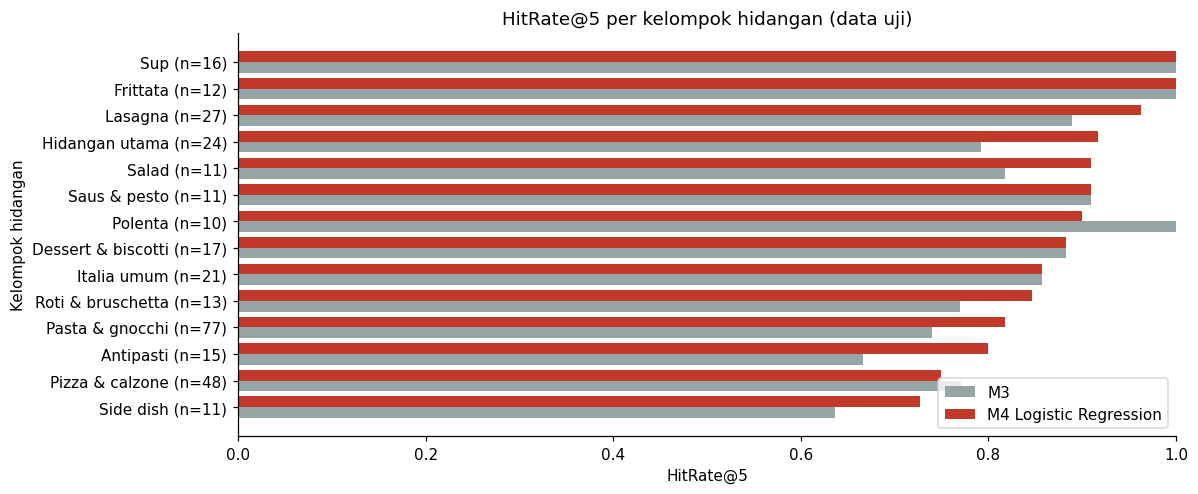

,n,M3,M4,Selisih
Kelompok,,,,
Side dish,11,0.636,0.727,0.091
Pizza & calzone,48,0.771,0.750,-0.021
Antipasti,15,0.667,0.800,0.133
Pasta & gnocchi,77,0.740,0.818,0.078
Roti & bruschetta,13,0.769,0.846,0.077
Italia umum,21,0.857,0.857,0.000
Dessert & biscotti,17,0.882,0.882,0.000
Polenta,10,1.000,0.900,-0.100
Saus & pesto,11,0.909,0.909,0.000


In [80]:
miss = ~hit_m4
failure_reason = pd.Series(np.where(np.isinf(m3_rank_of_target[miss]), f"Retrieve: target di luar Top-{N_CANDIDATES}",
                                    "Re-rank: target di kandidat, peringkat > 5")).value_counts()
print(f"Query gagal Top-5 M4: {miss.sum()} dari {len(miss)}")
print(failure_reason.to_string())

test_groups_ml = recipes.loc[test_idx, "dish_group"].to_numpy()
group_hits = pd.DataFrame({"Kelompok": test_groups_ml, "M3": hit_m3, "M4": hit_m4}).groupby("Kelompok").agg(
    n=("M3", "size"), M3=("M3", "mean"), M4=("M4", "mean"))
group_hits = group_hits.assign(Selisih=group_hits["M4"] - group_hits["M3"]).sort_values("M4")

fig, ax = plt.subplots(figsize=(11, 4.6))
y = np.arange(len(group_hits))
ax.barh(y - 0.2, group_hits["M3"], 0.4, color="#95a5a6", label="M3")
ax.barh(y + 0.2, group_hits["M4"], 0.4, color="#c0392b", label=f"M4 {best_ml_name}")
ax.set_yticks(y, [f"{name} (n={n})" for name, n in zip(group_hits.index, group_hits["n"])])
ax.set_xlim(0, 1)
ax.set_title("HitRate@5 per kelompok hidangan (data uji)")
ax.set_xlabel("HitRate@5")
ax.set_ylabel("Kelompok hidangan")
ax.legend()
plt.tight_layout()
plt.show()
group_hits.round(3)

In [81]:
display(Markdown(
    f"**Diagnosis:** {int((test_eval['outcome']=='FP').sum())} FP dan "
    f"{int((test_eval['outcome']=='FN').sum())} FN pada threshold OOF. "
    f"{int((~hit_m4).sum())}/{len(hit_m4)} query gagal Top-5; rincian retrieval/re-ranking "
    "dan karakteristik setiap outcome tersedia di atas. Kandidat mirip target mungkin tetap relevan, "
    "tetapi ini belum divalidasi pengguna; tidak dinyatakan semua FP 'benar' atau metrik pasti meremehkan kualitas."
))
display(group_hits.round(4))


**Diagnosis:** 31 FP dan 122 FN pada threshold OOF. 45/313 query gagal Top-5; rincian retrieval/re-ranking dan karakteristik setiap outcome tersedia di atas. Kandidat mirip target mungkin tetap relevan, tetapi ini belum divalidasi pengguna; tidak dinyatakan semua FP 'benar' atau metrik pasti meremehkan kualitas.

,n,M3,M4,Selisih
Kelompok,,,,
Side dish,11,0.6364,0.7273,0.0909
Pizza & calzone,48,0.7708,0.7500,-0.0208
Antipasti,15,0.6667,0.8000,0.1333
Pasta & gnocchi,77,0.7403,0.8182,0.0779
Roti & bruschetta,13,0.7692,0.8462,0.0769
Italia umum,21,0.8571,0.8571,0.0000
Dessert & biscotti,17,0.8824,0.8824,0.0000
Polenta,10,1.0000,0.9000,-0.1000
Saus & pesto,11,0.9091,0.9091,0.0000


### 6.5 Memahami alasan model

Permutation importance menunjukkan fitur yang paling membantu prediksi. Koefisien Logistic Regression dan SHAP dipakai untuk melihat arah serta kontribusi fitur. Ini menunjukkan pola model, bukan sebab-akibat.


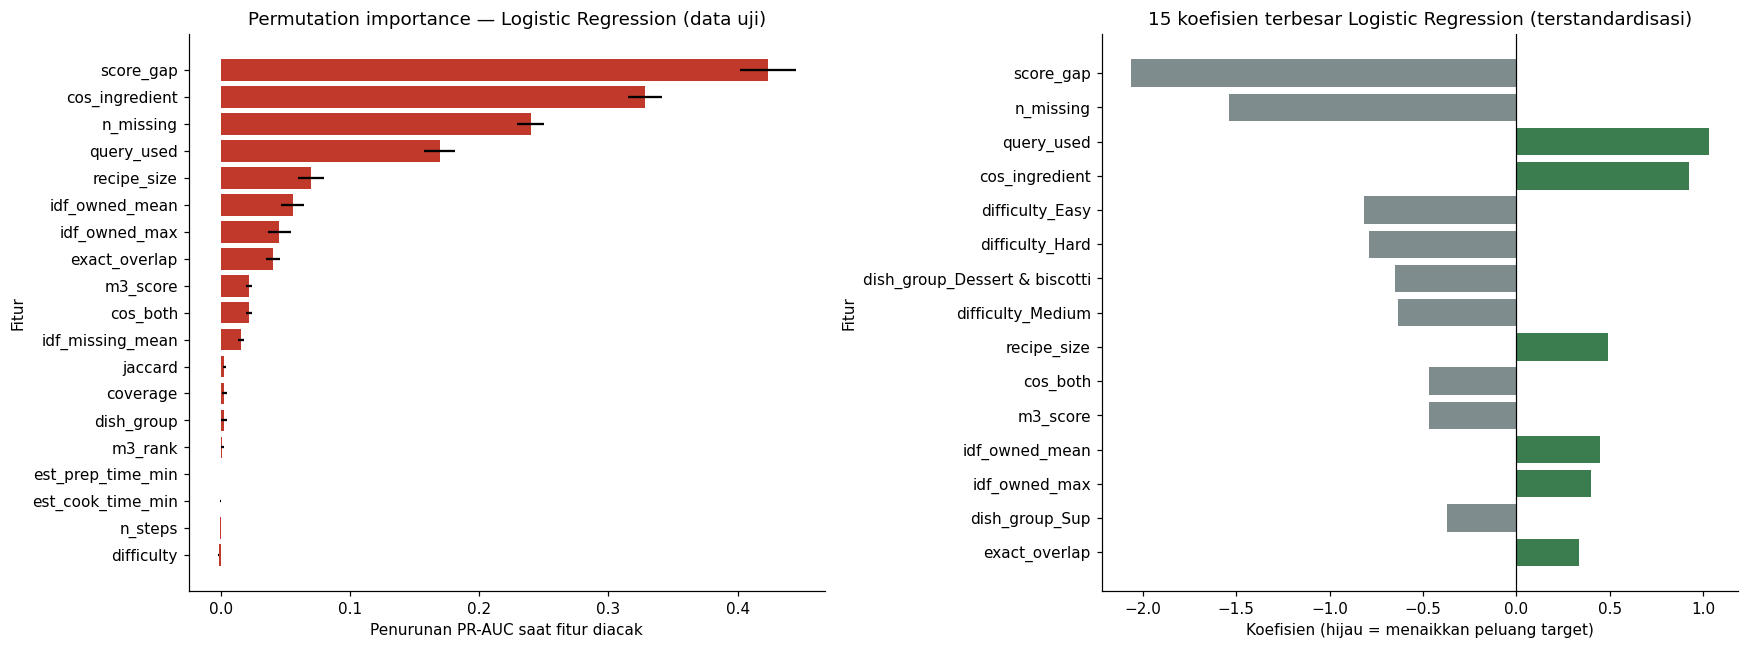

,Fitur,Penurunan PR-AUC,std,Koef. LogReg
2,score_gap,0.4237,0.0216,-2.0660
4,cos_ingredient,0.3286,0.0131,0.9234
8,n_missing,0.2400,0.0105,-1.5399
9,query_used,0.1697,0.0120,1.0318
13,recipe_size,0.0699,0.0101,0.4904
10,idf_owned_mean,0.0557,0.0088,0.4486
11,idf_owned_max,0.0453,0.0089,0.4010
5,exact_overlap,0.0405,0.0051,0.3351
1,m3_score,0.0223,0.0023,-0.4705
3,cos_both,0.0223,0.0023,-0.4705


In [82]:
importance = permutation_importance(best_model, X_test, y_test, scoring="average_precision",
                                    n_repeats=5, random_state=42, n_jobs=N_JOBS)
importance_table = pd.DataFrame({"Fitur": ML_FEATURES, "Penurunan PR-AUC": importance.importances_mean,
                                 "std": importance.importances_std}).sort_values("Penurunan PR-AUC")

logreg = fitted_models["Logistic Regression"]
coef_names = list(ML_NUMERIC) + list(logreg.named_steps["prep"].named_transformers_["cat"].get_feature_names_out(ML_CATEGORICAL))
coef_table = pd.Series(logreg.named_steps["clf"].coef_[0], index=coef_names)
coef_top = coef_table.reindex(coef_table.abs().sort_values().index[-15:])

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
axes[0].barh(importance_table["Fitur"], importance_table["Penurunan PR-AUC"], xerr=importance_table["std"],
             color="#c0392b")
axes[0].set_title(f"Permutation importance — {best_ml_name} (data uji)")
axes[0].set_xlabel("Penurunan PR-AUC saat fitur diacak")
axes[0].set_ylabel("Fitur")
axes[1].barh(coef_top.index, coef_top.values, color=np.where(coef_top.values > 0, "#3b7d4f", "#7f8c8d"))
axes[1].axvline(0, color="black", lw=0.8)
axes[1].set_title("15 koefisien terbesar Logistic Regression (terstandardisasi)")
axes[1].set_xlabel("Koefisien (hijau = menaikkan peluang target)")
axes[1].set_ylabel("Fitur")
plt.tight_layout()
plt.show()
importance_table.assign(**{"Koef. LogReg": importance_table["Fitur"].map(coef_table)}).sort_values(
    "Penurunan PR-AUC", ascending=False).head(12).round(4)


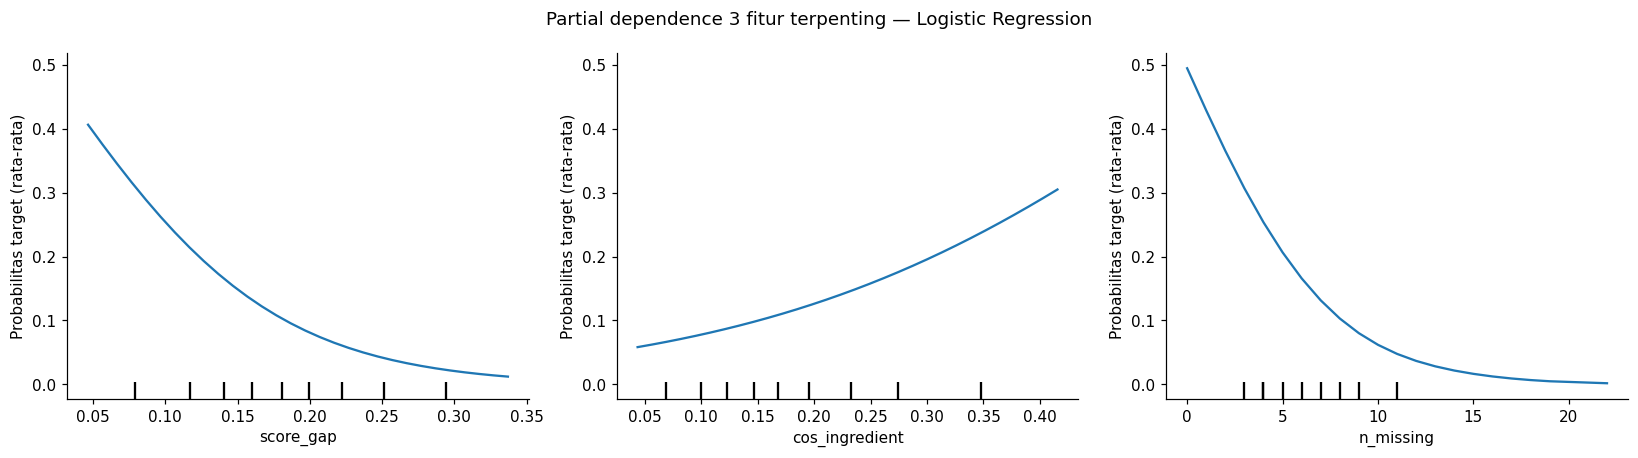

In [83]:
top_numeric = [f for f in importance_table.sort_values("Penurunan PR-AUC", ascending=False)["Fitur"] if f in ML_NUMERIC][:3]
fig, axes = plt.subplots(1, len(top_numeric), figsize=(15, 4.2))
PartialDependenceDisplay.from_estimator(best_model, X_test.sample(min(1500, len(X_test)), random_state=42).astype({c: float for c in ML_NUMERIC}), top_numeric,
                                        ax=axes, grid_resolution=30)
for ax in axes:
    ax.set_ylabel("Probabilitas target (rata-rata)")
fig.suptitle(f"Partial dependence 3 fitur terpenting — {best_ml_name}")
plt.tight_layout()
plt.show()


Sampel SHAP: 291 positif + 1500 negatif.
Uji additivitas SHAP terhadap output model: LULUS.


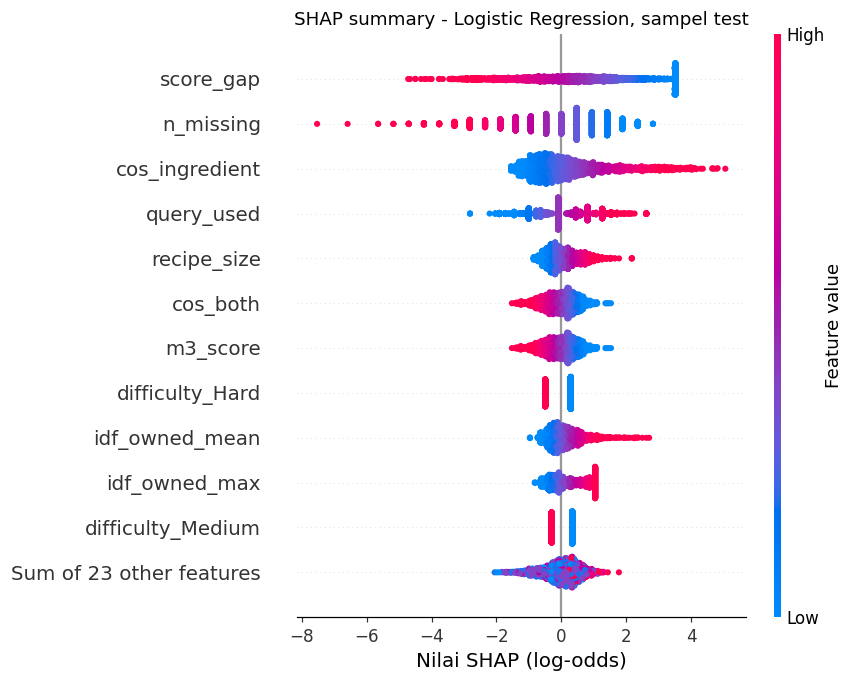

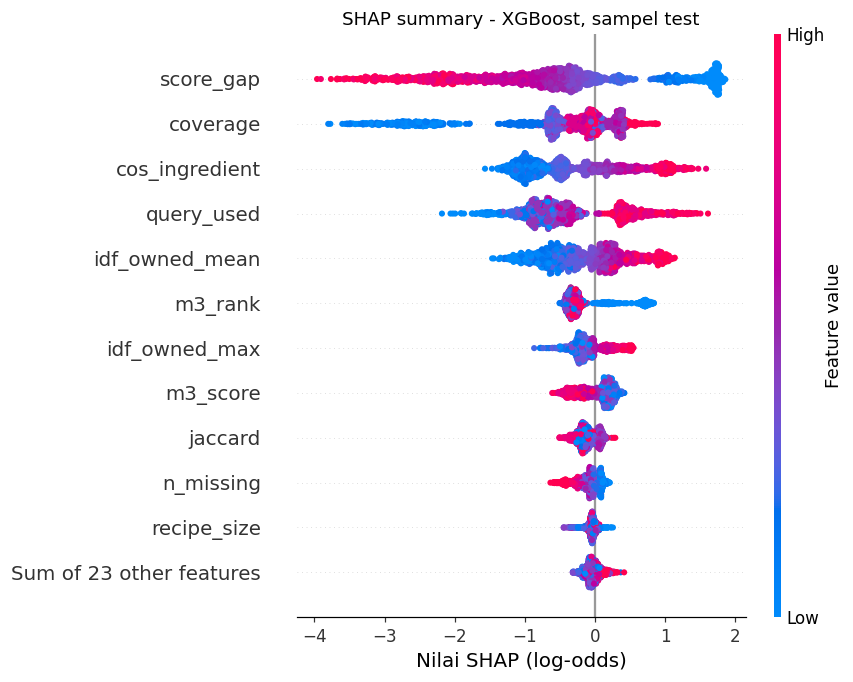

,Logistic Regression,XGBoost
score_gap,1.4752,1.1872
n_missing,1.2060,0.1305
cos_ingredient,0.9060,0.6970
query_used,0.7240,0.6845
recipe_size,0.4053,0.0561
cos_both,0.3982,0.0446
m3_score,0.3982,0.2036
idf_owned_mean,0.3807,0.4702
idf_owned_max,0.3667,0.2120
exact_overlap,0.2441,0.0331


Sampel diperkaya positif, sehingga besar importance tidak mewakili prevalensi produksi.


In [84]:
import shap

def transformed_names(pipeline):
    onehot = pipeline.named_steps["prep"].named_transformers_["cat"]
    return ML_NUMERIC + list(onehot.get_feature_names_out(ML_CATEGORICAL))

def shap_explanation(name, X_rows, background):
    pipeline = fitted_models[name]
    prep, clf = pipeline.named_steps["prep"], pipeline.named_steps["clf"]
    imputed_rows = pipeline.named_steps["time_impute"].transform(X_rows)
    imputed_background = pipeline.named_steps["time_impute"].transform(background)
    transformed = prep.transform(imputed_rows)
    if isinstance(clf, LogisticRegression):
        explainer = shap.LinearExplainer(
            clf, shap.maskers.Independent(prep.transform(imputed_background), max_samples=len(background))
        )
    else:
        explainer = shap.TreeExplainer(clf)
    explanation = explainer(transformed)
    values, bases = explanation.values, explanation.base_values
    # RandomForest pada SHAP versi ini mengembalikan dimensi kelas sebagai axis terakhir.
    if values.ndim == 3:
        values = values[:, :, 1]
        bases = np.asarray(bases)[:, 1]
    raw = np.column_stack([imputed_rows[ML_NUMERIC].to_numpy(dtype=float), transformed[:,len(ML_NUMERIC):]])
    result = shap.Explanation(values=values, base_values=bases, data=raw,
                              feature_names=transformed_names(pipeline))
    totals = np.asarray(bases) + values.sum(axis=1)
    if isinstance(clf, LogisticRegression):
        expected = clf.decision_function(transformed)
    elif isinstance(clf, RandomForestClassifier):
        expected = clf.predict_proba(transformed)[:,1]
    elif isinstance(clf, XGBClassifier):
        expected = clf.predict(transformed, output_margin=True)
    else:
        expected = clf.decision_function(transformed)
    assert np.allclose(totals, expected, atol=1e-4), "Additivitas SHAP tidak sesuai output model."
    return result

positives = test_df[test_df["label"] == 1]
negatives = test_df[test_df["label"] == 0]
shap_rows = pd.concat([positives, negatives.sample(min(1500,len(negatives)), random_state=42)])
shap_background = X_train.sample(min(300,len(X_train)), random_state=42)
shap_models = list(dict.fromkeys([best_ml_name, "Logistic Regression", "XGBoost"]))
shap_values = {name:shap_explanation(name,shap_rows[ML_FEATURES],shap_background) for name in shap_models}
print("Sampel SHAP:",len(positives),"positif +",len(shap_rows)-len(positives),"negatif.")
print("Uji additivitas SHAP terhadap output model: LULUS.")
for name in shap_models:
    plt.figure()
    shap.plots.beeswarm(shap_values[name], max_display=12, show=False)
    plt.title(f"SHAP summary - {name}, sampel test")
    shap_unit = "probabilitas" if isinstance(fitted_models[name].named_steps["clf"], RandomForestClassifier) else "log-odds"
    plt.xlabel(f"Nilai SHAP ({shap_unit})")
    plt.tight_layout()
    plt.show()

def grouped_shap_importance(explanation):
    values = pd.DataFrame(explanation.values, columns=explanation.feature_names)
    for feature in ML_CATEGORICAL:
        columns = [column for column in values if column.startswith(feature+"_")]
        values[feature+" (gabungan)"] = values[columns].sum(axis=1)
        values = values.drop(columns=columns)
    return values.abs().mean()

shap_global_table = pd.DataFrame({
    name:grouped_shap_importance(explanation) for name,explanation in shap_values.items()
})
display(shap_global_table.sort_values(best_ml_name,ascending=False).round(4))
print("Sampel diperkaya positif, sehingga besar importance tidak mewakili prevalensi produksi.")


Jumlah target naik dari >5 menjadi #1: 3.
Aturan contoh: target terselamatkan pertama
Isi dapur: ['mustard', 'flour', 'gnocchi', 'heavy cream', 'garlic', 'black pepper']
Target: Gnocchi Mac and Cheese
Rank M3: 12.0 ; rank M4: 1.0


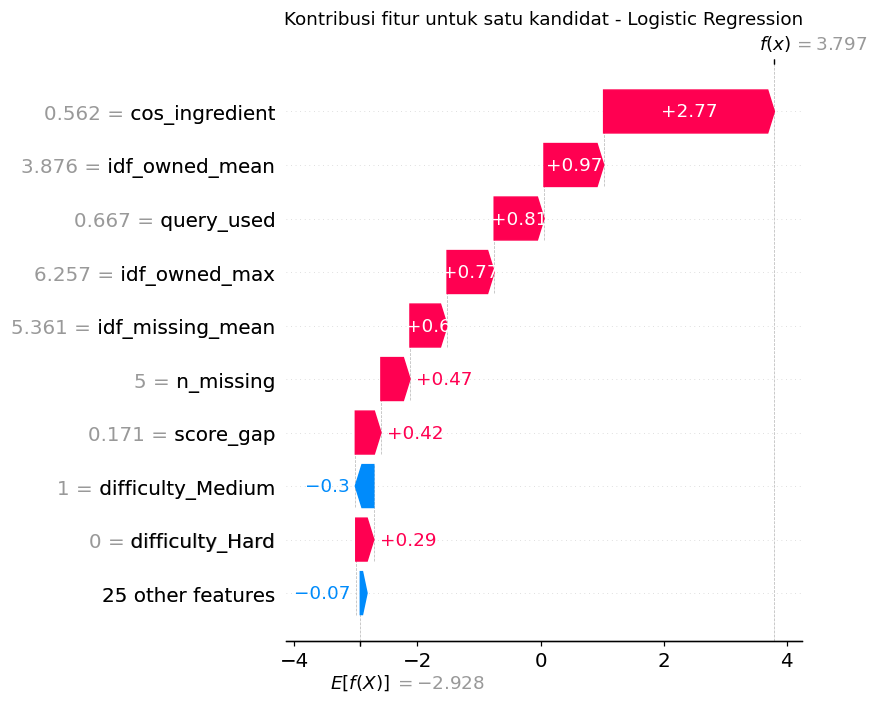

,Nilai fitur,SHAP
cos_ingredient,0.5617,2.7723
idf_owned_mean,3.8761,0.9691
query_used,0.6667,0.8087
idf_owned_max,6.2570,0.7652
idf_missing_mean,5.3607,0.6031
n_missing,5.0000,0.4721
score_gap,0.1710,0.4153
difficulty_Medium,1.0000,-0.2989
difficulty_Hard,0.0000,0.2917
exact_overlap,4.0000,0.2406


In [85]:
rescued = np.flatnonzero((m3_rank_of_target > 5) & (m4_rank_of_target == 1))
available_targets = test_eval.loc[test_eval["label"] == 1, "query_id"].unique()
if len(available_targets):
    example_query = int(rescued[0] if len(rescued) else available_targets[0])
    example_row = test_eval[(test_eval["query_id"] == example_query) & (test_eval["label"] == 1)]
    print(f"Jumlah target naik dari >5 menjadi #1: {len(rescued)}.")
    print("Aturan contoh:", "target terselamatkan pertama" if len(rescued) else "target tersedia pertama (fallback)")
    print("Isi dapur:", test_queries[example_query])
    print("Target:",recipes.loc[int(example_row["recipe"].iloc[0]),"recipe_title"])
    print("Rank M3:",m3_rank_of_target[example_query],"; rank M4:",m4_rank_of_target[example_query])
    local = shap_explanation(best_ml_name, example_row[ML_FEATURES], shap_background)
    plt.figure()
    shap.plots.waterfall(local[0], max_display=10, show=False)
    plt.title(f"Kontribusi fitur untuk satu kandidat - {best_ml_name}")
    plt.tight_layout()
    plt.show()
    local_table = pd.DataFrame({"Nilai fitur":local[0].data,"SHAP":local[0].values}, index=local.feature_names)
    display(local_table.reindex(local_table["SHAP"].abs().sort_values(ascending=False).index).head(10).round(4))
else:
    print("Tidak ada target dalam kandidat; contoh SHAP lokal target tidak tersedia.")


Interpretasi terukur: fitur dengan penurunan AP terbesar saat diacak adalah score_gap, sebesar 0.4247. Bandingkan dengan SHAP dan koefisien pada tabel. Besar koefisien/SHAP tidak membuktikan efek kausal; fitur turunan seperti coverage, jumlah bahan kurang dan ukuran resep saling bergantung. One-hot diperiksa sebagai satu kelompok fitur agar kontribusi kolom tidak disalahartikan. Klaim fitur tabular tidak berguna hanya boleh dibuat setelah melihat importance dan ablation yang sesuai.

# 7.1 Utilitas CV, pembangun model, dan uji reproduksi

In [86]:
# 7.1 Utilitas CV, pembangun model, dan uji reproduksi (semua didefinisikan di notebook ini)
import time

from sklearn.base import BaseEstimator
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.metrics import accuracy_score, balanced_accuracy_score
from xgboost import XGBRanker

QUICK_MODE = False   # True = percobaan sangat sedikit, hanya untuk mengecek bahwa kode berjalan
X_tune = train_df[ML_FEATURES + ["query_id"]]   # query_id hanya dipakai XGBQueryRanker; model lain mengabaikannya


def make_pipeline(clf, scale=False):
    """Pipeline M4 yang sama dengan ML_MODELS (bagian 6.2): imputasi waktu -> preprocessor -> model."""
    return Pipeline([
        ("time_impute", GroupTimeImputer()),
        ("prep", make_preprocessor(scale=scale)),
        ("clf", clf),
    ])


class XGBQueryRanker(BaseEstimator):
    """Learning-to-Rank (XGBRanker): mengoptimalkan urutan kandidat di dalam tiap query.

    fit(X, y) membutuhkan kolom `query_id` pada X untuk membentuk grup ranking.
    predict_proba mengembalikan skor yang dipetakan sigmoid agar kompatibel dengan model klasifikasi lain.
    """

    def __init__(self, n_estimators=200, max_depth=4, learning_rate=0.05, subsample=0.8,
                 colsample_bytree=0.8, min_child_weight=5, reg_lambda=1.0, gamma=0.0,
                 objective="rank:pairwise", n_jobs=N_JOBS, random_state=42):
        self.n_estimators = n_estimators
        self.max_depth = max_depth
        self.learning_rate = learning_rate
        self.subsample = subsample
        self.colsample_bytree = colsample_bytree
        self.min_child_weight = min_child_weight
        self.reg_lambda = reg_lambda
        self.gamma = gamma
        self.objective = objective
        self.n_jobs = n_jobs
        self.random_state = random_state

    def fit(self, X, y):
        qid = X["query_id"].to_numpy()
        order = np.argsort(qid, kind="stable")          # XGBRanker membutuhkan baris terurut per query
        X_sorted = X.iloc[order]
        self.pre_ = Pipeline([("time_impute", GroupTimeImputer()), ("prep", make_preprocessor(scale=False))])
        features = self.pre_.fit_transform(X_sorted[ML_FEATURES])
        self.model_ = XGBRanker(
            n_estimators=self.n_estimators, max_depth=self.max_depth, learning_rate=self.learning_rate,
            subsample=self.subsample, colsample_bytree=self.colsample_bytree,
            min_child_weight=self.min_child_weight, reg_lambda=self.reg_lambda, gamma=self.gamma,
            objective=self.objective, tree_method="hist", n_jobs=self.n_jobs, random_state=self.random_state)
        self.model_.fit(features, np.asarray(y)[order], qid=qid[order])
        self.classes_ = np.array([0, 1])
        return self

    def decision_function(self, X):
        return np.asarray(self.model_.predict(self.pre_.transform(X[ML_FEATURES])), dtype=float)

    def predict_proba(self, X):
        p = 1.0 / (1.0 + np.exp(-np.clip(self.decision_function(X), -30, 30)))
        return np.column_stack([1.0 - p, p])


def build_cv_splits():
    """Fold yang sama dengan run_cv(hold_out_scenario=True) di bagian 6.2 dan cv_score() milik Optuna."""
    cv = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=42)
    splits = []
    for fold, (tr, va) in enumerate(cv.split(X_train, y_train, groups_train)):
        assert not set(groups_train[tr]) & set(groups_train[va])
        tr, va = tr[scenario_train[tr] != fold], va[scenario_train[va] == fold]
        splits.append((tr, va))
    return splits


CV_SPLITS = build_cv_splits()


def cv_scores(model, splits=None, return_oof=False):
    """Rata-rata metrik per fold; opsional mengembalikan prediksi out-of-fold."""
    splits = CV_SPLITS if splits is None else splits
    oof_pred = np.full(len(train_df), np.nan)
    rows = []
    for tr, va in splits:
        fitted = clone(model).fit(X_tune.iloc[tr], y_train[tr])
        proba = fitted.predict_proba(X_tune.iloc[va])[:, 1]
        oof_pred[va] = proba
        rows.append({"ROC-AUC": roc_auc_score(y_train[va], proba),
                     "PR-AUC": average_precision_score(y_train[va], proba),
                     **rerank_metrics(train_df.iloc[va], proba)})
    frame = pd.DataFrame(rows)
    summary = frame.mean().to_dict()
    summary["HitRate@5 std"] = float(frame["HitRate@5"].std())
    return (summary, oof_pred) if return_oof else summary


def hit5_scorer(estimator, X, y):
    """Scorer GridSearchCV: HitRate@5 setelah kandidat tiap query diurutkan ulang."""
    return rerank_metrics(train_df.loc[X.index], estimator.predict_proba(X)[:, 1])["HitRate@5"]


GRID_SCORING = {"HitRate@5": hit5_scorer, "PR-AUC": "average_precision"}

# Pembangun model: parameter bawaan identik dengan ML_MODELS di bagian 6.2
SPW_DEFAULT = float((y_train == 0).sum() / (y_train == 1).sum())
BUILDERS = {
    "Logistic Regression": lambda **p: make_pipeline(
        LogisticRegression(**{"max_iter": 3000, "class_weight": "balanced", "C": 1.0, **p}), scale=True),
    "Random Forest": lambda **p: make_pipeline(RandomForestClassifier(**{
        "n_estimators": 150, "min_samples_leaf": 5, "max_features": "sqrt",
        "class_weight": "balanced_subsample", "n_jobs": N_JOBS, "random_state": 42, **p})),
    "HistGradientBoosting": lambda **p: make_pipeline(HistGradientBoostingClassifier(**{
        "learning_rate": 0.05, "max_iter": 200, "max_leaf_nodes": 31, "l2_regularization": 1.0,
        "class_weight": "balanced", "random_state": 42, **p})),
    "XGBoost": lambda **p: make_pipeline(XGBClassifier(**{
        "n_estimators": 150, "max_depth": 4, "learning_rate": 0.05, "subsample": 0.8, "colsample_bytree": 0.8,
        "min_child_weight": 5, "reg_lambda": 1.0, "scale_pos_weight": SPW_DEFAULT, "tree_method": "hist",
        "eval_metric": "aucpr", "n_jobs": N_JOBS, "random_state": 42, **p})),
    "ExtraTrees": lambda **p: make_pipeline(ExtraTreesClassifier(**{
        "n_estimators": 200, "min_samples_leaf": 5, "max_features": "sqrt",
        "class_weight": "balanced", "n_jobs": N_JOBS, "random_state": 42, **p})),
    "LTR XGBRanker": lambda **p: XGBQueryRanker(**p),
}

# Uji reproduksi: protokol CV di sini harus menghasilkan angka yang sama dengan bagian 6.2
reference = cv_results.loc[cv_results["Model"] == "Logistic Regression", "HitRate@5"].mean()
check = cv_scores(clone(ML_MODELS["Logistic Regression"]))["HitRate@5"]
assert np.isclose(check, reference, atol=1e-9), f"Protokol CV berbeda: {check} vs {reference}"
print(f"Uji reproduksi protokol CV: LULUS (HitRate@5 Logistic Regression = {check:.4f}).")

Uji reproduksi protokol CV: LULUS (HitRate@5 Logistic Regression = 0.7318).


### 7.2 Model pembanding (parameter bawaan) vs 4 model asli, protokol CV skenario tertahan

**Penjelasan model pembanding.**

- **ExtraTrees (Extremely Randomized Trees):** mirip Random Forest, tetapi titik pemisahan tiap node dipilih acak, bukan dicari yang terbaik. Hasilnya lebih halus dan variansnya lebih rendah. Dipakai sebagai pembanding langsung Random Forest untuk tugas re-ranking.
- **XGBRanker (Learning-to-Rank):** tidak memprediksi label per baris, tetapi mengoptimalkan **urutan kandidat dalam satu query** (`rank:pairwise`). Ini paling selaras dengan tujuan HitRate@5, karena yang penting adalah resep benar berada di atas kandidat lain pada query yang sama.

Logistic Regression: HitRate@5=0.7318, PR-AUC=0.5807 (5 dtk)
Random Forest: HitRate@5=0.6807, PR-AUC=0.4673 (52 dtk)
HistGradientBoosting: HitRate@5=0.6307, PR-AUC=0.4634 (11 dtk)
XGBoost: HitRate@5=0.6115, PR-AUC=0.3503 (5 dtk)
ExtraTrees: HitRate@5=0.6935, PR-AUC=0.5108 (30 dtk)
LTR XGBRanker: HitRate@5=0.6264, PR-AUC=0.3976 (9 dtk)


,HitRate@5,HitRate@10,MRR@10,NDCG@10,ROC-AUC,PR-AUC
Logistic Regression,0.7318,0.7818,0.6501,0.6818,0.9392,0.5807
ExtraTrees,0.6935,0.7542,0.6148,0.6480,0.9167,0.5108
Random Forest,0.6807,0.7329,0.5863,0.6216,0.8976,0.4673
HistGradientBoosting,0.6307,0.6733,0.5506,0.5801,0.8603,0.4634
LTR XGBRanker,0.6264,0.6999,0.5341,0.5736,0.8784,0.3976
XGBoost,0.6115,0.6850,0.5057,0.5485,0.8715,0.3503


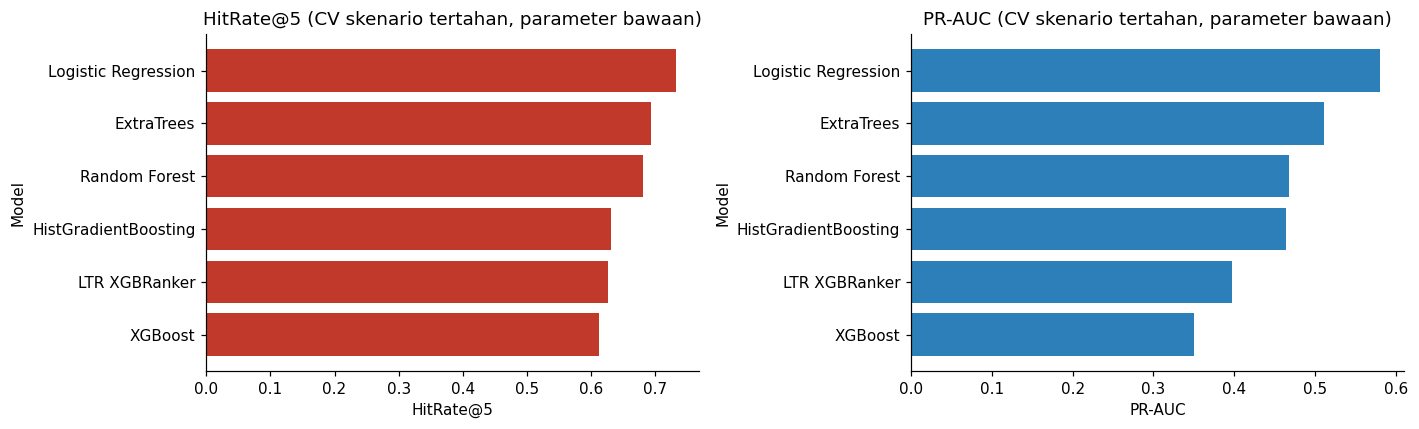

Layak di-tuning (selisih <= 0,03 dari terbaik): ['Logistic Regression']


In [87]:
# 7.2 Model pembanding (parameter bawaan) vs 4 model asli, protokol CV skenario tertahan
DEFAULT_MODEL_NAMES = ["Logistic Regression", "Random Forest", "HistGradientBoosting", "XGBoost",
                       "ExtraTrees", "LTR XGBRanker"]
cv_default = {}
for name in DEFAULT_MODEL_NAMES:
    start = time.time()
    cv_default[name] = cv_scores(BUILDERS[name]())
    print(f"{name}: HitRate@5={cv_default[name]['HitRate@5']:.4f}, PR-AUC={cv_default[name]['PR-AUC']:.4f} "
          f"({time.time() - start:.0f} dtk)", flush=True)

default_table = pd.DataFrame(cv_default).T[["HitRate@5", "HitRate@10", "MRR@10", "NDCG@10", "ROC-AUC", "PR-AUC"]]
default_table = default_table.sort_values("HitRate@5", ascending=False)
display(default_table.round(4))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].barh(default_table.index[::-1], default_table["HitRate@5"][::-1], color="#c0392b")
axes[0].set_title("HitRate@5 (CV skenario tertahan, parameter bawaan)")
axes[0].set_xlabel("HitRate@5")
axes[0].set_ylabel("Model")
axes[1].barh(default_table.index[::-1], default_table["PR-AUC"][::-1], color="#2c7fb8")
axes[1].set_title("PR-AUC (CV skenario tertahan, parameter bawaan)")
axes[1].set_xlabel("PR-AUC")
axes[1].set_ylabel("Model")
plt.tight_layout()
plt.show()

# Syarat tahap 4: hanya model yang dekat dengan yang terbaik yang layak di-tuning
best_cv = default_table["HitRate@5"].max()
contenders = default_table[default_table["HitRate@5"] >= best_cv - 0.03].index.tolist()
print("Layak di-tuning (selisih <= 0,03 dari terbaik):", contenders)

## 8. Persiapan tuning

In [88]:
# 8.0 Persiapan tuning
import optuna
from optuna.samplers import TPESampler
optuna.logging.set_verbosity(optuna.logging.WARNING)
from sklearn.model_selection import GridSearchCV

if QUICK_MODE:
    N_TRIALS = {"XGBRanker": 4, "ExtraTrees": 3}
    GRID_LR = {"clf__C": [0.1, 1.0, 10.0]}
    GRID_HGB = {"clf__learning_rate": [0.05, 0.1], "clf__max_leaf_nodes": [15, 31]}
else:
    N_TRIALS = {"XGBRanker": 25, "ExtraTrees": 20}
    GRID_LR = {"clf__C": [0.01, 0.03, 0.1, 0.3, 1.0, 3.0, 10.0, 30.0], "clf__class_weight": ["balanced", None]}
    GRID_HGB = {"clf__learning_rate": [0.03, 0.05, 0.1], "clf__max_leaf_nodes": [15, 31],
                "clf__l2_regularization": [1.0, 10.0]}

tuning_records = []    # satu baris per (model, metode)
search_histories = {}  # riwayat percobaan untuk grafik


def finish_tuning(name, method, params, n_evaluations, seconds):
    score = cv_scores(BUILDERS[name](**params))
    tuning_records.append({
        "Model": name, "Metode": method,
        "CV HitRate@5": score["HitRate@5"], "CV PR-AUC": score["PR-AUC"], "CV MRR@10": score["MRR@10"],
        "Percobaan": n_evaluations, "Waktu (detik)": round(seconds, 1), "Parameter": params,
    })
    print(f"{name} | {method}: CV HitRate@5={score['HitRate@5']:.4f} "
          f"(bawaan {cv_default[name]['HitRate@5']:.4f}); parameter={params}")


def run_grid(name, param_grid):
    start = time.time()
    search = GridSearchCV(BUILDERS[name](), param_grid, scoring=GRID_SCORING, refit=False,
                          cv=CV_SPLITS, n_jobs=1, error_score="raise")
    search.fit(X_tune, y_train)
    results = pd.DataFrame(search.cv_results_)
    ordered = results.sort_values(["mean_test_HitRate@5", "mean_test_PR-AUC"], ascending=False)
    best_params_grid = {k.replace("clf__", ""): v for k, v in ordered.iloc[0]["params"].items()}
    search_histories[(name, "Grid Search")] = results["mean_test_HitRate@5"].to_numpy()
    display(ordered[["params", "mean_test_HitRate@5", "mean_test_PR-AUC"]].head(8).round(4))
    finish_tuning(name, "Grid Search", best_params_grid, len(results), time.time() - start)


def run_bayes(name, space_fn, default_params, n_trials, seed=42):
    start = time.time()

    def objective(trial):
        params = space_fn(trial)
        score = cv_scores(BUILDERS[name](**params))
        trial.set_user_attr("PR-AUC", score["PR-AUC"])
        return score["HitRate@5"]

    study = optuna.create_study(direction="maximize", sampler=TPESampler(seed=seed))
    study.enqueue_trial(default_params)   # parameter bawaan = percobaan pertama
    study.optimize(objective, n_trials=n_trials, show_progress_bar=False)
    search_histories[(name, "Bayesian (Optuna TPE)")] = np.array([t.value for t in study.trials])
    finish_tuning(name, "Bayesian (Optuna TPE)", dict(study.best_params), len(study.trials), time.time() - start)
    return study


def space_ltr(trial):
    return {"n_estimators": trial.suggest_int("n_estimators", 100, 500, step=50),
            "max_depth": trial.suggest_int("max_depth", 2, 8),
            "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.2, log=True),
            "subsample": trial.suggest_float("subsample", 0.5, 1.0),
            "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),
            "min_child_weight": trial.suggest_int("min_child_weight", 1, 20),
            "reg_lambda": trial.suggest_float("reg_lambda", 1e-2, 50.0, log=True),
            "gamma": trial.suggest_float("gamma", 0.0, 5.0),
            "objective": trial.suggest_categorical("objective", ["rank:pairwise", "rank:ndcg"])}


def space_et(trial):
    return {"n_estimators": trial.suggest_int("n_estimators", 100, 400, step=50),
            "max_depth": trial.suggest_categorical("max_depth", [None, 8, 12, 20]),
            "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 20),
            "max_features": trial.suggest_categorical("max_features", ["sqrt", "log2", 0.5]),
            "class_weight": trial.suggest_categorical("class_weight", ["balanced", "balanced_subsample"])}


DEFAULTS_FOR_ENQUEUE = {
    "LTR XGBRanker": {"n_estimators": 200, "max_depth": 4, "learning_rate": 0.05, "subsample": 0.8,
                      "colsample_bytree": 0.8, "min_child_weight": 5, "reg_lambda": 1.0, "gamma": 0.0,
                      "objective": "rank:pairwise"},
    "ExtraTrees": {"n_estimators": 200, "max_depth": None, "min_samples_leaf": 5, "max_features": "sqrt",
                   "class_weight": "balanced"},
}
print("Mode cepat:", QUICK_MODE, "| percobaan Bayesian (model baru):", N_TRIALS)

Mode cepat: False | percobaan Bayesian (model baru): {'XGBRanker': 25, 'ExtraTrees': 20}


### 8.1 Hasil Optuna (TPE) dari tim untuk 4 model, dihitung ulang dengan protokol notebook ini

In [89]:
# 8.1 Hasil Optuna (TPE) dari tim untuk 4 model, dihitung ulang dengan protokol notebook ini
import json
import joblib

with open("m4_hypertune_results.json") as f:
    team_results = json.load(f)
try:
    team_studies = joblib.load("m4_optuna_studies.joblib")
except FileNotFoundError:
    team_studies = {}


def to_params(name, params):
    params = dict(params)
    if name == "Logistic Regression":
        params["random_state"] = 42
        if params.get("penalty") in ("l1", "elasticnet"):
            params["solver"] = "saga"
        if params.get("penalty") != "elasticnet":
            params.pop("l1_ratio", None)
    return params


for name, result in team_results.items():
    study = team_studies.get(name)
    n_done = len(study.trials) if study is not None else 50
    if study is not None:
        search_histories[(name, "Bayesian (Optuna TPE)")] = np.array([t.value for t in study.trials])
    print(f"{name}: skor CV tim = {result['best_score']:.4f}")
    finish_tuning(name, "Bayesian (Optuna TPE)", to_params(name, result["best_params"]), n_done, 0.0)

Logistic Regression: skor CV tim = 0.7339
Logistic Regression | Bayesian (Optuna TPE): CV HitRate@5=0.7339 (bawaan 0.7318); parameter={'C': 0.02938027938703535, 'penalty': 'elasticnet', 'l1_ratio': 0.5808920093945671, 'random_state': 42, 'solver': 'saga'}
Random Forest: skor CV tim = 0.6924
Random Forest | Bayesian (Optuna TPE): CV HitRate@5=0.6924 (bawaan 0.6807); parameter={'n_estimators': 250, 'max_depth': 20, 'min_samples_leaf': 15, 'max_features': 'sqrt'}
HistGradientBoosting: skor CV tim = 0.6871
HistGradientBoosting | Bayesian (Optuna TPE): CV HitRate@5=0.6871 (bawaan 0.6307); parameter={'learning_rate': 0.014732564128348034, 'max_iter': 111, 'max_leaf_nodes': 15, 'l2_regularization': 0.6710715914580554}
XGBoost: skor CV tim = 0.7031
XGBoost | Bayesian (Optuna TPE): CV HitRate@5=0.7031 (bawaan 0.6115); parameter={'n_estimators': 136, 'max_depth': 3, 'learning_rate': 0.011042519988720327, 'subsample': 0.8421881609659582, 'colsample_bytree': 0.6327418563856287, 'min_child_weight':

### 8.2 Logistic Regression dan HistGradientBoosting.

In [90]:
# 8.2 dan 8.3 Grid Search
run_grid("Logistic Regression", GRID_LR)
run_grid("HistGradientBoosting", GRID_HGB)

,params,mean_test_HitRate@5,mean_test_PR-AUC
5,"{'clf__C': 0.1, 'clf__class_weight': None}",0.7403,0.6279
7,"{'clf__C': 0.3, 'clf__class_weight': None}",0.7361,0.6237
1,"{'clf__C': 0.01, 'clf__class_weight': None}",0.7350,0.6332
11,"{'clf__C': 3.0, 'clf__class_weight': None}",0.7350,0.6244
9,"{'clf__C': 1.0, 'clf__class_weight': None}",0.7350,0.6244
13,"{'clf__C': 10.0, 'clf__class_weight': None}",0.7350,0.6242
15,"{'clf__C': 30.0, 'clf__class_weight': None}",0.7350,0.6242
0,"{'clf__C': 0.01, 'clf__class_weight': 'balanced'}",0.7350,0.5943


Logistic Regression | Grid Search: CV HitRate@5=0.7403 (bawaan 0.7318); parameter={'C': 0.1, 'class_weight': None}


,params,mean_test_HitRate@5,mean_test_PR-AUC
6,"{'clf__l2_regularization': 10.0, 'clf__learning_rate': 0.03, 'clf__max_leaf_...",0.6477,0.4627
0,"{'clf__l2_regularization': 1.0, 'clf__learning_rate': 0.03, 'clf__max_leaf_n...",0.6403,0.4149
7,"{'clf__l2_regularization': 10.0, 'clf__learning_rate': 0.03, 'clf__max_leaf_...",0.6371,0.4782
10,"{'clf__l2_regularization': 10.0, 'clf__learning_rate': 0.1, 'clf__max_leaf_n...",0.6349,0.3996
9,"{'clf__l2_regularization': 10.0, 'clf__learning_rate': 0.05, 'clf__max_leaf_...",0.6317,0.4607
3,"{'clf__l2_regularization': 1.0, 'clf__learning_rate': 0.05, 'clf__max_leaf_n...",0.6307,0.4634
8,"{'clf__l2_regularization': 10.0, 'clf__learning_rate': 0.05, 'clf__max_leaf_...",0.6286,0.3974
2,"{'clf__l2_regularization': 1.0, 'clf__learning_rate': 0.05, 'clf__max_leaf_n...",0.6275,0.3887


HistGradientBoosting | Grid Search: CV HitRate@5=0.6477 (bawaan 0.6307); parameter={'l2_regularization': 10.0, 'learning_rate': 0.03, 'max_leaf_nodes': 15}


### 8.3 Optuna untuk ExtraTrees dan XGBRanker

Hanya jalan jika model lolos syarat di sel 2. Lihat daftar `contenders` di sel 7.2

In [91]:
# 8.6 Optuna hanya untuk model yang layak (lihat daftar `contenders` di sel 7.2)
if "LTR XGBRanker" in contenders:
    study_ltr = run_bayes("LTR XGBRanker", space_ltr, DEFAULTS_FOR_ENQUEUE["LTR XGBRanker"], N_TRIALS["XGBRanker"])
else:
    print("XGBRanker tidak kompetitif pada parameter bawaan -> tuning dilewati (catat di laporan).")

if "ExtraTrees" in contenders:
    study_et = run_bayes("ExtraTrees", space_et, DEFAULTS_FOR_ENQUEUE["ExtraTrees"], N_TRIALS["ExtraTrees"])
else:
    print("ExtraTrees tidak kompetitif pada parameter bawaan -> tuning dilewati (catat di laporan).")

XGBRanker tidak kompetitif pada parameter bawaan -> tuning dilewati (catat di laporan).
ExtraTrees tidak kompetitif pada parameter bawaan -> tuning dilewati (catat di laporan).


### 8.4 Ringkasan tuning (CV, data train)

,Model,Metode,CV HitRate@5,CV PR-AUC,CV MRR@10,Percobaan,Waktu (detik),CV HitRate@5 bawaan,Selisih vs bawaan
0,Logistic Regression,Bayesian (Optuna TPE),0.7339,0.5890,0.6526,3,0.0,0.7318,0.0021
1,Random Forest,Bayesian (Optuna TPE),0.6924,0.4535,0.5933,4,0.0,0.6807,0.0117
2,HistGradientBoosting,Bayesian (Optuna TPE),0.6871,0.4878,0.5999,50,0.0,0.6307,0.0564
3,XGBoost,Bayesian (Optuna TPE),0.7031,0.4900,0.6040,50,0.0,0.6115,0.0916
4,Logistic Regression,Grid Search,0.7403,0.6279,0.6570,16,69.7,0.7318,0.0085
5,HistGradientBoosting,Grid Search,0.6477,0.4627,0.5606,12,134.7,0.6307,0.0170


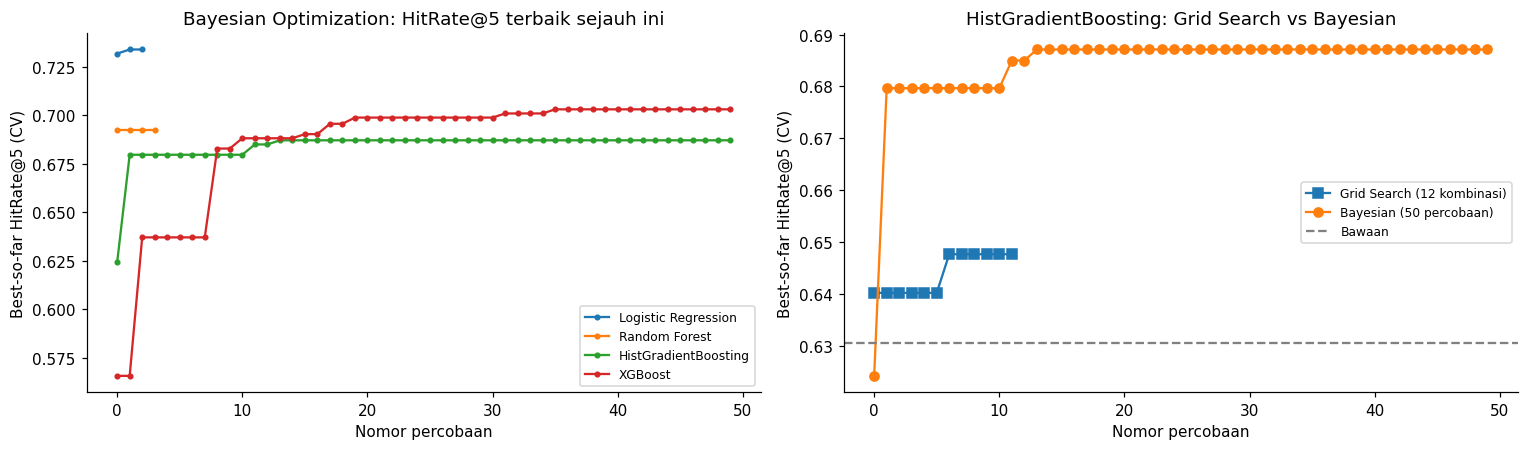

In [92]:
# 8.7 Ringkasan tuning (CV, data train)
tuning_df = pd.DataFrame(tuning_records)
tuning_df["CV HitRate@5 bawaan"] = tuning_df["Model"].map(lambda m: cv_default[m]["HitRate@5"])
tuning_df["Selisih vs bawaan"] = tuning_df["CV HitRate@5"] - tuning_df["CV HitRate@5 bawaan"]
display(tuning_df.drop(columns="Parameter").round(4))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
for (name, method), values in search_histories.items():
    if method.startswith("Bayesian"):
        axes[0].plot(np.maximum.accumulate(values), marker="o", ms=3, label=name)
axes[0].set_title("Bayesian Optimization: HitRate@5 terbaik sejauh ini")
axes[0].set_xlabel("Nomor percobaan")
axes[0].set_ylabel("Best-so-far HitRate@5 (CV)")
axes[0].legend(fontsize=8)

hgb_grid = search_histories.get(("HistGradientBoosting", "Grid Search"))
hgb_bayes = search_histories.get(("HistGradientBoosting", "Bayesian (Optuna TPE)"))
if hgb_grid is not None and hgb_bayes is not None:
    axes[1].plot(np.maximum.accumulate(hgb_grid), marker="s", label=f"Grid Search ({len(hgb_grid)} kombinasi)")
    axes[1].plot(np.maximum.accumulate(hgb_bayes), marker="o", label=f"Bayesian ({len(hgb_bayes)} percobaan)")
    axes[1].axhline(cv_default["HistGradientBoosting"]["HitRate@5"], color="grey", ls="--", label="Bawaan")
    axes[1].set_title("HistGradientBoosting: Grid Search vs Bayesian")
    axes[1].set_xlabel("Nomor percobaan")
    axes[1].set_ylabel("Best-so-far HitRate@5 (CV)")
    axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

### 9.1 Evaluasi semua varian pada Test data dan Test data segar

In [93]:
# 9.1 Evaluasi semua varian pada Test dan Test segar
def f1_threshold(y_true, proba):
    precision, recall, thresholds = precision_recall_curve(y_true, proba)
    f1 = 2 * precision[:-1] * recall[:-1] / np.clip(precision[:-1] + recall[:-1], 1e-12, None)
    return float(thresholds[np.argmax(f1)])


def hits_by_query(frame, scores, k=5):
    tmp = frame[["query_id", "label"]].assign(score=np.asarray(scores))
    tmp["rank"] = tmp.groupby("query_id")["score"].rank(ascending=False, method="first")
    ranks = (tmp.loc[tmp["label"] == 1].set_index("query_id")["rank"]
             .reindex(sorted(frame["query_id"].unique())).fillna(np.inf).to_numpy())
    return ranks <= k


fresh_queries = make_queries(test_idx, keep=0.5, n_noise=2, p_general=0.5, seed=99)
fresh_df = candidate_features(fresh_queries, test_idx)
EVAL_FRAMES = {"Test (seed 7)": test_df, "Test segar (seed 99)": fresh_df}

variants = {(name, "Default"): BUILDERS[name]() for name in DEFAULT_MODEL_NAMES}
for record in tuning_records:
    variants[(record["Model"], record["Metode"])] = BUILDERS[record["Model"]](**record["Parameter"])

cv_by_key, fitted_variants, threshold_by_key, proba_store, eval_rows = {}, {}, {}, {}, []
for key, estimator in variants.items():
    start = time.time()
    cv_score, oof_variant = cv_scores(estimator, return_oof=True)
    mask = ~np.isnan(oof_variant)
    is_ranker = isinstance(estimator, XGBQueryRanker)
    threshold = None if is_ranker else f1_threshold(y_train[mask], oof_variant[mask])
    fitted = clone(estimator).fit(X_tune, y_train)
    cv_by_key[key], fitted_variants[key], threshold_by_key[key] = cv_score, fitted, threshold
    for frame_name, frame in EVAL_FRAMES.items():
        y_frame = frame["label"].to_numpy()
        proba = fitted.predict_proba(frame[ML_FEATURES + ["query_id"]])[:, 1]
        proba_store[(key, frame_name)] = proba
        row = {"Model": key[0], "Metode": key[1], "Evaluasi": frame_name, "CV HitRate@5": cv_score["HitRate@5"],
               **rerank_metrics(frame, proba),
               "ROC-AUC": roc_auc_score(y_frame, proba), "PR-AUC": average_precision_score(y_frame, proba)}
        if threshold is not None:
            predicted = (proba >= threshold).astype(int)
            row.update({"Ambang": threshold, "Accuracy": accuracy_score(y_frame, predicted),
                        "Balanced Acc": balanced_accuracy_score(y_frame, predicted),
                        "Precision": precision_score(y_frame, predicted, zero_division=0),
                        "Recall": recall_score(y_frame, predicted), "F1": f1_score(y_frame, predicted)})
        eval_rows.append(row)
    print(f"{key[0]} | {key[1]} selesai ({time.time() - start:.0f} dtk)", flush=True)

eval_long = pd.DataFrame(eval_rows)
print("Ambang LogReg bawaan di sini vs bagian 6.2:",
      round(threshold_by_key[("Logistic Regression", "Default")], 4), "vs", round(thresholds_by_model["Logistic Regression"], 4))

Logistic Regression | Default selesai (8 dtk)
Random Forest | Default selesai (79 dtk)
HistGradientBoosting | Default selesai (15 dtk)
XGBoost | Default selesai (8 dtk)
ExtraTrees | Default selesai (47 dtk)
LTR XGBRanker | Default selesai (13 dtk)
Logistic Regression | Bayesian (Optuna TPE) selesai (23 dtk)
Random Forest | Bayesian (Optuna TPE) selesai (126 dtk)
HistGradientBoosting | Bayesian (Optuna TPE) selesai (12 dtk)
XGBoost | Bayesian (Optuna TPE) selesai (5 dtk)
Logistic Regression | Grid Search selesai (6 dtk)
HistGradientBoosting | Grid Search selesai (21 dtk)
Ambang LogReg bawaan di sini vs bagian 6.2: 0.9657 vs 0.9657


### 9.2 Tabel perbandingan (diurutkan menurut HitRate@5)

**Test (seed 7)**

CV HitRate@5  HitRate@5  \
Model                Metode                                           
Logistic Regression  Default                      0.7318     0.8562   
                     Bayesian (Optuna TPE)        0.7339     0.8562   
                     Grid Search                  0.7403     0.8562   
LTR XGBRanker        Default                      0.6264     0.8275   
XGBoost              Bayesian (Optuna TPE)        0.7031     0.8243   
Random Forest        Bayesian (Optuna TPE)        0.6924     0.8243   
HistGradientBoosting Bayesian (Optuna TPE)        0.6871     0.8211   
                     Default                      0.6307     0.8147   
ExtraTrees           Default                      0.6935     0.8147   
XGBoost              Default                      0.6115     0.8147   
Random Forest        Default                      0.6807     0.8115   
HistGradientBoosting Grid Search                  0.6477     0.8019   

                                            HitRate@10  MRR@10  NDCG@10  \
Model                Metode                                               
Logistic Regression  Default                    0.8786  0.7601   0.7892   
                     Bayesian (Optuna TPE)      0.8786  0.7572   0.7871   
                     Grid Search                0.8754  0.7611   0.7894   
LTR XGBRanker        Default                    0.8722  0.7311   0.7655   
XGBoost              Bayesian (Optuna TPE)      0.8658  0.7406   0.7711   
Random Forest        Bayesian (Optuna TPE)      0.8562  0.7191   0.7529   
HistGradientBoosting Bayesian (Optuna TPE)      0.8594  0.7320   0.7632   
                     Default                    0.8435  0.7082   0.7411   
ExtraTrees           Default                    0.8562  0.7163   0.7505   
XGBoost              Default                    0.8594  0.7145   0.7498   
Random Forest        Default                    0.8562  0.7220   0.7547   
HistGradientBoosting Grid Search                0.8435  0.7086   0.7413   

                                            ROC-AUC  PR-AUC  Accuracy  \
Model                Metode                                             
Logistic Regression  Default                 0.9776  0.7596    0.9902   
                     Bayesian (Optuna TPE)   0.9777  0.7584    0.9899   
                     Grid Search             0.9750  0.7769    0.9902   
LTR XGBRanker        Default                 0.9738  0.7417       NaN   
XGBoost              Bayesian (Optuna TPE)   0.9767  0.7411    0.9885   
Random Forest        Bayesian (Optuna TPE)   0.9676  0.6455    0.9794   
HistGradientBoosting Bayesian (Optuna TPE)   0.9733  0.7055    0.9885   
                     Default                 0.9618  0.6921    0.9861   
ExtraTrees           Default                 0.9644  0.6827    0.9855   
XGBoost              Default                 0.9694  0.6821    0.9800   
Random Forest        Default                 0.9628  0.6728    0.9835   
HistGradientBoosting Grid Search             0.9646  0.6729    0.9870   

                                            Balanced Acc  Precision  Recall  \
Model                Metode                                                   
Logistic Regression  Default                      0.7894     0.8450  0.5808   
                     Bayesian (Optuna TPE)        0.7892     0.8244  0.5808   
                     Grid Search                  0.8011     0.8186  0.6048   
LTR XGBRanker        Default                         NaN        NaN     NaN   
XGBoost              Bayesian (Optuna TPE)        0.8407     0.6920  0.6873   
Random Forest        Bayesian (Optuna TPE)        0.8749     0.4675  0.7663   
HistGradientBoosting Bayesian (Optuna TPE)        0.8323     0.6989  0.6701   
                     Default                      0.8311     0.6151  0.6701   
ExtraTrees           Default                      0.8308     0.5982  0.6701   
XGBoost              Default                      0.8684     0.4761  0.7526   
Random Forest        Defaul

**Test segar (seed 99)**

CV HitRate@5  HitRate@5  \
Model                Metode                                           
Logistic Regression  Default                      0.7318     0.8275   
                     Grid Search                  0.7403     0.8275   
                     Bayesian (Optuna TPE)        0.7339     0.8243   
LTR XGBRanker        Default                      0.6264     0.8179   
XGBoost              Default                      0.6115     0.8083   
HistGradientBoosting Bayesian (Optuna TPE)        0.6871     0.8051   
XGBoost              Bayesian (Optuna TPE)        0.7031     0.8019   
Random Forest        Bayesian (Optuna TPE)        0.6924     0.7955   
ExtraTrees           Default                      0.6935     0.7859   
HistGradientBoosting Grid Search                  0.6477     0.7859   
                     Default                      0.6307     0.7827   
Random Forest        Default                      0.6807     0.7827   

                                            HitRate@10  MRR@10  NDCG@10  \
Model                Metode                                               
Logistic Regression  Default                    0.8658  0.7363   0.7679   
                     Grid Search                0.8530  0.7342   0.7633   
                     Bayesian (Optuna TPE)      0.8594  0.7332   0.7642   
LTR XGBRanker        Default                    0.8403  0.7174   0.7475   
XGBoost              Default                    0.8371  0.7128   0.7431   
HistGradientBoosting Bayesian (Optuna TPE)      0.8403  0.6995   0.7338   
XGBoost              Bayesian (Optuna TPE)      0.8435  0.7085   0.7412   
Random Forest        Bayesian (Optuna TPE)      0.8371  0.7062   0.7378   
ExtraTrees           Default                    0.8339  0.6888   0.7240   
HistGradientBoosting Grid Search                0.8403  0.6988   0.7327   
                     Default                    0.8466  0.6927   0.7296   
Random Forest        Default                    0.8307  0.6942   0.7272   

                                            ROC-AUC  PR-AUC  Accuracy  \
Model                Metode                                             
Logistic Regression  Default                 0.9665  0.7086    0.9891   
                     Grid Search             0.9613  0.7298    0.9899   
                     Bayesian (Optuna TPE)   0.9663  0.7073    0.9893   
LTR XGBRanker        Default                 0.9603  0.6956       NaN   
XGBoost              Default                 0.9580  0.6559    0.9773   
HistGradientBoosting Bayesian (Optuna TPE)   0.9595  0.6747    0.9873   
XGBoost              Bayesian (Optuna TPE)   0.9598  0.7028    0.9877   
Random Forest        Bayesian (Optuna TPE)   0.9492  0.6235    0.9775   
ExtraTrees           Default                 0.9446  0.6555    0.9852   
HistGradientBoosting Grid Search             0.9522  0.6462    0.9863   
                     Default                 0.9508  0.6635    0.9847   
Random Forest        Default                 0.9415  0.6318    0.9826   

                                            Balanced Acc  Precision  Recall  \
Model                Metode                                                   
Logistic Regression  Default                      0.7864     0.7917  0.5758   
                     Grid Search                  0.8149     0.7932  0.6330   
                     Bayesian (Optuna TPE)        0.7948     0.7928  0.5926   
LTR XGBRanker        Default                         NaN        NaN     NaN   
XGBoost              Default                      0.8415     0.4388  0.7003   
HistGradientBoosting Bayesian (Optuna TPE)        0.8070     0.6840  0.6195   
XGBoost              Bayesian (Optuna TPE)        0.8121     0.6926  0.6296   
Random Forest        Bayesian (Optuna TPE)        0.8449     0.4421  0.7071   
ExtraTrees           Default                      0.8224     0.6006  0.6532   
HistGradientBoosting Grid Search                  0.8031     0.6454  0.6128   
                     Defaul

**Selisih hasil tuning terhadap parameter bawaan (positif = tuning membantu)**

Δ CV HitRate@5  Δ HitRate@5 Test  \
Model                Metode                                                    
HistGradientBoosting Bayesian (Optuna TPE)          0.0564            0.0064   
                     Grid Search                    0.0170           -0.0128   
Logistic Regression  Bayesian (Optuna TPE)          0.0021            0.0000   
                     Grid Search                    0.0085            0.0000   
Random Forest        Bayesian (Optuna TPE)          0.0117            0.0128   
XGBoost              Bayesian (Optuna TPE)          0.0916            0.0096   

                                            Δ HitRate@5 Test segar  \
Model                Metode                                          
HistGradientBoosting Bayesian (Optuna TPE)                  0.0224   
                     Grid Search                            0.0032   
Logistic Regression  Bayesian (Optuna TPE)                 -0.0032   
                     Grid Search                            0.0000   
Random Forest        Bayesian (Optuna TPE)                  0.0128   
XGBoost              Bayesian (Optuna TPE)                 -0.0064   

                                            Δ PR-AUC Test segar  
Model                Metode                                      
HistGradientBoosting Bayesian (Optuna TPE)               0.0112  
                     Grid Search                        -0.0173  
Logistic Regression  Bayesian (Optuna TPE)              -0.0013  
                     Grid Search                         0.0213  
Random Forest        Bayesian (Optuna TPE)              -0.0082  
XGBoost              Bayesian (Optuna TPE)               0.0468

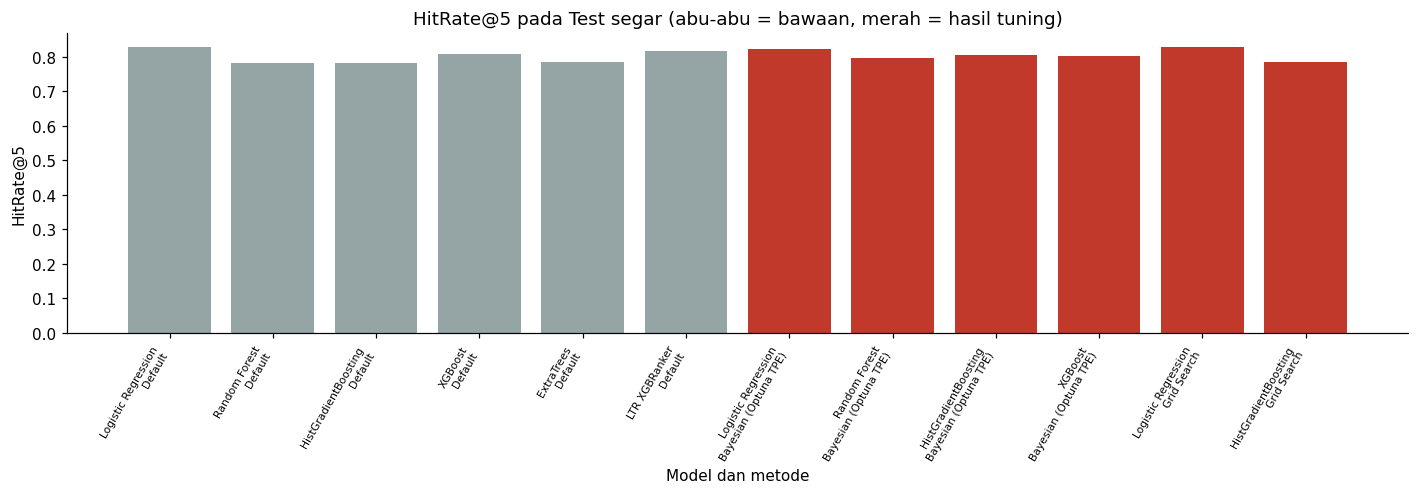

In [94]:
# 9.2 Tabel perbandingan (diurutkan menurut HitRate@5)
metric_columns = ["CV HitRate@5", "HitRate@5", "HitRate@10", "MRR@10", "NDCG@10", "ROC-AUC", "PR-AUC",
                  "Accuracy", "Balanced Acc", "Precision", "Recall", "F1"]
for frame_name in EVAL_FRAMES:
    display(Markdown(f"**{frame_name}**"))
    table = (eval_long[eval_long["Evaluasi"] == frame_name]
             .set_index(["Model", "Metode"])[metric_columns]
             .sort_values("HitRate@5", ascending=False))
    display(table.round(4))

wide = eval_long.pivot_table(index=["Model", "Metode"], columns="Evaluasi", values=["HitRate@5", "PR-AUC"])
delta_rows = []
for (model_name, method), row in wide.iterrows():
    if method == "Default":
        continue
    base = wide.loc[(model_name, "Default")]
    delta_rows.append({
        "Model": model_name, "Metode": method,
        "Δ CV HitRate@5": cv_by_key[(model_name, method)]["HitRate@5"] - cv_by_key[(model_name, "Default")]["HitRate@5"],
        "Δ HitRate@5 Test": row[("HitRate@5", "Test (seed 7)")] - base[("HitRate@5", "Test (seed 7)")],
        "Δ HitRate@5 Test segar": row[("HitRate@5", "Test segar (seed 99)")] - base[("HitRate@5", "Test segar (seed 99)")],
        "Δ PR-AUC Test segar": row[("PR-AUC", "Test segar (seed 99)")] - base[("PR-AUC", "Test segar (seed 99)")]})
delta_table = pd.DataFrame(delta_rows).set_index(["Model", "Metode"])
display(Markdown("**Selisih hasil tuning terhadap parameter bawaan (positif = tuning membantu)**"))
display(delta_table.round(4))

plot_frame = eval_long[eval_long["Evaluasi"] == "Test segar (seed 99)"]
labels = [f"{m}\n{me}" for m, me in zip(plot_frame["Model"], plot_frame["Metode"])]
fig, ax = plt.subplots(figsize=(13, 4.6))
ax.bar(range(len(plot_frame)), plot_frame["HitRate@5"],
       color=["#95a5a6" if m == "Default" else "#c0392b" for m in plot_frame["Metode"]])
ax.set_xticks(range(len(plot_frame)), labels, rotation=60, ha="right", fontsize=7)
ax.set_title("HitRate@5 pada Test segar (abu-abu = bawaan, merah = hasil tuning)")
ax.set_xlabel("Model dan metode")
ax.set_ylabel("HitRate@5")
plt.tight_layout()
plt.show()

### 10.1 Pemilihan model terbaik dan uji berpasangan

Model terbaik hasil tuning : ('Logistic Regression', 'Grid Search') | parameter: {'C': 0.1, 'class_weight': None}
Model bawaan terbaik       : ('Logistic Regression', 'Default')
Terbaik keseluruhan (CV)   : ('Logistic Regression', 'Grid Search')


Δ HitRate@5  \
Evaluasi             A vs B                                                
Test (seed 7)        Tuned terbaik vs bawaan terbaik              0.0000   
                     Tuned terbaik vs M3 (tanpa re-ranking)       0.0447   
Test segar (seed 99) Tuned terbaik vs bawaan terbaik              0.0000   
                     Tuned terbaik vs M3 (tanpa re-ranking)       0.0831   

                                                            CI 95% bootstrap  \
Evaluasi             A vs B                                                    
Test (seed 7)        Tuned terbaik vs bawaan terbaik          [0.000, 0.000]   
                     Tuned terbaik vs M3 (tanpa re-ranking)   [0.016, 0.073]   
Test segar (seed 99) Tuned terbaik vs bawaan terbaik         [-0.010, 0.010]   
                     Tuned terbaik vs M3 (tanpa re-ranking)   [0.051, 0.118]   

                                                             Hanya A benar  \
Evaluasi             A vs B                                                  
Test (seed 7)        Tuned terbaik vs bawaan terbaik                     0   
                     Tuned terbaik vs M3 (tanpa re-ranking)             18   
Test segar (seed 99) Tuned terbaik vs bawaan terbaik                     1   
                     Tuned terbaik vs M3 (tanpa re-ranking)             28   

                                                             Hanya B benar  \
Evaluasi             A vs B                                                  
Test (seed 7)        Tuned terbaik vs bawaan terbaik                     0   
                     Tuned terbaik vs M3 (tanpa re-ranking)              4   
Test segar (seed 99) Tuned terbaik vs bawaan terbaik                     1   
                     Tuned terbaik vs M3 (tanpa re-ranking)              2   

                                                             McNemar p  \
Evaluasi             A vs B                                              
Test (seed 7)        Tuned terbaik vs bawaan terbaik            1.0000   
                     Tuned terbaik vs M3 (tanpa re-ranking)     0.0043   
Test segar (seed 99) Tuned terbaik vs bawaan terbaik            1.0000   
                     Tuned terbaik vs M3 (tanpa re-ranking)     0.0000   

                                                                  Keputusan  
Evaluasi             A vs B                                                  
Test (seed 7)        Tuned terbaik vs bawaan terbaik         Gagal tolak H0  
                     Tuned terbaik vs M3 (tanpa re-ranking)        Tolak H0  
Test segar (seed 99) Tuned terbaik vs bawaan terbaik         Gagal tolak H0  
                     Tuned terbaik vs M3 (tanpa re-ranking)        Tolak H0

**Metrik model terbaik hasil tuning**

,CV HitRate@5,HitRate@5,HitRate@10,MRR@10,NDCG@10,ROC-AUC,PR-AUC,Accuracy,Balanced Acc,Precision,Recall,F1,Ambang
Evaluasi,,,,,,,,,,,,,
Test (seed 7),0.7403,0.8562,0.8754,0.7611,0.7894,0.9750,0.7769,0.9902,0.8011,0.8186,0.6048,0.6957,0.3349
Test segar (seed 99),0.7403,0.8275,0.8530,0.7342,0.7633,0.9613,0.7298,0.9899,0.8149,0.7932,0.6330,0.7041,0.3349


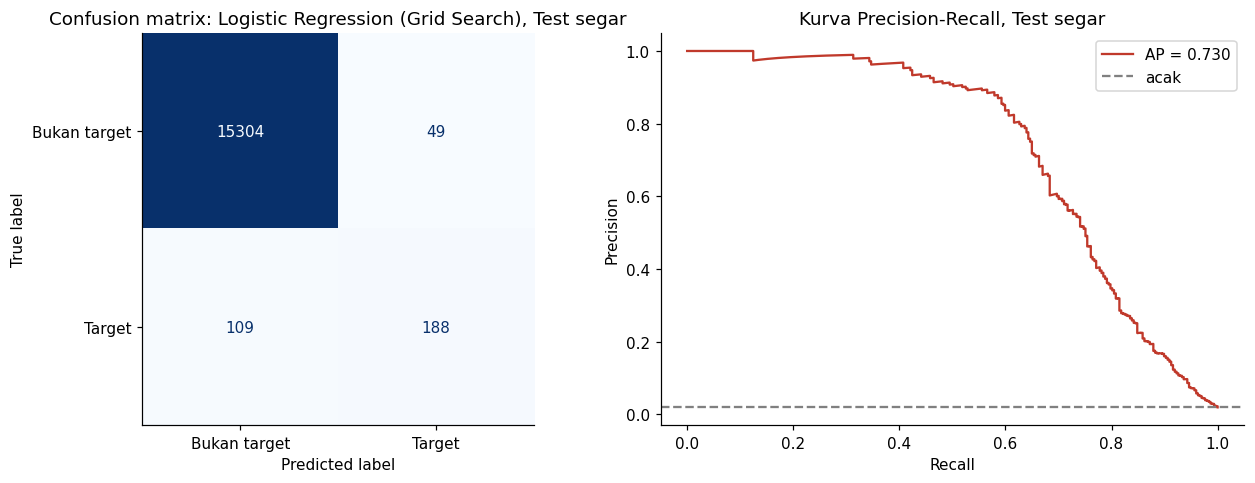

In [95]:
# 10.1 Model terbaik: dipilih dari CV train, test hanya untuk konfirmasi
def rank_keys(keys):
    return sorted(keys, key=lambda k: (cv_by_key[k]["HitRate@5"], cv_by_key[k]["PR-AUC"]), reverse=True)


tuned_keys = [k for k in variants if k[1] != "Default"]
default_keys = [k for k in variants if k[1] == "Default"]
best_tuned_key = rank_keys(tuned_keys)[0]
best_default_key = rank_keys(default_keys)[0]
overall_best_key = rank_keys(list(variants))[0]
best_tuned_record = next(r for r in tuning_records if (r["Model"], r["Metode"]) == best_tuned_key)

print("Model terbaik hasil tuning :", best_tuned_key, "| parameter:", best_tuned_record["Parameter"])
print("Model bawaan terbaik       :", best_default_key)
print("Terbaik keseluruhan (CV)   :", overall_best_key)


def paired_comparison(hits_a, hits_b):
    only_a, only_b = int((hits_a & ~hits_b).sum()), int((~hits_a & hits_b).sum())
    p_value = stats.binomtest(only_a, only_a + only_b, 0.5).pvalue if only_a + only_b else 1.0
    return {"Δ HitRate@5": hits_a.mean() - hits_b.mean(),
            "CI 95% bootstrap": fmt_ci(bootstrap_ci(hits_a.astype(int) - hits_b.astype(int))),
            "Hanya A benar": only_a, "Hanya B benar": only_b, "McNemar p": p_value, "Keputusan": verdict(p_value)}


comparison_rows = []
for frame_name, frame in EVAL_FRAMES.items():
    hits_tuned = hits_by_query(frame, proba_store[(best_tuned_key, frame_name)])
    hits_default = hits_by_query(frame, proba_store[(best_default_key, frame_name)])
    hits_m3 = hits_by_query(frame, -frame["m3_rank"])
    comparison_rows.append({"Evaluasi": frame_name, "A vs B": "Tuned terbaik vs bawaan terbaik",
                            **paired_comparison(hits_tuned, hits_default)})
    comparison_rows.append({"Evaluasi": frame_name, "A vs B": "Tuned terbaik vs M3 (tanpa re-ranking)",
                            **paired_comparison(hits_tuned, hits_m3)})
display(pd.DataFrame(comparison_rows).set_index(["Evaluasi", "A vs B"]).round(4))

best_row = eval_long[(eval_long["Model"] == best_tuned_key[0]) & (eval_long["Metode"] == best_tuned_key[1])]
display(Markdown("**Metrik model terbaik hasil tuning**"))
display(best_row.set_index("Evaluasi")[metric_columns + ["Ambang"]].round(4))

best_tuned_threshold = threshold_by_key[best_tuned_key]
if best_tuned_threshold is not None:
    y_fresh = fresh_df["label"].to_numpy()
    proba_fresh = proba_store[(best_tuned_key, "Test segar (seed 99)")]
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    ConfusionMatrixDisplay(confusion_matrix(y_fresh, (proba_fresh >= best_tuned_threshold).astype(int)),
                           display_labels=["Bukan target", "Target"]).plot(
        ax=axes[0], cmap="Blues", colorbar=False, values_format="d")
    axes[0].set_title(f"Confusion matrix: {best_tuned_key[0]} ({best_tuned_key[1]}), Test segar")
    precision_curve, recall_curve, _ = precision_recall_curve(y_fresh, proba_fresh)
    axes[1].plot(recall_curve, precision_curve, color="#c0392b",
                 label=f"AP = {average_precision_score(y_fresh, proba_fresh):.3f}")
    axes[1].axhline(y_fresh.mean(), color="grey", ls="--", label="acak")
    axes[1].set_title("Kurva Precision-Recall, Test segar")
    axes[1].set_xlabel("Recall")
    axes[1].set_ylabel("Precision")
    axes[1].legend()
    plt.tight_layout()
    plt.show()
else:
    print("Model terbaik berupa ranker: threshold klasifikasi tidak didefinisikan (evaluasi memakai metrik ranking).")

### 10.2 Kesimpulan terukur (dihitung dari hasil, bukan teks tetap)

In [96]:
# 10.2 Kesimpulan terukur (dihitung dari hasil, bukan teks tetap)
fresh_best = eval_long[(eval_long["Model"] == best_tuned_key[0]) & (eval_long["Metode"] == best_tuned_key[1])
                       & (eval_long["Evaluasi"] == "Test segar (seed 99)")].iloc[0]
fresh_default = eval_long[(eval_long["Model"] == best_default_key[0]) & (eval_long["Metode"] == best_default_key[1])
                          & (eval_long["Evaluasi"] == "Test segar (seed 99)")].iloc[0]
gain_cv = cv_by_key[best_tuned_key]["HitRate@5"] - cv_by_key[best_default_key]["HitRate@5"]
gain_fresh = fresh_best["HitRate@5"] - fresh_default["HitRate@5"]
tuning_helped = "membantu" if gain_fresh > 0 else "tidak membantu"
display(Markdown(
    f"**Hasil tuning:** model terbaik hasil tuning adalah **{best_tuned_key[0]}** ({best_tuned_key[1]}). "
    f"CV HitRate@5 = {cv_by_key[best_tuned_key]['HitRate@5']:.4f} (selisih {gain_cv:+.4f} terhadap model bawaan terbaik "
    f"{best_default_key[0]}). Pada Test segar HitRate@5 = {fresh_best['HitRate@5']:.4f} vs {fresh_default['HitRate@5']:.4f}; "
    f"PR-AUC = {fresh_best['PR-AUC']:.4f} vs {fresh_default['PR-AUC']:.4f}. Pada data ini tuning **{tuning_helped}** "
    "model terbaik secara keseluruhan. Skor CV hasil tuning optimistis karena parameter dipilih pada CV yang sama, "
    "sehingga keputusan akhir bergantung pada uji berpasangan di atas. Perbedaan yang tidak signifikan berarti model yang "
    "lebih sederhana (bawaan) layak dipertahankan."
))

**Hasil tuning:** model terbaik hasil tuning adalah **Logistic Regression** (Grid Search). CV HitRate@5 = 0.7403 (selisih +0.0085 terhadap model bawaan terbaik Logistic Regression). Pada Test segar HitRate@5 = 0.8275 vs 0.8275; PR-AUC = 0.7298 vs 0.7086. Pada data ini tuning **tidak membantu** model terbaik secara keseluruhan. Skor CV hasil tuning optimistis karena parameter dipilih pada CV yang sama, sehingga keputusan akhir bergantung pada uji berpasangan di atas. Perbedaan yang tidak signifikan berarti model yang lebih sederhana (bawaan) layak dipertahankan.

## 11. Rencana penggunaan

Notebook sudah menyediakan fungsi `recommend_from_pantry`. Aplikasi Streamlit hanya rencana, belum dibuat di proyek ini. Jika ingin dipakai, simpan model dan katalog, lalu pantau kualitas rekomendasi, waktu respons, dan perubahan data.


In [97]:
EXPORT_FILES = False
export = recipes[[
    "recipe_title","category","subcategory","description","ingredients","directions",
    "dish_group","est_prep_time_min","est_cook_time_min","difficulty","ingredient_count"
]].copy()
export["ingredient_list_normalized"] = recipes["ingredient_list"].map(
    lambda items:json.dumps(items,ensure_ascii=False)
)
if EXPORT_FILES:
    import joblib
    export_dir = Path("output") / "uts_audited"
    export_dir.mkdir(parents=True,exist_ok=True)
    export.to_csv(export_dir/"recipes_italia_final.csv",index=False,encoding="utf-8-sig")
    test_results.to_csv(export_dir/"evaluation_results.csv",index=False)
    ml_test_results.to_csv(export_dir/"ml_evaluation_results.csv")
    (export_dir/"best_params.json").write_text(json.dumps(best_params,indent=2),encoding="utf-8")
    joblib.dump({"M3":m3_best,"M4":best_model,"threshold":best_threshold,
                 "features":ML_FEATURES,"dataset_sha256":dataset_sha256},
                export_dir/"model_bundle.joblib")
    print("Ekspor:",export_dir.resolve())
    print("Custom class perlu definisi notebook/modul yang sama sebelum memuat joblib.")
else:
    print("Ekspor tambahan nonaktif; tabel, grafik dan hasil audit tersimpan di notebook.")
display(export.head(3))


Ekspor tambahan nonaktif; tabel, grafik dan hasil audit tersimpan di notebook.


,recipe_title,category,subcategory,description,ingredients,directions,dish_group,est_prep_time_min,est_cook_time_min,difficulty,ingredient_count,ingredient_list_normalized
0,Stuffed Cherry Peppers,Antipasti,Antipasti,Fresh hot cherry peppers stuffed with prosciutto and provolone cheese are so...,"[""1 cup extra virgin olive oil"", ""12 fresh cherry peppers"", ""6 ounces sharp ...","[""Slice the tops off of the cherry peppers and carefully remove the seeds, k...",Antipasti,11,28,Medium,5,"[""olive oil"", ""cherry pepper"", ""sharp provolone cheese"", ""prosciutto"", ""salt""]"
1,Mediterranean Flatbread,Antipasti,Antipasti,"These Mediterranean flatbreads are packed with fresh flavor, piled with toma...","[""2 flatbreads"", ""1/4 cup extra-virgin olive oil"", ""3 garlic cloves,"", ""2 cu...","[""Preheat the oven to 425 degrees F (220 degrees C)."", ""Combine olive oil an...",Antipasti,17,32,Medium,9,"[""flatbread"", ""olive oil"", ""garlic"", ""cherry"", ""kalamata olive"", ""red onion""..."
2,Best Caprese Skewers,Antipasti,Antipasti,These colorful caprese skewers with bite-sized portions of mozzarella cheese...,"[""20 cherry tomatoes"", ""10 ounces mozzarella cheese, cubed"", ""2 tablespoons ...","[""Gather all ingredients."", ""Toss tomatoes, mozzarella, olive oil, basil, sa...",Antipasti,10,14,Easy,7,"[""cherry tomato"", ""mozzarella"", ""olive oil"", ""basil"", ""salt"", ""black pepper""..."


## 12. Kesimpulan

1. Data awal 62,126 baris; katalog akhir 1,565 resep dan 1,628 istilah bahan.
2. Parameter M3 dipilih hanya pada validasi: {'mode': 'both', 'use_idf': False, 'drop_staples': False, 'alpha': 1.0}.
3. Model M4 pilihan CV: Logistic Regression; HitRate@5 test M3=0.8115, M4=0.8562; Delta=+0.0447, CI 95%=[0.016, 0.077].
4. Matriks tabular Q1 terpilih: (1565, 21); fit statistik dilakukan pada train.
5. Hasil merupakan simulasi satu resep asal per query dalam katalog yang diketahui. Belum membuktikan preferensi, penghematan uang, atau pengurangan limbah pengguna nyata.
6. Jika output berbeda dari laporan PDF lama, laporan perlu diperbarui berdasarkan hasil versi ini.